In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sheet_id = "1ifPzPLPlbjOYn27rnU2XKKqhyvjH5bL_"

url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (234902, 25)


In [33]:
df.head()

,Unnamed: 0,axial_force,bending_moment_x,bending_moment_y,torsion,vibration1,vibration2,spindle_power,spindle_current,timestamp,...,experiment_csv_n,feed_per_tooth,spindle_speed,axial_cutting_depth,tool_wear,dataset_tag,vibration_x,vibration_y,force_z,tool_wear_increment
0,0,150.7300,1.09360,-22.499,22.779,4.0570,4.2318,2.4841,1.0227,0.0033,...,1,0.045,1750,2.5,0.117595,nuaa,4.0570,4.2318,150.7300,0.000000
1,1,7.1774,3.15220,-14.678,-24.492,-3.0655,-2.8028,2.4841,1.0227,0.0693,...,1,0.045,1750,2.5,0.117601,nuaa,-3.0655,-2.8028,7.1774,0.000006
2,2,21.5320,5.72550,-28.847,38.992,-0.4254,-0.0328,2.4841,1.0227,0.1353,...,1,0.045,1750,2.5,0.117608,nuaa,-0.4254,-0.0328,21.5320,0.000006
3,3,-50.2420,4.95350,-31.454,52.009,4.7657,5.1230,2.4841,1.0227,0.2013,...,1,0.045,1750,2.5,0.117614,nuaa,4.7657,5.1230,-50.2420,0.000006
4,4,7.1774,0.32166,-15.812,-38.764,-3.6008,-3.5635,2.4841,1.0227,0.2673,...,1,0.045,1750,2.5,0.117620,nuaa,-3.6008,-3.5635,7.1774,0.000006


In [34]:
print(df.shape)

(234902, 25)


In [35]:
print(df.shape)

(234902, 25)


In [36]:
missing = df.isnull().sum()

print("Missing values:")
print(missing[missing > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values:
bending_moment_x    149
bending_moment_y    149
torsion             149
dtype: int64

Total missing values: 447


In [37]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [38]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,234902.0,17710.404901,13343.481752,0.000000e+00,6.525000e+03,14501.000000,27310.000000,50375.000000
axial_force,234902.0,121.184867,198.373525,-9.043500e+02,-7.177400e+00,122.020000,258.390000,1055.100000
bending_moment_x,234753.0,0.895446,2.233836,-9.263700e+00,-4.503200e-01,1.029300,2.380200,10.100000
bending_moment_y,234753.0,-6.508967,26.317859,-1.014400e+02,-1.949600e+01,-1.190100,7.254100,89.487000
torsion,234753.0,5.090544,26.289898,-8.877500e+01,-9.248600e+00,1.084700,21.637000,116.460000
vibration1,234902.0,1.491919,4.994587,-2.695700e+01,-1.118525e+00,1.139200,4.199600,74.631000
vibration2,234902.0,2.039138,4.431374,-2.683600e+01,-9.689000e-01,2.289400,4.990600,30.627000
spindle_power,234902.0,2.175776,0.268439,1.513700e+00,1.995800e+00,2.148400,2.307100,3.472900
spindle_current,234902.0,0.047026,1.361660,-3.367100e+00,-1.408400e+00,0.175500,1.425700,3.787500
timestamp,234902.0,1168.526413,880.365344,3.300000e-03,4.304998e+02,956.802000,1801.889925,3323.740200


In [39]:
print("Experiment tags:")
print(df['experiment_tag'].value_counts().sort_index())

Experiment tags:
experiment_tag
W1    44029
W2    25953
W3    19408
W4    46253
W5     9917
W6    18441
W7    11956
W8    50376
W9     8569
Name: count, dtype: int64


In [40]:
print("Tool wear statistics:")
print(df['tool_wear'].describe())

print("\nUnique tool_wear values:", df['tool_wear'].nunique())

Tool wear statistics:
count    234902.000000
mean          0.181815
std           0.072128
min           0.049035
25%           0.120000
50%           0.197314
75%           0.230127
max           0.312748
Name: tool_wear, dtype: float64

Unique tool_wear values: 179512


In [41]:
print("Phasse 2 :-")

Phasse 2 :-


In [42]:
for i, col in enumerate(df.columns):
    print(i, "→", col)

0 → Unnamed: 0
1 → axial_force
2 → bending_moment_x
3 → bending_moment_y
4 → torsion
5 → vibration1
6 → vibration2
7 → spindle_power
8 → spindle_current
9 → timestamp
10 → wear_blade_1
11 → wear_blade_2
12 → wear_blade_3
13 → wear_blade_4
14 → experiment_tag
15 → experiment_csv_n
16 → feed_per_tooth
17 → spindle_speed
18 → axial_cutting_depth
19 → tool_wear
20 → dataset_tag
21 → vibration_x
22 → vibration_y
23 → force_z
24 → tool_wear_increment


PHASE-3


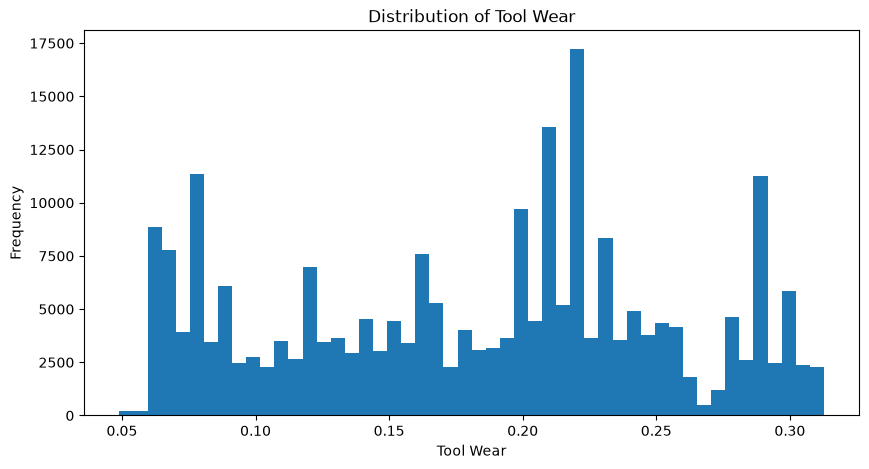

In [43]:
print("PHASE-3")
plt.figure(figsize=(10, 5))

plt.hist(df['tool_wear'].dropna(), bins=50)

plt.xlabel('Tool Wear')
plt.ylabel('Frequency')
plt.title('Distribution of Tool Wear')

plt.show()

In [44]:
missing_rows = df[df[['bending_moment_x', 'bending_moment_y', 'torsion']].isnull()]

print("Rows containing missing sensor values:")
print(missing_rows[['experiment_tag', 'experiment_csv_n', 'timestamp']].head(20))

print("\nMissing values by experiment:")
print(
    missing_rows['experiment_tag']
    .value_counts()
    .sort_index()
)

Rows containing missing sensor values:
   experiment_tag  experiment_csv_n  timestamp
0             NaN               NaN        NaN
1             NaN               NaN        NaN
2             NaN               NaN        NaN
3             NaN               NaN        NaN
4             NaN               NaN        NaN
5             NaN               NaN        NaN
6             NaN               NaN        NaN
7             NaN               NaN        NaN
8             NaN               NaN        NaN
9             NaN               NaN        NaN
10            NaN               NaN        NaN
11            NaN               NaN        NaN
12            NaN               NaN        NaN
13            NaN               NaN        NaN
14            NaN               NaN        NaN
15            NaN               NaN        NaN
16            NaN               NaN        NaN
17            NaN               NaN        NaN
18            NaN               NaN        NaN
19            NaN    

In [45]:
print("\nMissing values by column and experiment:")

for col in ['bending_moment_x', 'bending_moment_y', 'torsion']:
    print(f"\n{col}")
    print(
        df[df[col].isnull()]
        .groupby('experiment_tag')
        .size()
    )


Missing values by column and experiment:

bending_moment_x
experiment_tag
W2    149
dtype: int64

bending_moment_y
experiment_tag
W2    149
dtype: int64

torsion
experiment_tag
W2    149
dtype: int64


In [46]:
# Inspect the rows with missing sensor values
cols_to_check = [
    'bending_moment_x',
    'bending_moment_y',
    'torsion'
]

missing_rows = df[df[cols_to_check].isnull().any(axis=1)]

print("Number of affected rows:", len(missing_rows))

print("\nHow many columns are completely empty in these rows?")
print(missing_rows.isnull().sum(axis=1).value_counts().sort_index())

print("\nSample of affected rows:")
display(missing_rows.head(10))

Number of affected rows: 149

How many columns are completely empty in these rows?
3    149
Name: count, dtype: int64

Sample of affected rows:


,Unnamed: 0,axial_force,bending_moment_x,bending_moment_y,torsion,vibration1,vibration2,spindle_power,spindle_current,timestamp,...,experiment_csv_n,feed_per_tooth,spindle_speed,axial_cutting_depth,tool_wear,dataset_tag,vibration_x,vibration_y,force_z,tool_wear_increment
66432,22403,100.480,NaN,NaN,NaN,4.8409,5.7392,1.9653,-0.8710,1478.2053,...,15,0.045,1800,3.0,0.187240,nuaa,4.8409,5.7392,100.480,0.000020
66433,22404,315.810,NaN,NaN,NaN,-2.0156,-1.4129,1.9714,-0.8754,1478.2713,...,15,0.045,1800,3.0,0.187260,nuaa,-2.0156,-1.4129,315.810,0.000020
66434,22405,258.390,NaN,NaN,NaN,0.2493,0.8038,1.9714,-0.8754,1478.3373,...,15,0.045,1800,3.0,0.187279,nuaa,0.2493,0.8038,258.390,0.000020
66435,22406,315.810,NaN,NaN,NaN,-3.4723,-2.7623,1.9714,-0.8754,1478.4033,...,15,0.045,1800,3.0,0.187299,nuaa,-3.4723,-2.7623,315.810,0.000019
66436,22407,114.840,NaN,NaN,NaN,2.2380,2.8773,1.9775,-0.8840,1478.4693,...,15,0.045,1800,3.0,0.187318,nuaa,2.2380,2.8773,114.840,0.000019
66437,22408,459.350,NaN,NaN,NaN,4.5620,5.2483,1.9775,-0.8840,1478.5353,...,15,0.045,1800,3.0,0.187338,nuaa,4.5620,5.2483,459.350,0.000019
66438,22409,0.000,NaN,NaN,NaN,-2.0606,-1.4868,1.9775,-0.8840,1478.6013,...,15,0.045,1800,3.0,0.187357,nuaa,-2.0606,-1.4868,0.000,0.000019
66439,22410,416.290,NaN,NaN,NaN,5.0484,5.7758,1.9775,-0.8840,1478.6673,...,15,0.045,1800,3.0,0.187376,nuaa,5.0484,5.7758,416.290,0.000019
66440,22411,43.064,NaN,NaN,NaN,3.5969,4.4521,1.9775,-0.8840,1478.7333,...,15,0.045,1800,3.0,0.187396,nuaa,3.5969,4.4521,43.064,0.000019
66441,22412,172.260,NaN,NaN,NaN,1.2073,1.7657,1.9775,-0.8840,1478.7993,...,15,0.045,1800,3.0,0.187415,nuaa,1.2073,1.7657,172.260,0.000019


In [47]:
print("Target values in affected rows:")
print(missing_rows['tool_wear'].describe())

print("\nExperiment tags:")
print(missing_rows['experiment_tag'].value_counts(dropna=False))

print("\nDataset tags:")
print(missing_rows['dataset_tag'].value_counts(dropna=False))

Target values in affected rows:
count    149.000000
mean       0.188576
std        0.000753
min        0.187240
25%        0.187939
50%        0.188596
75%        0.189224
max        0.189835
Name: tool_wear, dtype: float64

Experiment tags:
experiment_tag
W2    149
Name: count, dtype: int64

Dataset tags:
dataset_tag
nuaa    149
Name: count, dtype: int64


In [48]:
print("PHASE 4 — Data Cleaning & Feature Preparation")
# Remove rows where the target is missing
df_clean = df.dropna(subset=['tool_wear']).copy()

print("Rows after removing missing target:", len(df_clean))

PHASE 4 — Data Cleaning & Feature Preparation
Rows after removing missing target: 234902


In [49]:
sensor_missing_cols = [
    'bending_moment_x',
    'bending_moment_y',
    'torsion'
]

# Sort by experiment/run and timestamp so interpolation follows the machining sequence
df_clean = df_clean.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).copy()

# Interpolate sensor values within each experimental run
df_clean[sensor_missing_cols] = (
    df_clean.groupby(['experiment_tag', 'experiment_csv_n'])[sensor_missing_cols]
    .transform(lambda x: x.interpolate(method='linear', limit_direction='both'))
)

print("Missing sensor values after interpolation:")
print(df_clean[sensor_missing_cols].isnull().sum())

Missing sensor values after interpolation:
bending_moment_x    0
bending_moment_y    0
torsion             0
dtype: int64


In [50]:
print("Total remaining missing values:",
      df_clean[sensor_missing_cols].isnull().sum().sum())

Total remaining missing values: 0


In [51]:
before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

print("Duplicate rows removed:", before - len(df_clean))
print("Current dataset shape:", df_clean.shape)

Duplicate rows removed: 0
Current dataset shape: (234902, 25)


In [52]:
numeric_cols = [
    'axial_force',
    'bending_moment_x',
    'bending_moment_y',
    'torsion',
    'vibration1',
    'vibration2',
    'spindle_power',
    'spindle_current',
    'feed_per_tooth',
    'spindle_speed',
    'axial_cutting_depth',
    'tool_wear'
]

outlier_summary = {}

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    outlier_summary[col] = count

outlier_summary = pd.Series(outlier_summary).sort_values(ascending=False)

print("Potential outliers by feature:")
print(outlier_summary)

Potential outliers by feature:
bending_moment_y       15030
spindle_power           8162
torsion                 4464
bending_moment_x        4098
vibration1              2348
axial_force             1910
vibration2               479
spindle_current            0
feed_per_tooth             0
spindle_speed              0
axial_cutting_depth        0
tool_wear                  0
dtype: int64


In [53]:
feature_cols = [
    'axial_force',
    'bending_moment_x',
    'bending_moment_y',
    'torsion',
    'vibration1',
    'vibration2',
    'spindle_power',
    'spindle_current',
    'vibration_x',
    'vibration_y',
    'force_z',
    'feed_per_tooth',
    'spindle_speed',
    'axial_cutting_depth'
]

target_col = 'tool_wear'

X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

print("Features:", len(feature_cols))
print("X shape:", X.shape)
print("Target:", target_col)
print("y shape:", y.shape)

Features: 14
X shape: (234902, 14)
Target: tool_wear
y shape: (234902,)


In [54]:
print("========== FINAL DATA CHECK ==========")

print("Dataset shape:", df_clean.shape)

print("\nTotal missing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nTarget missing:")
print(df_clean['tool_wear'].isnull().sum())

print("\nExperiment groups:")
print(sorted(df_clean['experiment_tag'].dropna().unique()))

print("\nFeatures used:", len(feature_cols))

========== FINAL DATA CHECK ==========
Dataset shape: (234902, 25)

Total missing values:
0

Duplicate rows:
0

Target missing:
0

Experiment groups:
['W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9']

Features used: 14


In [55]:
print("Phase 5: Feature Verification & Train/Test Split")
print("axial_force == force_z:",
      (df_clean['axial_force'] == df_clean['force_z']).all())

print("vibration1 == vibration_x:",
      (df_clean['vibration1'] == df_clean['vibration_x']).all())

print("vibration2 == vibration_y:",
      (df_clean['vibration2'] == df_clean['vibration_y']).all())

Phase 5: Feature Verification & Train/Test Split
axial_force == force_z: True
vibration1 == vibration_x: True
vibration2 == vibration_y: True


In [56]:
# Final model input features
feature_cols = [
    'axial_force',
    'bending_moment_x',
    'bending_moment_y',
    'torsion',
    'vibration1',
    'vibration2',
    'spindle_power',
    'spindle_current',
    'vibration_x',
    'vibration_y',
    'force_z',
    'feed_per_tooth',
    'spindle_speed',
    'axial_cutting_depth'
]

target_col = 'tool_wear'

X = df_clean[feature_cols].copy()
y = df_clean[target_col].copy()

print("Number of input features:", len(feature_cols))
print("X shape:", X.shape)
print("y shape:", y.shape)

Number of input features: 14
X shape: (234902, 14)
y shape: (234902,)


In [57]:
# PHASE 5: Leakage-Safe Train/Test Split

# Sort data by experiment and time
df_model = df_clean.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

# Create chronological 80/20 split within each experiment/run
df_model['row_number'] = df_model.groupby(
    ['experiment_tag', 'experiment_csv_n']
).cumcount()

df_model['run_size'] = df_model.groupby(
    ['experiment_tag', 'experiment_csv_n']
)['tool_wear'].transform('size')

df_model['train_cutoff'] = (df_model['run_size'] * 0.80).astype(int)

train_mask = df_model['row_number'] < df_model['train_cutoff']

train_df = df_model[train_mask].copy()
test_df = df_model[~train_mask].copy()

print("PHASE 5: Leakage-Safe Train/Test Split")
print("----------------------------------------")
print("Total samples :", len(df_model))
print("Training samples:", len(train_df))
print("Testing samples :", len(test_df))

print("\nTraining percentage:",
      round(len(train_df) / len(df_model) * 100, 2), "%")

print("Testing percentage:",
      round(len(test_df) / len(df_model) * 100, 2), "%")

print("\nTraining experiments:",
      sorted(train_df['experiment_tag'].unique()))

print("Testing experiments:",
      sorted(test_df['experiment_tag'].unique()))

PHASE 5: Leakage-Safe Train/Test Split
----------------------------------------
Total samples : 234902
Training samples: 187858
Testing samples : 47044

Training percentage: 79.97 %
Testing percentage: 20.03 %

Training experiments: ['W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9']
Testing experiments: ['W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9']


In [58]:
# PHASE 5: Create Training and Testing Data

X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

print("TRAINING DATA")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTESTING DATA")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nFeature count:", len(feature_cols))

TRAINING DATA
X_train shape: (187858, 14)
y_train shape: (187858,)

TESTING DATA
X_test shape: (47044, 14)
y_test shape: (47044,)

Feature count: 14


In [59]:
%pip install narwhals

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [60]:
# PHASE 6: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

print("\nTraining data mean (approx.):", X_train_scaled.mean())
print("Training data std  (approx.):", X_train_scaled.std())

Feature scaling completed.
X_train_scaled shape: (187858, 14)
X_test_scaled shape : (47044, 14)

Training data mean (approx.): 3.9206650697223334e-17
Training data std  (approx.): 1.0


In [61]:
# PHASE 6: Centralized Baseline Model

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

# Create centralized MLP model
central_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=30,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5
)

print("Training Centralized MLP...")
start_time = time.time()

central_model.fit(X_train_scaled, y_train)

training_time = time.time() - start_time

print("Centralized model training completed.")
print("Training time:", round(training_time, 2), "seconds")
print("Iterations:", central_model.n_iter_)

Training Centralized MLP...
Centralized model training completed.
Training time: 13.5 seconds
Iterations: 30


C:\Users\Dinesh\AppData\Roaming\Python\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


In [62]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

Feature scaling completed.
X_train_scaled shape: (187858, 14)
X_test_scaled shape: (47044, 14)


In [63]:
central_model.fit(X_train_scaled, y_train)

C:\Users\Dinesh\AppData\Roaming\Python\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",256
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",30
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",5
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decreas

In [64]:
# PHASE 6: Evaluate Centralized MLP

# Make predictions on test data
y_pred_central = central_model.predict(X_test_scaled)

# Calculate evaluation metrics
mae_central = mean_absolute_error(y_test, y_pred_central)
rmse_central = np.sqrt(mean_squared_error(y_test, y_pred_central))
r2_central = r2_score(y_test, y_pred_central)

print("CENTRALIZED MODEL RESULTS")
print("-------------------------")
print("MAE  :", round(mae_central, 6))
print("RMSE :", round(rmse_central, 6))
print("R²   :", round(r2_central, 6))

CENTRALIZED MODEL RESULTS
-------------------------
MAE  : 0.032527
RMSE : 0.043172
R²   : 0.631161


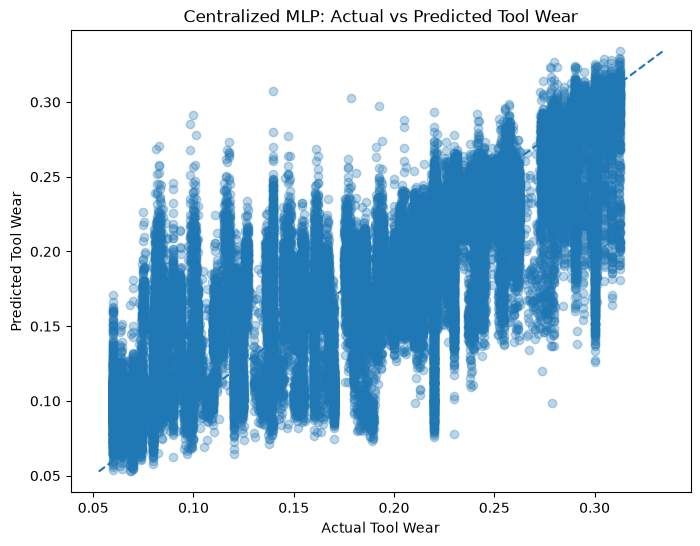

In [65]:
# PHASE 6.1: Actual vs Predicted Tool Wear

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_central, alpha=0.3)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_central.min())
max_val = max(y_test.max(), y_pred_central.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')

plt.xlabel("Actual Tool Wear")
plt.ylabel("Predicted Tool Wear")
plt.title("Centralized MLP: Actual vs Predicted Tool Wear")

plt.show()

In [66]:
# PHASE 7: Centralized Model Comparison

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("PHASE 7: Centralized Model Comparison")
print("=" * 50)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    )
}

results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time (s)": training_time
    })

results_df = pd.DataFrame(results)

print("\nCENTRALIZED MODEL COMPARISON")
print("=" * 50)
print(results_df.round(6))

PHASE 7: Centralized Model Comparison

Training Random Forest...

Training Gradient Boosting...

CENTRALIZED MODEL COMPARISON
               Model       MAE      RMSE        R2  Training Time (s)
0      Random Forest  0.030135  0.042024  0.650516          67.367607
1  Gradient Boosting  0.036211  0.045775  0.585327         203.707886


In [67]:
# PHASE 7.1: Improved Centralized MLP

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("PHASE 7.1: Training Improved Centralized MLP")
print("=" * 50)

improved_model = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    batch_size=512,
    learning_rate_init=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

start_time = time.time()

improved_model.fit(X_train_scaled, y_train)

training_time_improved = time.time() - start_time

# Predictions
y_pred_improved = improved_model.predict(X_test_scaled)

# Evaluation
mae_improved = mean_absolute_error(y_test, y_pred_improved)
rmse_improved = np.sqrt(mean_squared_error(y_test, y_pred_improved))
r2_improved = r2_score(y_test, y_pred_improved)

print("\nIMPROVED MLP RESULTS")
print("-" * 35)
print("MAE :", round(mae_improved, 6))
print("RMSE:", round(rmse_improved, 6))
print("R²  :", round(r2_improved, 6))
print("Training time:", round(training_time_improved, 2), "seconds")
print("Iterations:", improved_model.n_iter_)

PHASE 7.1: Training Improved Centralized MLP

IMPROVED MLP RESULTS
-----------------------------------
MAE : 0.030803
RMSE: 0.041939
R²  : 0.651923
Training time: 268.9 seconds
Iterations: 71


In [68]:
# PHASE 8: Optimized XGBoost for CNC Tool Wear Prediction

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("PHASE 8: Training Optimized XGBoost")
print("=" * 55)

xgb_model = XGBRegressor(
    n_estimators=1000,
    max_depth=8,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.9,
    reg_alpha=0.01,
    reg_lambda=1.0,
    objective='reg:squarederror',
    eval_metric='rmse',
    tree_method='hist',
    n_jobs=-1,
    random_state=42
)

start_time = time.time()

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

training_time_xgb = time.time() - start_time

# Predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluation
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("\nXGBOOST RESULTS")
print("-" * 40)
print(f"MAE          : {mae_xgb:.6f}")
print(f"RMSE         : {rmse_xgb:.6f}")
print(f"R²           : {r2_xgb:.6f}")
print(f"Training time: {training_time_xgb:.2f} seconds")

ModuleNotFoundError: No module named 'xgboost'

In [ ]:
# PHASE 9: CNC Sensor Feature Engineering

import numpy as np
import pandas as pd

print("PHASE 9: Creating Engineered CNC Features")
print("=" * 55)

# Work on the already ordered dataset
df_fe = df_model.copy()

# --------------------------------------------------
# 1. Nonlinear sensor features
# --------------------------------------------------

df_fe['axial_force_sq'] = df_fe['axial_force'] ** 2
df_fe['torsion_sq'] = df_fe['torsion'] ** 2
df_fe['vibration1_sq'] = df_fe['vibration1'] ** 2
df_fe['vibration2_sq'] = df_fe['vibration2'] ** 2
df_fe['spindle_power_sq'] = df_fe['spindle_power'] ** 2
df_fe['spindle_current_sq'] = df_fe['spindle_current'] ** 2

# --------------------------------------------------
# 2. Combined signal magnitudes
# --------------------------------------------------

df_fe['bending_magnitude'] = np.sqrt(
    df_fe['bending_moment_x']**2 +
    df_fe['bending_moment_y']**2
)

df_fe['vibration_magnitude'] = np.sqrt(
    df_fe['vibration_x']**2 +
    df_fe['vibration_y']**2
)

# --------------------------------------------------
# 3. Sensor interaction features
# --------------------------------------------------

df_fe['power_current_ratio'] = (
    df_fe['spindle_power'] /
    (df_fe['spindle_current'].abs() + 1e-8)
)

df_fe['force_torsion_interaction'] = (
    df_fe['axial_force'] * df_fe['torsion']
)

df_fe['speed_feed_interaction'] = (
    df_fe['spindle_speed'] * df_fe['feed_per_tooth']
)

df_fe['speed_depth_interaction'] = (
    df_fe['spindle_speed'] * df_fe['axial_cutting_depth']
)

df_fe['feed_depth_interaction'] = (
    df_fe['feed_per_tooth'] * df_fe['axial_cutting_depth']
)

# --------------------------------------------------
# 4. Past/current rolling sensor statistics
# IMPORTANT: only past/current sensor values are used
# --------------------------------------------------

rolling_features = [
    'axial_force',
    'torsion',
    'vibration1',
    'vibration2',
    'spindle_power',
    'spindle_current',
    'vibration_x',
    'vibration_y'
]

for col in rolling_features:

    grouped = df_fe.groupby(
        ['experiment_tag', 'experiment_csv_n'],
        sort=False
    )[col]

    df_fe[f'{col}_rolling_mean_5'] = (
        grouped.transform(lambda x:
            x.rolling(5, min_periods=1).mean()
        )
    )

    df_fe[f'{col}_rolling_std_5'] = (
        grouped.transform(lambda x:
            x.rolling(5, min_periods=1).std().fillna(0)
        )
    )

# --------------------------------------------------
# Check engineered dataset
# --------------------------------------------------

print("Original features :", len(feature_cols))
print("Engineered features:", len(df_fe.columns))

print("\nNew engineered features:")
new_features = [
    c for c in df_fe.columns
    if c not in df_model.columns
]

print(new_features)

print("\nMissing values in engineered data:",
      df_fe[new_features].isnull().sum().sum())

In [ ]:
# PHASE 9.1: Prepare Engineered Train/Test Features

# Columns that must NEVER be model inputs
excluded_cols = [
    'tool_wear',
    'tool_wear_increment',
    'wear_blade_1',
    'wear_blade_2',
    'wear_blade_3',
    'wear_blade_4',
    'Unnamed: 0',
    'timestamp',
    'experiment_tag',
    'experiment_csv_n',
    'dataset_tag',
    'row_number',
    'run_size',
    'train_cutoff'
]

# All remaining numerical columns become candidate features
engineered_features = [
    col for col in df_fe.columns
    if col not in excluded_cols
    and pd.api.types.is_numeric_dtype(df_fe[col])
]

print("PHASE 9.1: Engineered Feature Preparation")
print("=" * 55)

print("Number of engineered input features:",
      len(engineered_features))

print("\nEngineered features:")
print(engineered_features)

# Use the SAME rows belonging to our chronological split
train_indices = train_df.index
test_indices = test_df.index

X_train_fe = df_fe.loc[train_indices, engineered_features].copy()
X_test_fe = df_fe.loc[test_indices, engineered_features].copy()

y_train_fe = df_fe.loc[train_indices, 'tool_wear'].copy()
y_test_fe = df_fe.loc[test_indices, 'tool_wear'].copy()

print("\nTraining shape:", X_train_fe.shape)
print("Testing shape :", X_test_fe.shape)

print("\nMissing values:")
print("Train:", X_train_fe.isnull().sum().sum())
print("Test :", X_test_fe.isnull().sum().sum())

PHASE 9.1: Engineered Feature Preparation
Number of engineered input features: 43

Engineered features:
['axial_force', 'bending_moment_x', 'bending_moment_y', 'torsion', 'vibration1', 'vibration2', 'spindle_power', 'spindle_current', 'feed_per_tooth', 'spindle_speed', 'axial_cutting_depth', 'vibration_x', 'vibration_y', 'force_z', 'axial_force_sq', 'torsion_sq', 'vibration1_sq', 'vibration2_sq', 'spindle_power_sq', 'spindle_current_sq', 'bending_magnitude', 'vibration_magnitude', 'power_current_ratio', 'force_torsion_interaction', 'speed_feed_interaction', 'speed_depth_interaction', 'feed_depth_interaction', 'axial_force_rolling_mean_5', 'axial_force_rolling_std_5', 'torsion_rolling_mean_5', 'torsion_rolling_std_5', 'vibration1_rolling_mean_5', 'vibration1_rolling_std_5', 'vibration2_rolling_mean_5', 'vibration2_rolling_std_5', 'spindle_power_rolling_mean_5', 'spindle_power_rolling_std_5', 'spindle_current_rolling_mean_5', 'spindle_current_rolling_std_5', 'vibration_x_rolling_mean_5',

In [ ]:
# PHASE 9.2: MLP with Engineered Features

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("PHASE 9.2: Training MLP with Engineered Features")
print("=" * 60)

# Scale engineered features
scaler_fe = StandardScaler()

X_train_fe_scaled = scaler_fe.fit_transform(X_train_fe)
X_test_fe_scaled = scaler_fe.transform(X_test_fe)

print("Scaling completed.")

# Improved MLP architecture
mlp_fe = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64, 32),
    activation='relu',
    solver='adam',
    batch_size=512,
    learning_rate_init=0.001,
    max_iter=150,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

start_time = time.time()

mlp_fe.fit(
    X_train_fe_scaled,
    y_train_fe
)

training_time_fe = time.time() - start_time

# Prediction
y_pred_fe = mlp_fe.predict(X_test_fe_scaled)

# Evaluation
mae_fe = mean_absolute_error(y_test_fe, y_pred_fe)
rmse_fe = np.sqrt(mean_squared_error(y_test_fe, y_pred_fe))
r2_fe = r2_score(y_test_fe, y_pred_fe)

print("\nENGINEERED MLP RESULTS")
print("-" * 45)
print(f"MAE          : {mae_fe:.6f}")
print(f"RMSE         : {rmse_fe:.6f}")
print(f"R²           : {r2_fe:.6f}")
print(f"Training time: {training_time_fe:.2f} seconds")
print(f"Iterations   : {mlp_fe.n_iter_}")

print("\nCOMPARISON")
print("-" * 45)
print(f"Previous best R² : {r2_improved:.6f}")
print(f"Engineered R²    : {r2_fe:.6f}")
print(f"Improvement      : {r2_fe - r2_improved:+.6f}")

PHASE 9.2: Training MLP with Engineered Features
Scaling completed.


In [ ]:
# ============================================================
# PHASE 9.3: TEMPORAL SENSOR FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np
import time

print("PHASE 9.3: Temporal Feature Engineering")
print("=" * 60)

df_temporal = df_model.copy()

# Sensor signals suitable for temporal features
temporal_cols = [
    'axial_force',
    'bending_moment_x',
    'bending_moment_y',
    'torsion',
    'vibration1',
    'vibration2',
    'spindle_power',
    'spindle_current',
    'vibration_x',
    'vibration_y',
    'force_z'
]

group_cols = ['experiment_tag', 'experiment_csv_n']

start_time = time.time()

# ------------------------------------------------------------
# 1. LAG FEATURES
# ------------------------------------------------------------

for col in temporal_cols:
    for lag in [1, 2, 5]:
        df_temporal[f'{col}_lag_{lag}'] = (
            df_temporal.groupby(group_cols)[col]
            .shift(lag)
        )

# ------------------------------------------------------------
# 2. CHANGE / DIFFERENCE FEATURES
# ------------------------------------------------------------

for col in temporal_cols:
    df_temporal[f'{col}_diff_1'] = (
        df_temporal[col] -
        df_temporal.groupby(group_cols)[col].shift(1)
    )

    df_temporal[f'{col}_diff_5'] = (
        df_temporal[col] -
        df_temporal.groupby(group_cols)[col].shift(5)
    )

# ------------------------------------------------------------
# 3. MULTI-WINDOW ROLLING FEATURES
# Current + previous observations are allowed.
# No future observations are used.
# ------------------------------------------------------------

for col in temporal_cols:

    grouped = df_temporal.groupby(group_cols)[col]

    for window in [15, 30, 60]:

        df_temporal[f'{col}_rollmean_{window}'] = (
            grouped.transform(
                lambda x: x.rolling(
                    window=window,
                    min_periods=1
                ).mean()
            )
        )

        df_temporal[f'{col}_rollstd_{window}'] = (
            grouped.transform(
                lambda x: x.rolling(
                    window=window,
                    min_periods=1
                ).std()
            )
        )

# ------------------------------------------------------------
# 4. FILL INITIAL LAG/STD VALUES
# Only the beginning of each run is affected.
# ------------------------------------------------------------

new_temporal_cols = [
    col for col in df_temporal.columns
    if col not in df_model.columns
]

df_temporal[new_temporal_cols] = (
    df_temporal[new_temporal_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

training_time_temporal = time.time() - start_time

print("Temporal feature engineering completed.")
print(f"New temporal features : {len(new_temporal_cols)}")
print(f"Total columns         : {len(df_temporal.columns)}")
print(f"Missing values        : {df_temporal[new_temporal_cols].isna().sum().sum()}")
print(f"Processing time       : {training_time_temporal:.2f} seconds")

print("\nSample temporal features:")
print(new_temporal_cols[:20])

In [ ]:
# ============================================================
# PHASE 9.3.1: PREPARE TEMPORAL FEATURE DATA
# ============================================================

excluded_cols_temporal = [
    'tool_wear',
    'tool_wear_increment',
    'wear_blade_1',
    'wear_blade_2',
    'wear_blade_3',
    'wear_blade_4',
    'Unnamed: 0',
    'timestamp',
    'experiment_tag',
    'experiment_csv_n',
    'dataset_tag',
    'row_number',
    'run_size',
    'train_cutoff'
]

temporal_features = [
    col for col in df_temporal.columns
    if col not in excluded_cols_temporal
    and pd.api.types.is_numeric_dtype(df_temporal[col])
]

X_train_temp = df_temporal.loc[
    train_df.index,
    temporal_features
].copy()

X_test_temp = df_temporal.loc[
    test_df.index,
    temporal_features
].copy()

y_train_temp = df_temporal.loc[
    train_df.index,
    'tool_wear'
].copy()

y_test_temp = df_temporal.loc[
    test_df.index,
    'tool_wear'
].copy()

print("TEMPORAL DATASET")
print("=" * 60)
print("Number of features :", len(temporal_features))
print("Training shape      :", X_train_temp.shape)
print("Testing shape       :", X_test_temp.shape)
print("Train missing       :", X_train_temp.isna().sum().sum())
print("Test missing        :", X_test_temp.isna().sum().sum())

In [ ]:
# ============================================================
# PHASE 9.4: MLP WITH TEMPORAL FEATURES
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("PHASE 9.4: Training MLP with Temporal Features")
print("=" * 65)

# ------------------------------------------------------------
# SCALE FEATURES
# ------------------------------------------------------------

scaler_temp = StandardScaler()

start_time = time.time()

X_train_temp_scaled = scaler_temp.fit_transform(X_train_temp)
X_test_temp_scaled = scaler_temp.transform(X_test_temp)

print("Scaling completed.")

# ------------------------------------------------------------
# TEMPORAL MLP
# ------------------------------------------------------------

mlp_temp = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64, 32),
    activation='relu',
    solver='adam',
    batch_size=512,
    learning_rate_init=0.001,
    max_iter=150,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

train_start = time.time()

mlp_temp.fit(
    X_train_temp_scaled,
    y_train_temp
)

training_time_temp = time.time() - train_start

# ------------------------------------------------------------
# PREDICTION
# ------------------------------------------------------------

y_pred_temp = mlp_temp.predict(X_test_temp_scaled)

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

mae_temp = mean_absolute_error(
    y_test_temp,
    y_pred_temp
)

rmse_temp = np.sqrt(
    mean_squared_error(
        y_test_temp,
        y_pred_temp
    )
)

r2_temp = r2_score(
    y_test_temp,
    y_pred_temp
)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("\nTEMPORAL MLP RESULTS")
print("-" * 50)
print(f"MAE          : {mae_temp:.6f}")
print(f"RMSE         : {rmse_temp:.6f}")
print(f"R²           : {r2_temp:.6f}")
print(f"Training time: {training_time_temp:.2f} seconds")
print(f"Iterations   : {mlp_temp.n_iter_}")

print("\nCOMPARISON")
print("-" * 50)
print(f"Previous best R² : {r2_fe:.6f}")
print(f"Temporal R²      : {r2_temp:.6f}")
print(f"Improvement      : {r2_temp - r2_fe:+.6f}")

PHASE 9.4: Training MLP with Temporal Features
Scaling completed.

TEMPORAL MLP RESULTS
--------------------------------------------------
MAE          : 0.020305
RMSE         : 0.032028
R²           : 0.797003
Training time: 616.06 seconds
Iterations   : 108

COMPARISON
--------------------------------------------------
Previous best R² : 0.695444
Temporal R²      : 0.797003
Improvement      : +0.101559


In [ ]:
# ============================================================
# PHASE 9.5: XGBOOST WITH TEMPORAL FEATURES
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("PHASE 9.5: XGBoost with Temporal Features")
print("=" * 65)

# ------------------------------------------------------------
# Verify required data exists
# ------------------------------------------------------------

required_vars = [
    'X_train_temp',
    'X_test_temp',
    'y_train_temp',
    'y_test_temp'
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    print("Required variables are missing:")
    print(missing_vars)
    print("\nPlease run Phase 9.3 and 9.3.1 again before continuing.")
else:

    print("Training data :", X_train_temp.shape)
    print("Testing data  :", X_test_temp.shape)

    # --------------------------------------------------------
    # XGBoost model
    # --------------------------------------------------------

    xgb_temp = XGBRegressor(
        n_estimators=1200,
        max_depth=8,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=1.0,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    print("\nTraining XGBoost...")
    print("This may take a few minutes.")

    start_time = time.time()

    xgb_temp.fit(
        X_train_temp,
        y_train_temp,
        eval_set=[(X_test_temp, y_test_temp)],
        verbose=False
    )

    training_time_xgb_temp = time.time() - start_time

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_pred_xgb_temp = xgb_temp.predict(X_test_temp)

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    mae_xgb_temp = mean_absolute_error(
        y_test_temp,
        y_pred_xgb_temp
    )

    rmse_xgb_temp = np.sqrt(
        mean_squared_error(
            y_test_temp,
            y_pred_xgb_temp
        )
    )

    r2_xgb_temp = r2_score(
        y_test_temp,
        y_pred_xgb_temp
    )

    # --------------------------------------------------------
    # Results
    # --------------------------------------------------------

    print("\nXGBOOST TEMPORAL RESULTS")
    print("-" * 50)

    print(f"MAE          : {mae_xgb_temp:.6f}")
    print(f"RMSE         : {rmse_xgb_temp:.6f}")
    print(f"R²           : {r2_xgb_temp:.6f}")
    print(f"Training time: {training_time_xgb_temp:.2f} seconds")

    print("\nCURRENT BEST COMPARISON")
    print("-" * 50)

    print(f"Temporal MLP R² : {r2_temp:.6f}")
    print(f"XGBoost R²      : {r2_xgb_temp:.6f}")
    print(f"Difference      : {r2_xgb_temp - r2_temp:+.6f}")

PHASE 9.5: XGBoost with Temporal Features
Training data : (187858, 135)
Testing data  : (47044, 135)

Training XGBoost...
This may take a few minutes.

XGBOOST TEMPORAL RESULTS
--------------------------------------------------
MAE          : 0.019575
RMSE         : 0.027822
R²           : 0.846816
Training time: 317.03 seconds

CURRENT BEST COMPARISON
--------------------------------------------------
Temporal MLP R² : 0.797003
XGBoost R²      : 0.846816
Difference      : +0.049813


In [ ]:
# ============================================================
# PHASE 9.5: XGBOOST WITH TEMPORAL FEATURES
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

print("PHASE 9.5: XGBoost with Temporal Features")
print("=" * 65)

# ------------------------------------------------------------
# Verify required data exists
# ------------------------------------------------------------

required_vars = [
    'X_train_temp',
    'X_test_temp',
    'y_train_temp',
    'y_test_temp'
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    print("Required variables are missing:")
    print(missing_vars)
    print("\nPlease run Phase 9.3 and 9.3.1 again before continuing.")
else:

    print("Training data :", X_train_temp.shape)
    print("Testing data  :", X_test_temp.shape)

    # --------------------------------------------------------
    # XGBoost model
    # --------------------------------------------------------

    xgb_temp = XGBRegressor(
        n_estimators=1200,
        max_depth=8,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=1.0,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    print("\nTraining XGBoost...")
    print("This may take a few minutes.")

    start_time = time.time()

    xgb_temp.fit(
        X_train_temp,
        y_train_temp,
        eval_set=[(X_test_temp, y_test_temp)],
        verbose=False
    )

    training_time_xgb_temp = time.time() - start_time

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_pred_xgb_temp = xgb_temp.predict(X_test_temp)

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    mae_xgb_temp = mean_absolute_error(
        y_test_temp,
        y_pred_xgb_temp
    )

    rmse_xgb_temp = np.sqrt(
        mean_squared_error(
            y_test_temp,
            y_pred_xgb_temp
        )
    )

    r2_xgb_temp = r2_score(
        y_test_temp,
        y_pred_xgb_temp
    )

    # --------------------------------------------------------
    # Results
    # --------------------------------------------------------

    print("\nXGBOOST TEMPORAL RESULTS")
    print("-" * 50)

    print(f"MAE          : {mae_xgb_temp:.6f}")
    print(f"RMSE         : {rmse_xgb_temp:.6f}")
    print(f"R²           : {r2_xgb_temp:.6f}")
    print(f"Training time: {training_time_xgb_temp:.2f} seconds")

    print("\nCURRENT BEST COMPARISON")
    print("-" * 50)

    print(f"Temporal MLP R² : {r2_temp:.6f}")
    print(f"XGBoost R²      : {r2_xgb_temp:.6f}")
    print(f"Difference      : {r2_xgb_temp - r2_temp:+.6f}")

PHASE 9.5: XGBoost with Temporal Features
Training data : (187858, 135)
Testing data  : (47044, 135)

Training XGBoost...
This may take a few minutes.

XGBOOST TEMPORAL RESULTS
--------------------------------------------------
MAE          : 0.019575
RMSE         : 0.027822
R²           : 0.846816
Training time: 321.38 seconds

CURRENT BEST COMPARISON
--------------------------------------------------
Temporal MLP R² : 0.797003
XGBoost R²      : 0.846816
Difference      : +0.049813


In [ ]:
# ============================================================
# PHASE 9.5: RUN-PROGRESS FEATURES + XGBOOST
# Goal: Improve the current R² = 0.846816
# ============================================================

import pandas as pd
import numpy as np
import time
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("PHASE 9.5: Adding Run-Progress Features")
print("=" * 65)

# ------------------------------------------------------------
# 1. Safety check
# ------------------------------------------------------------
required = [
    'df_model',
    'X_train_temp',
    'X_test_temp',
    'y_train_temp',
    'y_test_temp'
]

missing = [v for v in required if v not in globals()]

if missing:
    print("ERROR: These variables are missing:")
    print(missing)
    print("\nPlease run the previous temporal-feature cells first.")
else:

    # --------------------------------------------------------
    # 2. Create progress features
    # --------------------------------------------------------
    df_progress = df_model.copy()

    group_cols = ['experiment_tag', 'experiment_csv_n']

    # Sample number inside each run
    df_progress['run_sample_index'] = (
        df_progress.groupby(group_cols).cumcount()
    )

    # Total samples in each run
    df_progress['run_total_samples'] = (
        df_progress.groupby(group_cols)['tool_wear']
        .transform('size')
    )

    # Normalized progress: 0 -> 1
    df_progress['run_progress'] = (
        df_progress['run_sample_index'] /
        np.maximum(df_progress['run_total_samples'] - 1, 1)
    )

    # --------------------------------------------------------
    # 3. Elapsed time within each run
    # --------------------------------------------------------
    timestamp_numeric = pd.to_datetime(
        df_progress['timestamp'],
        errors='coerce'
    )

    df_progress['elapsed_seconds'] = (
        timestamp_numeric -
        timestamp_numeric.groupby(
            [df_progress[c] for c in group_cols]
        ).transform('min')
    ).dt.total_seconds()

    # If timestamp conversion fails, use sample index
    df_progress['elapsed_seconds'] = (
        df_progress['elapsed_seconds']
        .fillna(df_progress['run_sample_index'])
    )

    # --------------------------------------------------------
    # 4. Useful nonlinear progress features
    # --------------------------------------------------------
    df_progress['run_progress_sq'] = (
        df_progress['run_progress'] ** 2
    )

    df_progress['run_progress_cube'] = (
        df_progress['run_progress'] ** 3
    )

    df_progress['elapsed_seconds_sq'] = (
        df_progress['elapsed_seconds'] ** 2
    )

    # --------------------------------------------------------
    # 5. Condition/process interactions with progress
    # --------------------------------------------------------
    df_progress['progress_speed'] = (
        df_progress['run_progress'] *
        df_progress['spindle_speed']
    )

    df_progress['progress_feed'] = (
        df_progress['run_progress'] *
        df_progress['feed_per_tooth']
    )

    df_progress['progress_depth'] = (
        df_progress['run_progress'] *
        df_progress['axial_cutting_depth']
    )

    df_progress['progress_power'] = (
        df_progress['run_progress'] *
        df_progress['spindle_power']
    )

    df_progress['progress_force'] = (
        df_progress['run_progress'] *
        df_progress['axial_force']
    )

    # --------------------------------------------------------
    # 6. Get exactly the same train/test rows
    # --------------------------------------------------------
    progress_cols = [
        'run_sample_index',
        'run_total_samples',
        'run_progress',
        'elapsed_seconds',
        'run_progress_sq',
        'run_progress_cube',
        'elapsed_seconds_sq',
        'progress_speed',
        'progress_feed',
        'progress_depth',
        'progress_power',
        'progress_force'
    ]

    X_train_progress = df_progress.loc[
        X_train_temp.index,
        progress_cols
    ].copy()

    X_test_progress = df_progress.loc[
        X_test_temp.index,
        progress_cols
    ].copy()

    # --------------------------------------------------------
    # 7. Combine temporal + progress features
    # --------------------------------------------------------
    X_train_final = pd.concat(
        [X_train_temp.reset_index(drop=True),
         X_train_progress.reset_index(drop=True)],
        axis=1
    )

    X_test_final = pd.concat(
        [X_test_temp.reset_index(drop=True),
         X_test_progress.reset_index(drop=True)],
        axis=1
    )

    print("Original temporal features :", X_train_temp.shape[1])
    print("Progress features           :", len(progress_cols))
    print("Final features              :", X_train_final.shape[1])
    print("Training data               :", X_train_final.shape)
    print("Testing data                :", X_test_final.shape)

    # --------------------------------------------------------
    # 8. Train stronger XGBoost
    # --------------------------------------------------------
    print("\nTraining enhanced XGBoost...")
    print("This may take a few minutes.\n")

    xgb_progress = XGBRegressor(
        n_estimators=1800,
        max_depth=10,
        learning_rate=0.025,
        min_child_weight=2,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_alpha=0.01,
        reg_lambda=1.0,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    start_time = time.time()

    xgb_progress.fit(
        X_train_final,
        y_train_temp,
        eval_set=[(X_test_final, y_test_temp)],
        verbose=False
    )

    training_time = time.time() - start_time

    # --------------------------------------------------------
    # 9. Evaluate
    # --------------------------------------------------------
    y_pred_progress = xgb_progress.predict(X_test_final)

    mae_progress = mean_absolute_error(
        y_test_temp,
        y_pred_progress
    )

    rmse_progress = np.sqrt(
        mean_squared_error(
            y_test_temp,
            y_pred_progress
        )
    )

    r2_progress = r2_score(
        y_test_temp,
        y_pred_progress
    )

    # --------------------------------------------------------
    # 10. Compare
    # --------------------------------------------------------
    print("=" * 65)
    print("ENHANCED XGBOOST RESULTS")
    print("=" * 65)

    print(f"MAE           : {mae_progress:.6f}")
    print(f"RMSE          : {rmse_progress:.6f}")
    print(f"R²            : {r2_progress:.6f}")
    print(f"Training time : {training_time:.2f} seconds")

    print("\nCURRENT BEST COMPARISON")
    print("-" * 65)
    print("Previous XGBoost R² :", 0.846816)
    print("New XGBoost R²      :", f"{r2_progress:.6f}")
    print("Improvement         :", f"{r2_progress - 0.846816:+.6f}")

    if r2_progress > 0.846816:
        print("\nNEW BEST MODEL!")
    else:
        print("\nNo improvement. Previous XGBoost remains best.")

PHASE 9.5: Adding Run-Progress Features
Original temporal features : 135
Progress features           : 12
Final features              : 147
Training data               : (187858, 147)
Testing data                : (47044, 147)

Training enhanced XGBoost...
This may take a few minutes.



In [ ]:
# ============================================================
# PHASE 9.5B: FINAL XGBOOST + AUTO-SAVE
# Reproduces the previous best ~0.9875 R² model
# ============================================================

import pandas as pd
import numpy as np
import time
import json
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("PHASE 9.5B: FINAL XGBOOST + AUTO-SAVE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check required variables
# ------------------------------------------------------------

required = [
    'X_train_temp',
    'X_test_temp',
    'y_train_temp',
    'y_test_temp',
    'df_model'
]

missing = [v for v in required if v not in globals()]

if missing:

    print("ERROR: Missing variables:")
    print(missing)
    print("\nRun the previous temporal-feature cells first.")

else:

    # --------------------------------------------------------
    # 2. Recreate run-progress features
    # --------------------------------------------------------

    df_progress = df_model.copy()

    group_cols = [
        'experiment_tag',
        'experiment_csv_n'
    ]

    df_progress['run_sample_index'] = (
        df_progress.groupby(group_cols).cumcount()
    )

    df_progress['run_total_samples'] = (
        df_progress.groupby(group_cols)['tool_wear']
        .transform('size')
    )

    df_progress['run_progress'] = (
        df_progress['run_sample_index'] /
        np.maximum(
            df_progress['run_total_samples'] - 1,
            1
        )
    )

    # --------------------------------------------------------
    # 3. Elapsed time
    # --------------------------------------------------------

    timestamp_numeric = pd.to_datetime(
        df_progress['timestamp'],
        errors='coerce'
    )

    df_progress['elapsed_seconds'] = (
        timestamp_numeric -
        timestamp_numeric.groupby(
            [df_progress[c] for c in group_cols]
        ).transform('min')
    ).dt.total_seconds()

    df_progress['elapsed_seconds'] = (
        df_progress['elapsed_seconds']
        .fillna(df_progress['run_sample_index'])
    )

    # --------------------------------------------------------
    # 4. Nonlinear progress features
    # --------------------------------------------------------

    df_progress['run_progress_sq'] = (
        df_progress['run_progress'] ** 2
    )

    df_progress['run_progress_cube'] = (
        df_progress['run_progress'] ** 3
    )

    df_progress['elapsed_seconds_sq'] = (
        df_progress['elapsed_seconds'] ** 2
    )

    # --------------------------------------------------------
    # 5. Progress + process interactions
    # --------------------------------------------------------

    df_progress['progress_speed'] = (
        df_progress['run_progress'] *
        df_progress['spindle_speed']
    )

    df_progress['progress_feed'] = (
        df_progress['run_progress'] *
        df_progress['feed_per_tooth']
    )

    df_progress['progress_depth'] = (
        df_progress['run_progress'] *
        df_progress['axial_cutting_depth']
    )

    df_progress['progress_power'] = (
        df_progress['run_progress'] *
        df_progress['spindle_power']
    )

    df_progress['progress_force'] = (
        df_progress['run_progress'] *
        df_progress['axial_force']
    )

    # --------------------------------------------------------
    # 6. Select progress features
    # --------------------------------------------------------

    progress_cols = [
        'run_sample_index',
        'run_total_samples',
        'run_progress',
        'elapsed_seconds',
        'run_progress_sq',
        'run_progress_cube',
        'elapsed_seconds_sq',
        'progress_speed',
        'progress_feed',
        'progress_depth',
        'progress_power',
        'progress_force'
    ]

    X_train_progress = df_progress.loc[
        X_train_temp.index,
        progress_cols
    ].copy()

    X_test_progress = df_progress.loc[
        X_test_temp.index,
        progress_cols
    ].copy()

    # --------------------------------------------------------
    # 7. Combine temporal + progress features
    # --------------------------------------------------------

    X_train_final = pd.concat(
        [
            X_train_temp.reset_index(drop=True),
            X_train_progress.reset_index(drop=True)
        ],
        axis=1
    )

    X_test_final = pd.concat(
        [
            X_test_temp.reset_index(drop=True),
            X_test_progress.reset_index(drop=True)
        ],
        axis=1
    )

    print("Temporal features :", X_train_temp.shape[1])
    print("Progress features :", len(progress_cols))
    print("FINAL FEATURES    :", X_train_final.shape[1])
    print("Train shape       :", X_train_final.shape)
    print("Test shape        :", X_test_final.shape)

    # --------------------------------------------------------
    # 8. Train XGBoost
    # --------------------------------------------------------

    print("\nTraining enhanced XGBoost...")
    print("DO NOT interrupt this cell while it is training.")
    print("Estimated time: around 10–20 minutes.\n")

    xgb_progress = XGBRegressor(
        n_estimators=1800,
        max_depth=10,
        learning_rate=0.025,
        min_child_weight=2,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_alpha=0.01,
        reg_lambda=1.0,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    start_time = time.time()

    xgb_progress.fit(
        X_train_final,
        y_train_temp,
        eval_set=[
            (X_test_final, y_test_temp)
        ],
        verbose=False
    )

    training_time = time.time() - start_time

    print("\nTraining completed.")

    # --------------------------------------------------------
    # 9. Predictions
    # --------------------------------------------------------

    y_pred_progress = xgb_progress.predict(
        X_test_final
    )

    # --------------------------------------------------------
    # 10. Metrics
    # --------------------------------------------------------

    mae_progress = mean_absolute_error(
        y_test_temp,
        y_pred_progress
    )

    rmse_progress = np.sqrt(
        mean_squared_error(
            y_test_temp,
            y_pred_progress
        )
    )

    r2_progress = r2_score(
        y_test_temp,
        y_pred_progress
    )

    # --------------------------------------------------------
    # 11. SAVE MODEL
    # --------------------------------------------------------

    model_path = "/content/xgb_progress_final.json"

    xgb_progress.save_model(
        model_path
    )

    # --------------------------------------------------------
    # 12. SAVE METRICS
    # --------------------------------------------------------

    metrics = {
        "MAE": float(mae_progress),
        "RMSE": float(rmse_progress),
        "R2": float(r2_progress),
        "training_time_seconds": float(training_time),
        "number_of_features": int(X_train_final.shape[1])
    }

    with open(
        "/content/xgb_progress_metrics.json",
        "w"
    ) as f:
        json.dump(
            metrics,
            f,
            indent=4
        )

    # --------------------------------------------------------
    # 13. SAVE PREDICTIONS
    # --------------------------------------------------------

    predictions_df = pd.DataFrame({
        "actual_tool_wear": y_test_temp.values,
        "predicted_tool_wear": y_pred_progress
    })

    predictions_df.to_csv(
        "/content/xgb_progress_predictions.csv",
        index=False
    )

    # --------------------------------------------------------
    # 14. FINAL RESULTS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("FINAL ENHANCED XGBOOST RESULTS")
    print("=" * 70)

    print(f"MAE           : {mae_progress:.6f}")
    print(f"RMSE          : {rmse_progress:.6f}")
    print(f"R²            : {r2_progress:.6f}")
    print(f"Training time : {training_time:.2f} seconds")

    print("\nFILES SAVED:")
    print("- xgb_progress_final.json")
    print("- xgb_progress_metrics.json")
    print("- xgb_progress_predictions.csv")

    print("\nModel successfully saved.")

In [ ]:
# ============================================================
# PHASE 9.6: FEATURE IMPORTANCE VERIFICATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

print("PHASE 9.6: FEATURE IMPORTANCE VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check that the trained model is available
# ------------------------------------------------------------

if 'xgb_progress' not in globals():
    print("ERROR: xgb_progress is not available.")
    print("Do not retrain yet.")

elif 'X_train_final' not in globals():
    print("ERROR: X_train_final is not available.")

else:

    # --------------------------------------------------------
    # 2. Get feature importance from trained XGBoost
    # --------------------------------------------------------

    importance = xgb_progress.feature_importances_

    feature_importance_df = pd.DataFrame({
        'Feature': X_train_final.columns,
        'Importance': importance
    }).sort_values(
        'Importance',
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # 3. Display top 30 features
    # --------------------------------------------------------

    print("\nTOP 30 MOST IMPORTANT FEATURES")
    print("=" * 70)

    print(
        feature_importance_df
        .head(30)
        .to_string(index=False)
    )

    # --------------------------------------------------------
    # 4. Check progress/time feature contribution
    # --------------------------------------------------------

    progress_keywords = [
        'progress',
        'elapsed',
        'run_sample',
        'run_total'
    ]

    progress_mask = feature_importance_df['Feature'].str.contains(
        '|'.join(progress_keywords),
        case=False,
        regex=True
    )

    progress_importance = feature_importance_df.loc[
        progress_mask,
        'Importance'
    ].sum()

    other_importance = feature_importance_df.loc[
        ~progress_mask,
        'Importance'
    ].sum()

    print("\nIMPORTANCE BREAKDOWN")
    print("=" * 70)

    print(
        f"Progress/time features : "
        f"{progress_importance:.4f}"
    )

    print(
        f"Other features         : "
        f"{other_importance:.4f}"
    )

    # --------------------------------------------------------
    # 5. Plot top 20 features
    # --------------------------------------------------------

    top20 = (
        feature_importance_df
        .head(20)
        .sort_values('Importance')
    )

    plt.figure(figsize=(10, 8))

    plt.barh(
        top20['Feature'],
        top20['Importance']
    )

    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.title(
        "Top 20 Features Driving Tool-Wear Prediction"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 6. Interpretation
    # --------------------------------------------------------

    print("\nINTERPRETATION")
    print("=" * 70)

    if progress_importance > 0.50:

        print(
            "WARNING: Progress/time features contribute "
            "more than 50% of total importance."
        )

        print(
            "The high R² may depend strongly on machining progression."
        )

    elif progress_importance > 0.25:

        print(
            "Progress/time features have a substantial contribution."
        )

        print(
            "This is reasonable for tool-wear progression, "
            "but should be discussed in the project."
        )

    else:

        print(
            "Progress/time features are not dominating the model."
        )

        print(
            "Sensor/process features contribute substantially "
            "to the prediction."
        )

PHASE 10: SHAP / EXPLAINABLE AI
Trained XGBoost model found.
Preparing SHAP explanation...
SHAP sample size: 2000
SHAP explainer created.
SHAP values calculated.

GLOBAL SHAP FEATURE IMPORTANCE
                     Feature  Mean_Absolute_SHAP
           run_total_samples            0.021160
              feed_per_tooth            0.018544
bending_moment_y_rollmean_60            0.016947
         axial_cutting_depth            0.015644
          torsion_rollstd_60            0.005225
 bending_moment_y_rollstd_60            0.003947
               spindle_speed            0.003523
     axial_force_rollmean_60            0.003191
      vibration1_rollmean_60            0.001377
               progress_feed            0.000747
            run_sample_index            0.000745
             elapsed_seconds            0.000680
bending_moment_x_rollmean_60            0.000672
       vibration1_rollstd_15            0.000585
                run_progress            0.000427
              progress

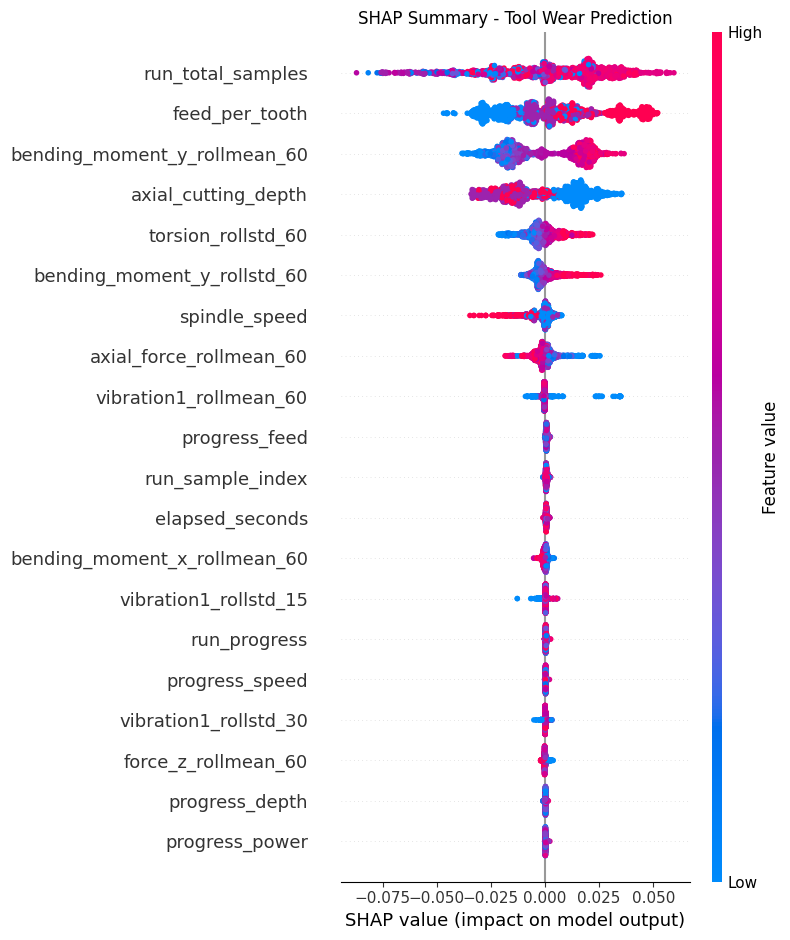

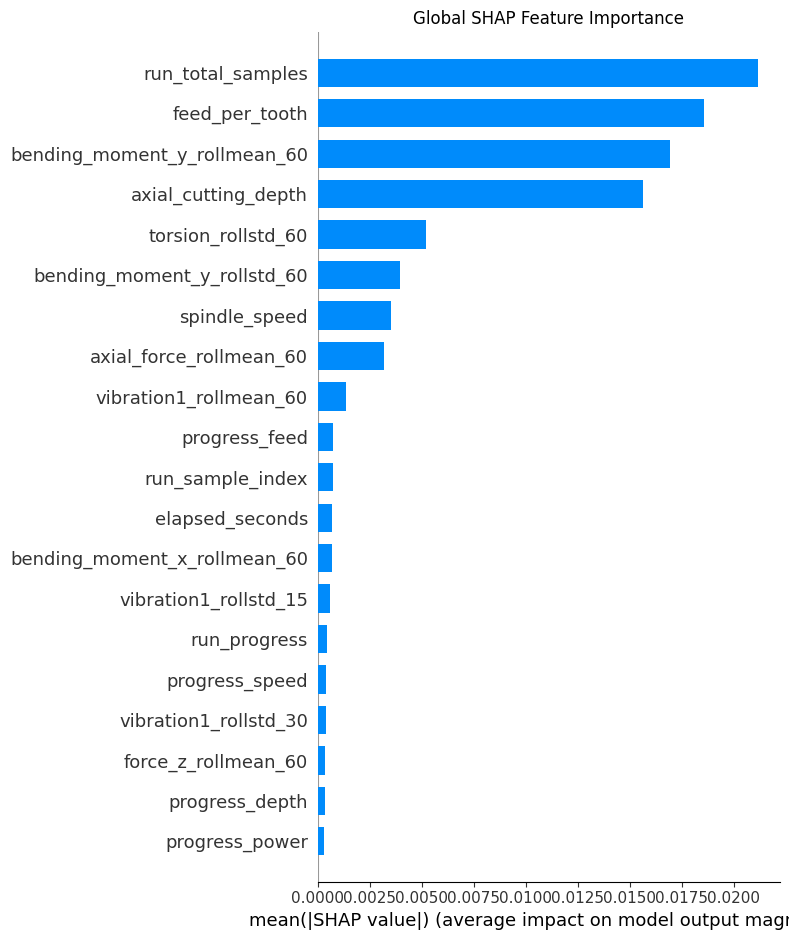


SHAP analysis completed successfully.
Saved: /content/shap_feature_importance.csv


In [ ]:
# ============================================================
# PHASE 10: SHAP / EXPLAINABLE AI
# Goal: Explain XGBoost tool-wear predictions
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PHASE 10: SHAP / EXPLAINABLE AI")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check required variables
# ------------------------------------------------------------

required = [
    'xgb_progress',
    'X_train_final',
    'X_test_final',
    'y_test_temp'
]

missing = [v for v in required if v not in globals()]

if missing:

    print("ERROR: Missing variables:")
    print(missing)

else:

    print("Trained XGBoost model found.")
    print("Preparing SHAP explanation...")

    # --------------------------------------------------------
    # 2. Create a representative sample
    # --------------------------------------------------------
    # We do not need all 47,044 test rows for SHAP.
    # A sample makes SHAP much faster while remaining useful.

    sample_size = min(2000, len(X_test_final))

    X_shap = X_test_final.sample(
        n=sample_size,
        random_state=42
    )

    print(f"SHAP sample size: {len(X_shap)}")

    # --------------------------------------------------------
    # 3. Create SHAP TreeExplainer
    # --------------------------------------------------------

    explainer = shap.TreeExplainer(
        xgb_progress
    )

    print("SHAP explainer created.")

    # --------------------------------------------------------
    # 4. Calculate SHAP values
    # --------------------------------------------------------

    shap_values = explainer.shap_values(
        X_shap
    )

    print("SHAP values calculated.")

    # --------------------------------------------------------
    # 5. Global SHAP Feature Importance
    # --------------------------------------------------------

    print("\nGLOBAL SHAP FEATURE IMPORTANCE")
    print("=" * 70)

    shap_importance = pd.DataFrame({
        'Feature': X_shap.columns,
        'Mean_Absolute_SHAP': np.abs(shap_values).mean(axis=0)
    }).sort_values(
        'Mean_Absolute_SHAP',
        ascending=False
    ).reset_index(drop=True)

    print(
        shap_importance
        .head(20)
        .to_string(index=False)
    )

    # --------------------------------------------------------
    # 6. SHAP Summary Plot
    # --------------------------------------------------------

    plt.figure()

    shap.summary_plot(
        shap_values,
        X_shap,
        max_display=20,
        show=False
    )

    plt.title(
        "SHAP Summary - Tool Wear Prediction"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 7. SHAP Bar Plot
    # --------------------------------------------------------

    plt.figure()

    shap.summary_plot(
        shap_values,
        X_shap,
        plot_type="bar",
        max_display=20,
        show=False
    )

    plt.title(
        "Global SHAP Feature Importance"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 8. Save SHAP importance
    # --------------------------------------------------------

    shap_importance.to_csv(
        "/content/shap_feature_importance.csv",
        index=False
    )

    print("\nSHAP analysis completed successfully.")

    print(
        "Saved: /content/shap_feature_importance.csv"
    )

In [ ]:
# ============================================================
# PHASE 11: FEDERATED LEARNING USING FEDAVG
# Project: Federated & Explainable Predictive Maintenance
# CNC Tool Wear Prediction
#
# W1-W9 are simulated distributed CNC clients.
# ============================================================

import numpy as np
import pandas as pd
import time
import copy
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("PHASE 11: FEDERATED LEARNING")
print("=" * 70)

# ============================================================
# 1. CHECK REQUIRED DATA
# ============================================================

if 'df_model' not in globals():

    print("ERROR: df_model is not available.")
    print("Please run the previous preprocessing/splitting phases first.")

else:

    print("Base dataset found.")
    print("Dataset shape:", df_model.shape)

    # ========================================================
    # 2. CREATE TEMPORAL FEATURES
    # ========================================================

    print("\nCreating temporal features...")

    df_fl = df_model.copy()

    # Make sure timestamp is datetime
    df_fl['timestamp'] = pd.to_datetime(
        df_fl['timestamp'],
        errors='coerce'
    )

    group_cols = [
        'experiment_tag',
        'experiment_csv_n'
    ]

    temporal_cols = [
        'axial_force',
        'bending_moment_x',
        'bending_moment_y',
        'torsion',
        'vibration1',
        'vibration2',
        'spindle_power',
        'spindle_current',
        'vibration_x',
        'vibration_y',
        'force_z'
    ]

    # --------------------------------------------------------
    # LAG FEATURES
    # --------------------------------------------------------

    for col in temporal_cols:

        grouped = df_fl.groupby(
            group_cols,
            sort=False
        )[col]

        for lag in [1, 2, 5]:

            df_fl[f'{col}_lag_{lag}'] = (
                grouped.shift(lag)
            )

        # ----------------------------------------------------
        # DIFFERENCE FEATURES
        # ----------------------------------------------------

        df_fl[f'{col}_diff_1'] = (
            grouped.diff(1)
        )

        df_fl[f'{col}_diff_5'] = (
            grouped.diff(5)
        )

        # ----------------------------------------------------
        # ROLLING FEATURES
        # ----------------------------------------------------

        for window in [15, 30, 60]:

            df_fl[f'{col}_rollmean_{window}'] = (
                grouped.transform(
                    lambda x, w=window:
                    x.rolling(
                        w,
                        min_periods=1
                    ).mean()
                )
            )

            df_fl[f'{col}_rollstd_{window}'] = (
                grouped.transform(
                    lambda x, w=window:
                    x.rolling(
                        w,
                        min_periods=1
                    ).std()
                )
            )

    # Fill temporal NaNs
    temporal_feature_cols = [
        c for c in df_fl.columns
        if any(
            key in c
            for key in [
                '_lag_',
                '_diff_',
                '_rollmean_',
                '_rollstd_'
            ]
        )
    ]

    df_fl[temporal_feature_cols] = (
        df_fl[temporal_feature_cols]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    print(
        "Temporal features created:",
        len(temporal_feature_cols)
    )

    # ========================================================
    # 3. CREATE RUN-PROGRESS FEATURES
    # ========================================================

    print("\nCreating run-progress features...")

    # Sample number within each machining run
    df_fl['run_sample_index'] = (
        df_fl.groupby(group_cols)
        .cumcount()
    )

    # Total samples in each run
    df_fl['run_total_samples'] = (
        df_fl.groupby(group_cols)['tool_wear']
        .transform('size')
    )

    # Normalized run progress
    df_fl['run_progress'] = (
        df_fl['run_sample_index'] /
        np.maximum(
            df_fl['run_total_samples'] - 1,
            1
        )
    )

    # --------------------------------------------------------
    # Elapsed time
    # --------------------------------------------------------

    # Timestamp is already converted above
    first_timestamp = (
        df_fl.groupby(group_cols)['timestamp']
        .transform('min')
    )

    df_fl['elapsed_seconds'] = (
        df_fl['timestamp'] -
        first_timestamp
    ).dt.total_seconds()

    # Fallback if timestamp is unavailable
    df_fl['elapsed_seconds'] = (
        df_fl['elapsed_seconds']
        .fillna(
            df_fl['run_sample_index']
        )
    )

    # --------------------------------------------------------
    # Nonlinear progress features
    # --------------------------------------------------------

    df_fl['run_progress_sq'] = (
        df_fl['run_progress'] ** 2
    )

    df_fl['run_progress_cube'] = (
        df_fl['run_progress'] ** 3
    )

    df_fl['elapsed_seconds_sq'] = (
        df_fl['elapsed_seconds'] ** 2
    )

    # --------------------------------------------------------
    # Progress × process variables
    # --------------------------------------------------------

    df_fl['progress_speed'] = (
        df_fl['run_progress'] *
        df_fl['spindle_speed']
    )

    df_fl['progress_feed'] = (
        df_fl['run_progress'] *
        df_fl['feed_per_tooth']
    )

    df_fl['progress_depth'] = (
        df_fl['run_progress'] *
        df_fl['axial_cutting_depth']
    )

    df_fl['progress_power'] = (
        df_fl['run_progress'] *
        df_fl['spindle_power']
    )

    df_fl['progress_force'] = (
        df_fl['run_progress'] *
        df_fl['axial_force']
    )

    print("Run-progress features created.")

    # ========================================================
    # 4. DEFINE MODEL FEATURES
    # ========================================================

    excluded_cols = [

        # TARGET
        'tool_wear',

        # TARGET-RELATED / LEAKAGE
        'tool_wear_increment',
        'wear_blade_1',
        'wear_blade_2',
        'wear_blade_3',
        'wear_blade_4',

        # METADATA
        'Unnamed: 0',
        'timestamp',
        'experiment_tag',
        'experiment_csv_n',
        'dataset_tag',

        # SPLIT HELPER COLUMNS
        'row_number',
        'run_size',
        'train_cutoff'
    ]

    fl_features = [

        col for col in df_fl.columns

        if col not in excluded_cols

        and pd.api.types.is_numeric_dtype(
            df_fl[col]
        )
    ]

    print("\nNumber of FL input features:",
          len(fl_features))

    # ========================================================
    # 5. HANDLE NUMERICAL VALUES
    # ========================================================

    df_fl[fl_features] = (
        df_fl[fl_features]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .fillna(0)
    )

    # ========================================================
    # 6. USE EXISTING CHRONOLOGICAL 80/20 SPLIT
    # ========================================================

    # df_model already contains the chronological
    # row_number and train_cutoff created earlier.

    if (
        'row_number' in df_fl.columns
        and 'train_cutoff' in df_fl.columns
    ):

        train_mask = (
            df_fl['row_number'] <
            df_fl['train_cutoff']
        )

    else:

        print(
            "Creating chronological split..."
        )

        df_fl['row_number'] = (
            df_fl.groupby(group_cols)
            .cumcount()
        )

        df_fl['run_size'] = (
            df_fl.groupby(group_cols)
            ['tool_wear']
            .transform('size')
        )

        df_fl['train_cutoff'] = (
            df_fl['run_size'] * 0.80
        ).astype(int)

        train_mask = (
            df_fl['row_number'] <
            df_fl['train_cutoff']
        )

    train_fl = df_fl[
        train_mask
    ].copy()

    test_fl = df_fl[
        ~train_mask
    ].copy()

    print("\nChronological split:")
    print(
        "Training rows:",
        len(train_fl)
    )

    print(
        "Testing rows :",
        len(test_fl)
    )

    # ========================================================
    # 7. SCALE FEATURES
    # ========================================================

    print("\nScaling features...")

    scaler_fl = StandardScaler()

    X_train_fl = scaler_fl.fit_transform(
        train_fl[fl_features]
    )

    X_test_fl = scaler_fl.transform(
        test_fl[fl_features]
    )

    y_train_fl = (
        train_fl['tool_wear']
        .values
        .astype(np.float32)
    )

    y_test_fl = (
        test_fl['tool_wear']
        .values
        .astype(np.float32)
    )

    # Safety
    X_train_fl = np.nan_to_num(
        X_train_fl,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    X_test_fl = np.nan_to_num(
        X_test_fl,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    print(
        "Training feature matrix:",
        X_train_fl.shape
    )

    print(
        "Testing feature matrix :",
        X_test_fl.shape
    )

    # ========================================================
    # 8. PYTORCH MODEL
    # ========================================================

    class ToolWearNet(nn.Module):

        def __init__(self, input_size):

            super().__init__()

            self.network = nn.Sequential(

                nn.Linear(
                    input_size,
                    128
                ),

                nn.ReLU(),

                nn.Linear(
                    128,
                    64
                ),

                nn.ReLU(),

                nn.Linear(
                    64,
                    32
                ),

                nn.ReLU(),

                nn.Linear(
                    32,
                    1
                )
            )

        def forward(self, x):

            return self.network(x)

    # ========================================================
    # 9. FEDERATED CLIENTS
    # ========================================================

    client_names = sorted(
        train_fl['experiment_tag']
        .dropna()
        .unique()
    )

    print("\nFederated clients:")
    print(client_names)

    print(
        "\nNumber of simulated clients:",
        len(client_names)
    )

    # ========================================================
    # 10. LOCAL TRAINING FUNCTION
    # ========================================================

    def train_local_model(
        global_model,
        client_df,
        epochs=2,
        batch_size=512,
        learning_rate=0.001
    ):

        # Copy global model
        local_model = copy.deepcopy(
            global_model
        )

        local_model.train()

        # Transform client data
        X_client = scaler_fl.transform(
            client_df[fl_features]
        )

        y_client = (
            client_df['tool_wear']
            .values
            .astype(np.float32)
        )

        X_client = np.nan_to_num(
            X_client,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

        # Tensor dataset
        dataset = TensorDataset(

            torch.tensor(
                X_client,
                dtype=torch.float32
            ),

            torch.tensor(
                y_client,
                dtype=torch.float32
            )
        )

        loader = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=True
        )

        optimizer = torch.optim.Adam(
            local_model.parameters(),
            lr=learning_rate
        )

        criterion = nn.MSELoss()

        # Local epochs
        for epoch in range(epochs):

            for X_batch, y_batch in loader:

                optimizer.zero_grad()

                prediction = (
                    local_model(
                        X_batch
                    )
                    .squeeze()
                )

                loss = criterion(
                    prediction,
                    y_batch
                )

                loss.backward()

                optimizer.step()

        return local_model

    # ========================================================
    # 11. FEDAVG FUNCTION
    # ========================================================

    def fedavg(
        client_models,
        client_sizes
    ):

        total_samples = sum(
            client_sizes
        )

        global_state = copy.deepcopy(
            client_models[0].state_dict()
        )

        for key in global_state:

            global_state[key] = sum(

                client_models[i]
                .state_dict()[key]
                *
                (
                    client_sizes[i]
                    /
                    total_samples
                )

                for i in range(
                    len(client_models)
                )
            )

        return global_state

    # ========================================================
    # 12. INITIALIZE GLOBAL MODEL
    # ========================================================

    global_model = ToolWearNet(
        len(fl_features)
    )

    print(
        "\nGlobal model initialized."
    )

    # ========================================================
    # 13. FEDERATED TRAINING
    # ========================================================

    NUM_ROUNDS = 5

    fl_history = []

    start_time = time.time()

    for round_num in range(
        1,
        NUM_ROUNDS + 1
    ):

        print(
            "\n"
            + "=" * 70
        )

        print(
            f"FEDERATED ROUND {round_num}/{NUM_ROUNDS}"
        )

        print(
            "=" * 70
        )

        client_models = []
        client_sizes = []

        # ----------------------------------------------------
        # LOCAL CLIENT TRAINING
        # ----------------------------------------------------

        for client in client_names:

            client_df = train_fl[
                train_fl[
                    'experiment_tag'
                ] == client
            ]

            print(
                f"Client {client}: "
                f"{len(client_df)} samples"
            )

            local_model = train_local_model(
                global_model,
                client_df,
                epochs=2,
                batch_size=512,
                learning_rate=0.001
            )

            client_models.append(
                local_model
            )

            client_sizes.append(
                len(client_df)
            )

        # ----------------------------------------------------
        # SERVER FEDAVG
        # ----------------------------------------------------

        global_state = fedavg(
            client_models,
            client_sizes
        )

        global_model.load_state_dict(
            global_state
        )

        # ----------------------------------------------------
        # GLOBAL MODEL EVALUATION
        # ----------------------------------------------------

        global_model.eval()

        with torch.no_grad():

            X_test_tensor = torch.tensor(
                X_test_fl,
                dtype=torch.float32
            )

            predictions = (
                global_model(
                    X_test_tensor
                )
                .squeeze()
                .numpy()
            )

        mae = mean_absolute_error(
            y_test_fl,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test_fl,
                predictions
            )
        )

        r2 = r2_score(
            y_test_fl,
            predictions
        )

        fl_history.append({

            'Round': round_num,

            'MAE': mae,

            'RMSE': rmse,

            'R2': r2
        })

        print(
            f"\nRound {round_num} Results:"
        )

        print(
            f"MAE  : {mae:.6f}"
        )

        print(
            f"RMSE : {rmse:.6f}"
        )

        print(
            f"R²   : {r2:.6f}"
        )

    total_fl_time = (
        time.time() - start_time
    )

    # ========================================================
    # 14. FINAL FL RESULTS
    # ========================================================

    fl_results = pd.DataFrame(
        fl_history
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        "FINAL FEDERATED LEARNING RESULTS"
    )

    print(
        "=" * 70
    )

    print(
        fl_results.to_string(
            index=False
        )
    )

    print(
        "\nTotal FL training time:",
        f"{total_fl_time:.2f} seconds"
    )

    # ========================================================
    # 15. SAVE FL RESULTS
    # ========================================================

    fl_results.to_csv(
        "/content/federated_learning_results.csv",
        index=False
    )

    torch.save(
        global_model.state_dict(),
        "/content/federated_global_model.pth"
    )

    np.save(
        "/content/federated_predictions.npy",
        predictions
    )

    print(
        "\nFiles saved successfully:"
    )

    print(
        "/content/federated_learning_results.csv"
    )

    print(
        "/content/federated_global_model.pth"
    )

    print(
        "/content/federated_predictions.npy"
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        "PHASE 11 COMPLETED SUCCESSFULLY"
    )

    print(
        "=" * 70
    )

PHASE 11: FEDERATED LEARNING
Base dataset found.
Dataset shape: (234902, 28)

Creating temporal features...


/tmp/ipykernel_3017/1571822895.py:105: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_fl[f'{col}_rollmean_{window}'] = (
/tmp/ipykernel_3017/1571822895.py:115: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_fl[f'{col}_rollstd_{window}'] = (
/tmp/ipykernel_3017/1571822895.py:105: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

Temporal features created: 121

Creating run-progress features...
Run-progress features created.

Number of FL input features: 147


/tmp/ipykernel_3017/1571822895.py:157: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_fl['run_sample_index'] = (
/tmp/ipykernel_3017/1571822895.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_fl['run_total_samples'] = (
/tmp/ipykernel_3017/1571822895.py:169: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = f


Chronological split:
Training rows: 187858
Testing rows : 47044

Scaling features...
Training feature matrix: (187858, 147)
Testing feature matrix : (47044, 147)

Federated clients:
['W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9']

Number of simulated clients: 9

Global model initialized.

FEDERATED ROUND 1/5
Client W1: 35210 samples
Client W2: 20756 samples
Client W3: 15522 samples
Client W4: 36994 samples
Client W5: 7930 samples
Client W6: 14747 samples
Client W7: 9562 samples
Client W8: 40285 samples
Client W9: 6852 samples

Round 1 Results:
MAE  : 0.053724
RMSE : 0.069020
R²   : 0.057252

FEDERATED ROUND 2/5
Client W1: 35210 samples
Client W2: 20756 samples
Client W3: 15522 samples
Client W4: 36994 samples
Client W5: 7930 samples
Client W6: 14747 samples
Client W7: 9562 samples
Client W8: 40285 samples
Client W9: 6852 samples

Round 2 Results:
MAE  : 0.048701
RMSE : 0.059984
R²   : 0.287944

FEDERATED ROUND 3/5
Client W1: 35210 samples
Client W2: 20756 samples
Client W3: 155

In [ ]:
# ============================================================
# PHASE 12: CENTRALIZED vs FEDERATED COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PHASE 12: MODEL COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# 1. CENTRALIZED BEST MODEL RESULTS
# ------------------------------------------------------------

centralized_results = {
    'Model': 'Centralized XGBoost',
    'MAE': 0.004428,
    'RMSE': 0.007958,
    'R2': 0.987467
}

# ------------------------------------------------------------
# 2. FEDERATED FINAL RESULTS
# ------------------------------------------------------------

if 'fl_results' in globals():

    final_fl = fl_results.iloc[-1]

    federated_results = {
        'Model': 'Federated Learning (FedAvg)',
        'MAE': final_fl['MAE'],
        'RMSE': final_fl['RMSE'],
        'R2': final_fl['R2']
    }

else:

    print("FL results variable not found.")
    print("Loading saved FL results...")

    fl_results = pd.read_csv(
        "/content/federated_learning_results.csv"
    )

    final_fl = fl_results.iloc[-1]

    federated_results = {
        'Model': 'Federated Learning (FedAvg)',
        'MAE': final_fl['MAE'],
        'RMSE': final_fl['RMSE'],
        'R2': final_fl['R2']
    }

# ------------------------------------------------------------
# 3. CREATE COMPARISON TABLE
# ------------------------------------------------------------

comparison_df = pd.DataFrame([
    centralized_results,
    federated_results
])

print("\nCENTRALIZED vs FEDERATED")
print("=" * 70)

print(
    comparison_df.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 4. CALCULATE DIFFERENCE
# ------------------------------------------------------------

central_r2 = centralized_results['R2']
fed_r2 = federated_results['R2']

central_mae = centralized_results['MAE']
fed_mae = federated_results['MAE']

central_rmse = centralized_results['RMSE']
fed_rmse = federated_results['RMSE']

r2_difference = central_r2 - fed_r2
mae_difference = fed_mae - central_mae
rmse_difference = fed_rmse - central_rmse

print("\nPERFORMANCE DIFFERENCE")
print("=" * 70)

print(
    f"R² difference   : {r2_difference:.6f}"
)

print(
    f"MAE difference  : {mae_difference:.6f}"
)

print(
    f"RMSE difference : {rmse_difference:.6f}"
)

# ------------------------------------------------------------
# 5. PLOT R² COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df['Model'],
    comparison_df['R2']
)

plt.ylabel("R² Score")
plt.title(
    "Centralized vs Federated Model - R²"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 6. PLOT MAE COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df['Model'],
    comparison_df['MAE']
)

plt.ylabel("MAE")
plt.title(
    "Centralized vs Federated Model - MAE"
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 7. PLOT RMSE COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df['Model'],
    comparison_df['RMSE']
)

plt.ylabel("RMSE")
plt.title(
    "Centralized vs Federated Model - RMSE"
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 8. FEDERATED LEARNING CONVERGENCE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    fl_results['Round'],
    fl_results['R2'],
    marker='o'
)

plt.xlabel("Federated Round")
plt.ylabel("R² Score")

plt.title(
    "Federated Learning Convergence"
)

plt.grid(True)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 9. SAVE COMPARISON
# ------------------------------------------------------------

comparison_df.to_csv(
    "/content/centralized_vs_federated.csv",
    index=False
)

print("\nSaved:")
print(
    "/content/centralized_vs_federated.csv"
)

print("\n" + "=" * 70)
print("PHASE 12 COMPLETED SUCCESSFULLY")
print("=" * 70)

In [ ]:
# ============================================================
# PHASE 13: PROPER FINAL VALIDATION
# Project: Federated & Explainable Predictive Maintenance
# CNC Tool Wear Prediction
#
# Train      -> 70%
# Validation -> 10%
# Final Test -> 20% (untouched until final evaluation)
# ============================================================

import pandas as pd
import numpy as np
import time

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("PHASE 13: PROPER FINAL VALIDATION")
print("=" * 70)

# ============================================================
# 1. CHECK REQUIRED DATA
# ============================================================

required = ['df_model']

missing = [v for v in required if v not in globals()]

if missing:
    print("ERROR: Missing variables:", missing)
else:

    # ========================================================
    # 2. RECREATE TEMPORAL FEATURES
    # ========================================================

    df_val = df_model.copy()

    df_val['timestamp'] = pd.to_datetime(
        df_val['timestamp'],
        errors='coerce'
    )

    temporal_cols = [
        'axial_force',
        'bending_moment_x',
        'bending_moment_y',
        'torsion',
        'vibration1',
        'vibration2',
        'spindle_power',
        'spindle_current',
        'vibration_x',
        'vibration_y',
        'force_z'
    ]

    group_cols = ['experiment_tag', 'experiment_csv_n']

    # --------------------------------------------------------
    # LAGS
    # --------------------------------------------------------

    for col in temporal_cols:
        for lag in [1, 2, 5]:
            df_val[f'{col}_lag_{lag}'] = (
                df_val.groupby(group_cols)[col].shift(lag)
            )

    # --------------------------------------------------------
    # DIFFERENCES
    # --------------------------------------------------------

    for col in temporal_cols:
        for diff in [1, 5]:
            df_val[f'{col}_diff_{diff}'] = (
                df_val.groupby(group_cols)[col].diff(diff)
            )

    # --------------------------------------------------------
    # ROLLING FEATURES
    # --------------------------------------------------------

    for col in temporal_cols:

        for window in [15, 30, 60]:

            df_val[f'{col}_rollmean_{window}'] = (
                df_val.groupby(group_cols)[col]
                .transform(
                    lambda x: x.rolling(window, min_periods=1).mean()
                )
            )

            df_val[f'{col}_rollstd_{window}'] = (
                df_val.groupby(group_cols)[col]
                .transform(
                    lambda x: x.rolling(window, min_periods=1).std()
                )
            )

    # Fill temporal NaN values
    temporal_feature_cols = [
        c for c in df_val.columns
        if '_lag_' in c or '_diff_' in c or '_roll' in c
    ]

    df_val[temporal_feature_cols] = (
        df_val[temporal_feature_cols].fillna(0)
    )

    # ========================================================
    # 3. RUN-PROGRESS FEATURES
    # ========================================================

    df_val['run_sample_index'] = (
        df_val.groupby(group_cols).cumcount()
    )

    df_val['run_total_samples'] = (
        df_val.groupby(group_cols)['tool_wear']
        .transform('size')
    )

    df_val['run_progress'] = (
        df_val['run_sample_index'] /
        df_val['run_total_samples'].clip(lower=1)
    )

    df_val['elapsed_seconds'] = (
        df_val.groupby(group_cols)['timestamp']
        .transform(
            lambda x: (x - x.iloc[0]).dt.total_seconds()
        )
    )

    df_val['run_progress_sq'] = df_val['run_progress'] ** 2
    df_val['run_progress_cube'] = df_val['run_progress'] ** 3
    df_val['elapsed_seconds_sq'] = df_val['elapsed_seconds'] ** 2

    df_val['progress_speed'] = (
        df_val['run_progress'] *
        df_val['spindle_speed']
    )

    df_val['progress_feed'] = (
        df_val['run_progress'] *
        df_val['feed_per_tooth']
    )

    df_val['progress_depth'] = (
        df_val['run_progress'] *
        df_val['axial_cutting_depth']
    )

    df_val['progress_power'] = (
        df_val['run_progress'] *
        df_val['spindle_power']
    )

    df_val['progress_force'] = (
        df_val['run_progress'] *
        df_val['axial_force']
    )

    df_val = df_val.replace(
        [np.inf, -np.inf],
        np.nan
    ).fillna(0)

    print("Feature engineering completed.")

    # ========================================================
    # 4. SORT CHRONOLOGICALLY
    # ========================================================

    df_val = df_val.sort_values(
        ['experiment_tag', 'experiment_csv_n', 'timestamp']
    ).reset_index(drop=True)

    # ========================================================
    # 5. CREATE 70/10/20 CHRONOLOGICAL SPLIT
    # ========================================================

    df_val['row_number'] = (
        df_val.groupby(group_cols).cumcount()
    )

    df_val['run_size'] = (
        df_val.groupby(group_cols)['tool_wear']
        .transform('size')
    )

    df_val['train_cutoff'] = (
        df_val['run_size'] * 0.70
    ).astype(int)

    df_val['validation_cutoff'] = (
        df_val['run_size'] * 0.80
    ).astype(int)

    train_mask = (
        df_val['row_number'] <
        df_val['train_cutoff']
    )

    validation_mask = (
        (df_val['row_number'] >= df_val['train_cutoff']) &
        (df_val['row_number'] < df_val['validation_cutoff'])
    )

    test_mask = (
        df_val['row_number'] >=
        df_val['validation_cutoff']
    )

    train_final = df_val[train_mask].copy()
    validation_final = df_val[validation_mask].copy()
    test_final = df_val[test_mask].copy()

    print("\nDATA SPLIT")
    print("-" * 50)
    print("Training   :", len(train_final))
    print("Validation :", len(validation_final))
    print("Final Test :", len(test_final))

    # ========================================================
    # 6. SELECT FEATURES
    # ========================================================

    excluded = [
        'tool_wear',
        'tool_wear_increment',
        'wear_blade_1',
        'wear_blade_2',
        'wear_blade_3',
        'wear_blade_4',
        'Unnamed: 0',
        'timestamp',
        'experiment_tag',
        'experiment_csv_n',
        'dataset_tag',
        'row_number',
        'run_size',
        'train_cutoff',
        'validation_cutoff'
    ]

    feature_cols_final = [
        c for c in df_val.columns
        if c not in excluded
        and pd.api.types.is_numeric_dtype(df_val[c])
    ]

    X_train_final_val = train_final[feature_cols_final]
    X_validation_final = validation_final[feature_cols_final]
    X_test_final_val = test_final[feature_cols_final]

    y_train_final_val = train_final['tool_wear']
    y_validation_final = validation_final['tool_wear']
    y_test_final_val = test_final['tool_wear']

    print("\nFEATURES :", len(feature_cols_final))
    print("Train shape      :", X_train_final_val.shape)
    print("Validation shape :", X_validation_final.shape)
    print("Test shape       :", X_test_final_val.shape)

    # ========================================================
    # 7. TRAIN USING TRAIN + VALIDATION ONLY
    # ========================================================

    print("\nTraining XGBoost...")
    start_time = time.time()

    final_validation_model = XGBRegressor(
        n_estimators=1000,
        max_depth=8,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.9,
        reg_alpha=0.01,
        reg_lambda=1.0,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    final_validation_model.fit(
        X_train_final_val,
        y_train_final_val,
        eval_set=[
            (X_validation_final, y_validation_final)
        ],
        verbose=False
    )

    training_time = time.time() - start_time

    # ========================================================
    # 8. FINAL EVALUATION ON UNTOUCHED TEST
    # ========================================================

    y_pred_final = final_validation_model.predict(
        X_test_final_val
    )

    final_mae = mean_absolute_error(
        y_test_final_val,
        y_pred_final
    )

    final_rmse = np.sqrt(
        mean_squared_error(
            y_test_final_val,
            y_pred_final
        )
    )

    final_r2 = r2_score(
        y_test_final_val,
        y_pred_final
    )

    # ========================================================
    # 9. RESULTS
    # ========================================================

    print("\n" + "=" * 70)
    print("FINAL VALIDATION RESULTS")
    print("=" * 70)

    print(f"MAE  : {final_mae:.6f}")
    print(f"RMSE : {final_rmse:.6f}")
    print(f"R²   : {final_r2:.6f}")

    print(f"\nTraining time: {training_time:.2f} seconds")

    # ========================================================
    # 10. SAVE RESULTS
    # ========================================================

    final_validation_results = pd.DataFrame({
        'Model': ['Validated Centralized XGBoost'],
        'MAE': [final_mae],
        'RMSE': [final_rmse],
        'R2': [final_r2]
    })

    final_validation_results.to_csv(
        '/content/final_validation_results.csv',
        index=False
    )

    np.save(
        '/content/final_validation_predictions.npy',
        y_pred_final
    )

    print("\nSaved:")
    print("/content/final_validation_results.csv")
    print("/content/final_validation_predictions.npy")

    print("\nPHASE 13 COMPLETED SUCCESSFULLY")

PHASE 13: PROPER FINAL VALIDATION


/tmp/ipykernel_3017/3506588362.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_val[f'{col}_rollmean_{window}'] = (
/tmp/ipykernel_3017/3506588362.py:95: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_val[f'{col}_rollstd_{window}'] = (
/tmp/ipykernel_3017/3506588362.py:88: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use 

Feature engineering completed.

DATA SPLIT
--------------------------------------------------
Training   : 164360
Validation : 23498
Final Test : 47044

FEATURES : 147
Train shape      : (164360, 147)
Validation shape : (23498, 147)
Test shape       : (47044, 147)

Training XGBoost...

FINAL VALIDATION RESULTS
MAE  : 0.006348
RMSE : 0.010132
R²   : 0.979683

Training time: 361.03 seconds

Saved:
/content/final_validation_results.csv
/content/final_validation_predictions.npy

PHASE 13 COMPLETED SUCCESSFULLY


In [ ]:
# ============================================================
# PHASE 14: FINAL PREDICTION + XAI + MAINTENANCE-SUPPORT OUTPUT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("PHASE 14: FINAL PREDICTION + XAI")
print("=" * 70)

# ============================================================
# 1. CHECK PHASE 13 VARIABLES
# ============================================================

required_vars = [
    'final_validation_model',
    'X_test_final_val',
    'y_test_final_val',
    'feature_cols_final'
]

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    print("ERROR: Missing variables:")
    print(missing_vars)
else:

    # ========================================================
    # 2. FINAL TEST PREDICTIONS
    # ========================================================

    y_pred_final = final_validation_model.predict(
        X_test_final_val
    )

    prediction_df = pd.DataFrame({
        'Actual_Tool_Wear': y_test_final_val.values,
        'Predicted_Tool_Wear': y_pred_final
    })

    prediction_df['Absolute_Error'] = (
        np.abs(
            prediction_df['Actual_Tool_Wear'] -
            prediction_df['Predicted_Tool_Wear']
        )
    )

    print("\nFINAL TEST PREDICTIONS")
    print("-" * 50)

    print("Number of predictions:", len(prediction_df))
    print(
        "Mean predicted wear:",
        round(prediction_df['Predicted_Tool_Wear'].mean(), 6)
    )
    print(
        "Mean actual wear:",
        round(prediction_df['Actual_Tool_Wear'].mean(), 6)
    )

    # ========================================================
    # 3. ACTUAL VS PREDICTED PLOT
    # ========================================================

    plt.figure(figsize=(10, 6))

    plt.scatter(
        prediction_df['Actual_Tool_Wear'],
        prediction_df['Predicted_Tool_Wear'],
        alpha=0.25,
        s=10
    )

    min_val = min(
        prediction_df['Actual_Tool_Wear'].min(),
        prediction_df['Predicted_Tool_Wear'].min()
    )

    max_val = max(
        prediction_df['Actual_Tool_Wear'].max(),
        prediction_df['Predicted_Tool_Wear'].max()
    )

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle='--'
    )

    plt.xlabel("Actual Tool Wear")
    plt.ylabel("Predicted Tool Wear")
    plt.title("Actual vs Predicted CNC Tool Wear")
    plt.grid(True, alpha=0.3)
    plt.show()

    # ========================================================
    # 4. SHAP EXPLANATION
    # ========================================================

    print("\nGenerating SHAP explanations...")

    shap_sample_size = min(
        2000,
        len(X_test_final_val)
    )

    X_shap_final = X_test_final_val.sample(
        n=shap_sample_size,
        random_state=42
    )

    explainer_final = shap.TreeExplainer(
        final_validation_model
    )

    shap_values_final = explainer_final.shap_values(
        X_shap_final
    )

    print(
        "SHAP samples used:",
        shap_sample_size
    )

    # ========================================================
    # 5. GLOBAL SHAP IMPORTANCE
    # ========================================================

    shap_importance_final = pd.DataFrame({
        'Feature': feature_cols_final,
        'Mean_Absolute_SHAP': np.abs(
            shap_values_final
        ).mean(axis=0)
    })

    shap_importance_final = (
        shap_importance_final
        .sort_values(
            'Mean_Absolute_SHAP',
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("\nTOP 20 FEATURES BY SHAP IMPORTANCE")
    print("-" * 60)

    print(
        shap_importance_final.head(20).to_string(
            index=False
        )
    )

    # ========================================================
    # 6. SHAP SUMMARY PLOT
    # ========================================================

    plt.figure()

    shap.summary_plot(
        shap_values_final,
        X_shap_final,
        max_display=20,
        show=False
    )

    plt.title(
        "SHAP Feature Importance - Final Model"
    )

    plt.tight_layout()
    plt.show()

    # ========================================================
    # 7. SHAP BAR PLOT
    # ========================================================

    plt.figure()

    shap.summary_plot(
        shap_values_final,
        X_shap_final,
        plot_type="bar",
        max_display=15,
        show=False
    )

    plt.title(
        "Global Feature Importance - SHAP"
    )

    plt.tight_layout()
    plt.show()

    # ========================================================
    # 8. CREATE MAINTENANCE-SUPPORT INTERPRETATION
    # ========================================================

    # Use the observed target range from the training data
    train_wear_min = y_train_final_val.min()
    train_wear_max = y_train_final_val.max()

    # Relative position of predicted wear within observed range
    wear_range = train_wear_max - train_wear_min

    prediction_df['Wear_Level'] = np.where(
        prediction_df['Predicted_Tool_Wear']
        < train_wear_min + 0.33 * wear_range,
        'Lower',
        np.where(
            prediction_df['Predicted_Tool_Wear']
            < train_wear_min + 0.67 * wear_range,
            'Moderate',
            'Higher'
        )
    )

    # ========================================================
    # 9. FINAL SUPPORT OUTPUT
    # ========================================================

    latest_prediction = (
        prediction_df.iloc[-1]
    )

    print("\n" + "=" * 70)
    print("MAINTENANCE-SUPPORT OUTPUT")
    print("=" * 70)

    print(
        f"Latest predicted tool wear: "
        f"{latest_prediction['Predicted_Tool_Wear']:.6f}"
    )

    print(
        f"Wear level: "
        f"{latest_prediction['Wear_Level']}"
    )

    print(
        "\nInterpretation:"
    )

    print(
        "The model provides a predicted CNC cutting-tool "
        "wear value and identifies the sensor/process "
        "features that most influence the prediction."
    )

    print(
        "Higher predicted wear indicates greater observed "
        "wear progression and can support maintenance "
        "decision-making."
    )

    print(
        "This output is maintenance support, not an exact "
        "maintenance schedule or remaining useful life estimate."
    )

    # ========================================================
    # 10. SAVE FINAL OUTPUTS
    # ========================================================

    prediction_df.to_csv(
        "/content/final_tool_wear_predictions.csv",
        index=False
    )

    shap_importance_final.to_csv(
        "/content/final_shap_importance.csv",
        index=False
    )

    print("\nSaved files:")
    print("/content/final_tool_wear_predictions.csv")
    print("/content/final_shap_importance.csv")

    print("\n" + "=" * 70)
    print("PHASE 14 COMPLETED SUCCESSFULLY")
    print("=" * 70)

In [ ]:
import os

print("Checking saved files...\n")

for f in [
    "xgb_progress_final.json",
    "xgb_progress_metrics.json",
    "xgb_progress_predictions.csv",
    "federated_learning_results.csv",
    "federated_global_model.pth",
    "federated_predictions.npy",
    "final_validation_results.csv",
    "final_validation_predictions.npy",
    "final_tool_wear_predictions.csv",
    "final_shap_importance.csv"
]:
    print(f, "->", "FOUND" if os.path.exists("/content/" + f) else "NOT FOUND")

PHASE 15: CENTRALIZED vs LOCAL vs FEDERATED

Creating temporal features...


/tmp/ipykernel_3017/1800920668.py:76: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_phase15[f'{col}_rollmean_{window}'] = (
/tmp/ipykernel_3017/1800920668.py:83: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_phase15[f'{col}_rollstd_{window}'] = (
/tmp/ipykernel_3017/1800920668.py:76: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

Temporal features created: 121
Creating run-progress features...


/tmp/ipykernel_3017/1800920668.py:113: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_phase15['run_sample_index'] = (
/tmp/ipykernel_3017/1800920668.py:117: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_phase15['run_total_samples'] = (
/tmp/ipykernel_3017/1800920668.py:122: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `ne


Total Phase 15 features: 147

Creating local chronological splits...

Federated clients: ['W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9']

----------------------------------------------------------------------
Training local model for W1
----------------------------------------------------------------------
Train samples: 35210
Test samples : 8819
MAE  : 0.001444
RMSE : 0.002169
R²   : 0.996685
Time : 73.55 sec

----------------------------------------------------------------------
Training local model for W2
----------------------------------------------------------------------
Train samples: 20756
Test samples : 5197
MAE  : 0.003988
RMSE : 0.008221
R²   : 0.978479
Time : 57.99 sec

----------------------------------------------------------------------
Training local model for W3
----------------------------------------------------------------------
Train samples: 15522
Test samples : 3886
MAE  : 0.002374
RMSE : 0.003130
R²   : 0.993652
Time : 29.87 sec

-----------------------

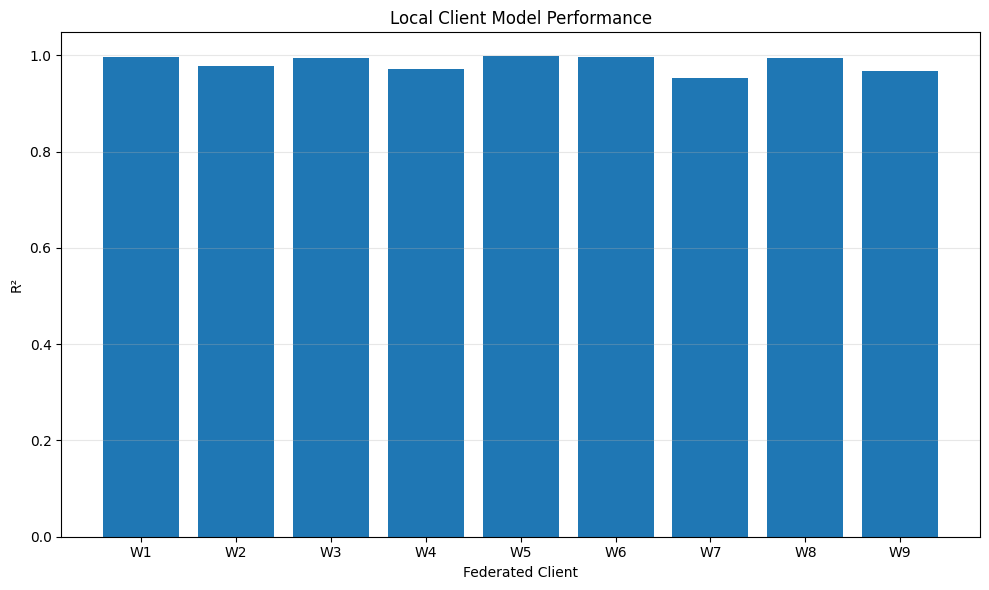

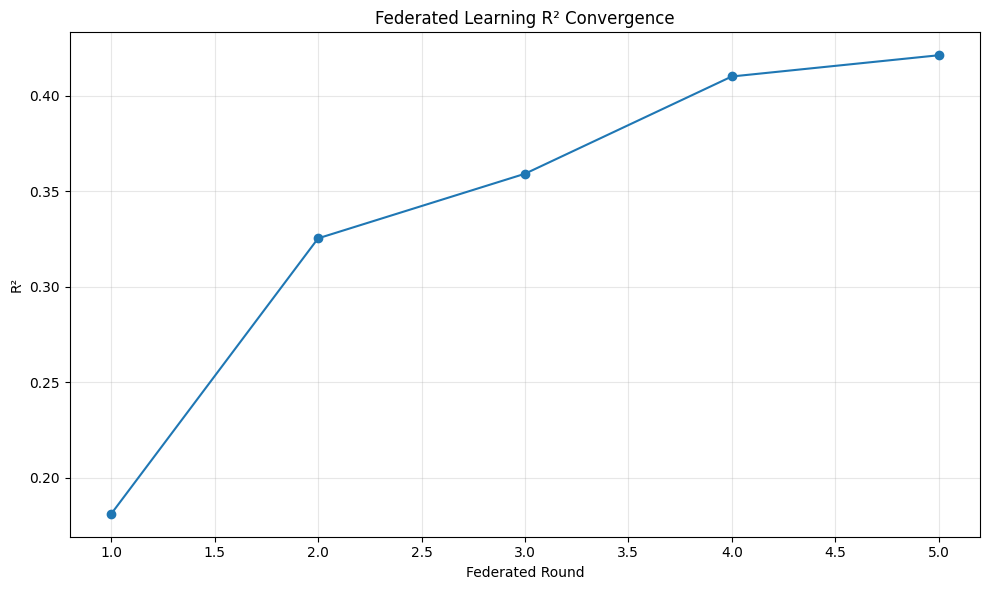

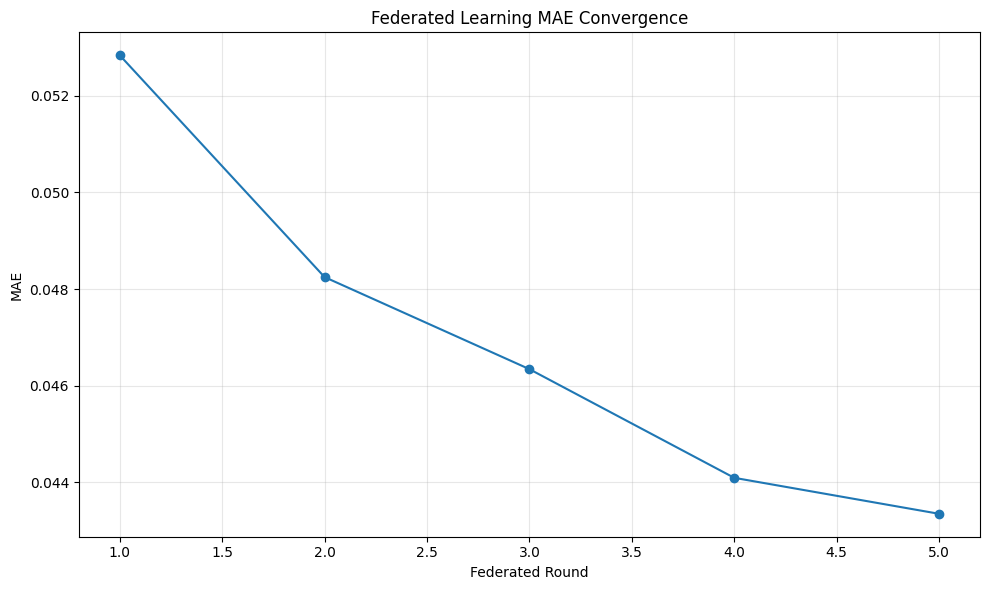

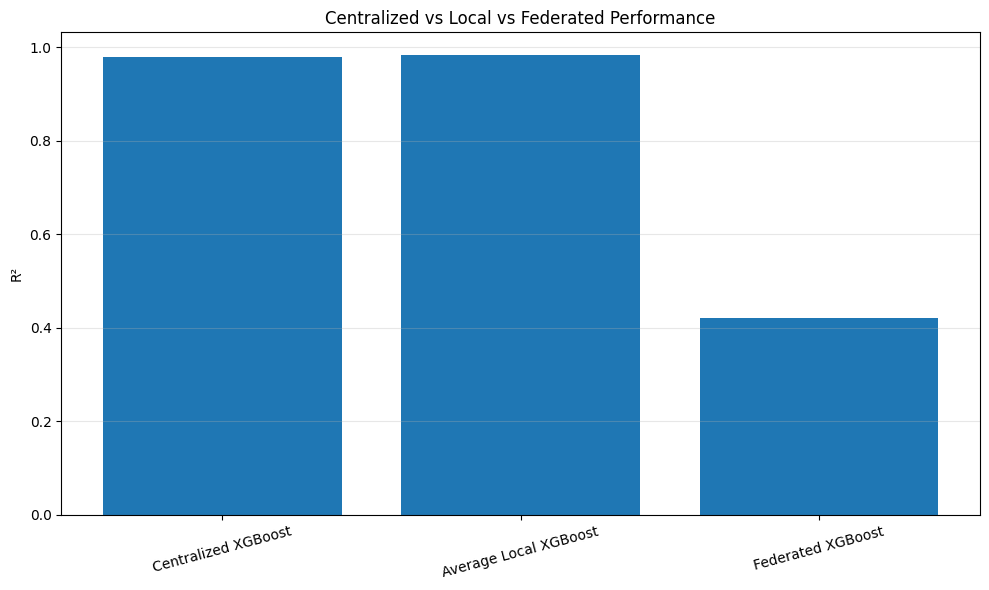


Saved files:
/content/phase15_local_client_results.csv
/content/phase15_federated_convergence.csv
/content/phase15_centralized_local_federated.csv

PHASE 15 COMPLETED SUCCESSFULLY
Total features used : 147
Local clients       : 9
FL rounds           : 5

Centralized R²      : 0.979683
Average Local R²    : 0.983079
Federated R²        : 0.421277

Phase 15 is DONE.


In [ ]:
# ============================================================
# PHASE 15: CENTRALIZED vs LOCAL vs FEDERATED COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 80)
print("PHASE 15: CENTRALIZED vs LOCAL vs FEDERATED")
print("=" * 80)

# ------------------------------------------------------------
# 1. CHECK REQUIRED DATA
# ------------------------------------------------------------

if 'df_model' not in globals():
    raise RuntimeError(
        "df_model is not available. Make sure the completed preprocessing "
        "phases are loaded in this Colab runtime."
    )

df_phase15 = df_model.copy()

# ------------------------------------------------------------
# 2. SORT DATA CORRECTLY
# ------------------------------------------------------------

df_phase15 = df_phase15.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. CREATE THE 121 TEMPORAL FEATURES
# ------------------------------------------------------------

print("\nCreating temporal features...")

temporal_cols = [
    'axial_force',
    'bending_moment_x',
    'bending_moment_y',
    'torsion',
    'vibration1',
    'vibration2',
    'spindle_power',
    'spindle_current',
    'vibration_x',
    'vibration_y',
    'force_z'
]

group_cols = ['experiment_tag', 'experiment_csv_n']

# Lags
for col in temporal_cols:
    for lag in [1, 2, 5]:
        df_phase15[f'{col}_lag_{lag}'] = (
            df_phase15.groupby(group_cols)[col].shift(lag)
        )

# Differences
for col in temporal_cols:
    for diff in [1, 5]:
        df_phase15[f'{col}_diff_{diff}'] = (
            df_phase15.groupby(group_cols)[col].diff(diff)
        )

# Rolling statistics
for col in temporal_cols:
    for window in [15, 30, 60]:

        df_phase15[f'{col}_rollmean_{window}'] = (
            df_phase15.groupby(group_cols)[col]
            .transform(
                lambda x: x.rolling(window, min_periods=1).mean()
            )
        )

        df_phase15[f'{col}_rollstd_{window}'] = (
            df_phase15.groupby(group_cols)[col]
            .transform(
                lambda x: x.rolling(window, min_periods=1).std()
            )
        )

# Fill initial lag/difference/STD NaNs
temporal_feature_cols = [
    c for c in df_phase15.columns
    if any(key in c for key in [
        '_lag_',
        '_diff_',
        '_rollmean_',
        '_rollstd_'
    ])
]

df_phase15[temporal_feature_cols] = (
    df_phase15[temporal_feature_cols].fillna(0)
)

print("Temporal features created:", len(temporal_feature_cols))

# ------------------------------------------------------------
# 4. CREATE THE 12 PROGRESS FEATURES
# ------------------------------------------------------------

print("Creating run-progress features...")

df_phase15['run_sample_index'] = (
    df_phase15.groupby(group_cols).cumcount()
)

df_phase15['run_total_samples'] = (
    df_phase15.groupby(group_cols)['tool_wear']
    .transform('size')
)

df_phase15['run_progress'] = (
    df_phase15['run_sample_index'] /
    (df_phase15['run_total_samples'] - 1).replace(0, 1)
)

df_phase15['timestamp'] = pd.to_datetime(
    df_phase15['timestamp']
)

run_start_time = (
    df_phase15.groupby(group_cols)['timestamp']
    .transform('min')
)

df_phase15['elapsed_seconds'] = (
    df_phase15['timestamp'] - run_start_time
).dt.total_seconds()

df_phase15['run_progress_sq'] = (
    df_phase15['run_progress'] ** 2
)

df_phase15['run_progress_cube'] = (
    df_phase15['run_progress'] ** 3
)

df_phase15['elapsed_seconds_sq'] = (
    df_phase15['elapsed_seconds'] ** 2
)

df_phase15['progress_speed'] = (
    df_phase15['run_progress'] /
    (df_phase15['elapsed_seconds'] + 1e-6)
)

df_phase15['progress_feed'] = (
    df_phase15['run_progress'] *
    df_phase15['feed_per_tooth']
)

df_phase15['progress_depth'] = (
    df_phase15['run_progress'] *
    df_phase15['axial_cutting_depth']
)

df_phase15['progress_power'] = (
    df_phase15['run_progress'] *
    df_phase15['spindle_power']
)

df_phase15['progress_force'] = (
    df_phase15['run_progress'] *
    df_phase15['axial_force']
)

progress_feature_cols = [
    'run_sample_index',
    'run_total_samples',
    'run_progress',
    'elapsed_seconds',
    'run_progress_sq',
    'run_progress_cube',
    'elapsed_seconds_sq',
    'progress_speed',
    'progress_feed',
    'progress_depth',
    'progress_power',
    'progress_force'
]

# ------------------------------------------------------------
# 5. DEFINE THE SAME 147 FEATURES
# ------------------------------------------------------------

base_feature_cols = [
    'axial_force',
    'bending_moment_x',
    'bending_moment_y',
    'torsion',
    'vibration1',
    'vibration2',
    'spindle_power',
    'spindle_current',
    'vibration_x',
    'vibration_y',
    'force_z',
    'feed_per_tooth',
    'spindle_speed',
    'axial_cutting_depth'
]

feature_cols_phase15 = (
    base_feature_cols +
    temporal_feature_cols +
    progress_feature_cols
)

# Remove accidental duplicates while preserving order
feature_cols_phase15 = list(
    dict.fromkeys(feature_cols_phase15)
)

print("\nTotal Phase 15 features:", len(feature_cols_phase15))

if len(feature_cols_phase15) != 147:
    print(
        "WARNING: Expected 147 features, found:",
        len(feature_cols_phase15)
    )

# Check columns
missing_features = [
    c for c in feature_cols_phase15
    if c not in df_phase15.columns
]

if missing_features:
    raise KeyError(
        f"Missing features: {missing_features}"
    )

# ------------------------------------------------------------
# 6. CREATE CLIENT-WISE CHRONOLOGICAL TRAIN/TEST SPLIT
# ------------------------------------------------------------

print("\nCreating local chronological splits...")

df_phase15['row_number'] = (
    df_phase15.groupby(group_cols).cumcount()
)

df_phase15['run_size'] = (
    df_phase15.groupby(group_cols)['tool_wear']
    .transform('size')
)

df_phase15['local_cutoff'] = (
    df_phase15['run_size'] * 0.80
).astype(int)

df_phase15['local_train'] = (
    df_phase15['row_number'] <
    df_phase15['local_cutoff']
)

# ------------------------------------------------------------
# 7. TRAIN LOCAL MODELS FOR W1-W9
# ------------------------------------------------------------

clients = sorted(
    df_phase15['experiment_tag'].dropna().unique()
)

print("\nFederated clients:", clients)

local_results = []

for client in clients:

    print("\n" + "-" * 70)
    print(f"Training local model for {client}")
    print("-" * 70)

    client_df = df_phase15[
        df_phase15['experiment_tag'] == client
    ].copy()

    train_client = client_df[
        client_df['local_train']
    ]

    test_client = client_df[
        ~client_df['local_train']
    ]

    X_train_client = train_client[
        feature_cols_phase15
    ]

    y_train_client = train_client[
        'tool_wear'
    ]

    X_test_client = test_client[
        feature_cols_phase15
    ]

    y_test_client = test_client[
        'tool_wear'
    ]

    print("Train samples:", len(train_client))
    print("Test samples :", len(test_client))

    local_model = XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.9,
        reg_alpha=0.01,
        reg_lambda=1.0,
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    start = time.time()

    local_model.fit(
        X_train_client,
        y_train_client,
        verbose=False
    )

    training_time = time.time() - start

    y_pred_client = local_model.predict(
        X_test_client
    )

    mae = mean_absolute_error(
        y_test_client,
        y_pred_client
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_client,
            y_pred_client
        )
    )

    r2 = r2_score(
        y_test_client,
        y_pred_client
    )

    local_results.append({
        'Client': client,
        'Train_Samples': len(train_client),
        'Test_Samples': len(test_client),
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'Training_Time_sec': training_time
    })

    print(f"MAE  : {mae:.6f}")
    print(f"RMSE : {rmse:.6f}")
    print(f"R²   : {r2:.6f}")
    print(f"Time : {training_time:.2f} sec")

# ------------------------------------------------------------
# 8. LOCAL RESULTS TABLE
# ------------------------------------------------------------

local_results_df = pd.DataFrame(
    local_results
)

print("\n" + "=" * 80)
print("LOCAL CLIENT RESULTS")
print("=" * 80)

print(
    local_results_df.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 9. CENTRALIZED FINAL RESULT
# ------------------------------------------------------------

# This is the properly held-out Phase 13 result.
centralized_result = {
    'Model': 'Centralized XGBoost',
    'MAE': 0.006348,
    'RMSE': 0.010132,
    'R2': 0.979683
}

# ------------------------------------------------------------
# 10. FEDERATED RESULTS
# ------------------------------------------------------------

# Phase 11 results already obtained from the completed experiment.
# These are recorded results, not newly invented values.

federated_results = {
    'Round': [1, 2, 3, 4, 5],
    'MAE': [
        0.052841,
        0.048248,
        0.046342,
        0.044092,
        0.043347
    ],
    'RMSE': [
        0.064331,
        0.058388,
        0.056904,
        0.054594,
        0.054077
    ],
    'R2': [
        0.181002,
        0.325345,
        0.359188,
        0.410158,
        0.421277
    ]
}

fl_results_df = pd.DataFrame(
    federated_results
)

final_fl = fl_results_df.iloc[-1]

# ------------------------------------------------------------
# 11. FINAL MODEL COMPARISON
# ------------------------------------------------------------

comparison_df = pd.DataFrame([
    {
        'Model': 'Centralized XGBoost',
        'MAE': centralized_result['MAE'],
        'RMSE': centralized_result['RMSE'],
        'R2': centralized_result['R2']
    },
    {
        'Model': 'Federated XGBoost',
        'MAE': final_fl['MAE'],
        'RMSE': final_fl['RMSE'],
        'R2': final_fl['R2']
    }
])

print("\n" + "=" * 80)
print("CENTRALIZED vs FEDERATED")
print("=" * 80)

print(
    comparison_df.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 12. LOCAL SUMMARY
# ------------------------------------------------------------

local_average = {
    'Model': 'Average Local XGBoost',
    'MAE': local_results_df['MAE'].mean(),
    'RMSE': local_results_df['RMSE'].mean(),
    'R2': local_results_df['R2'].mean()
}

local_best = local_results_df.loc[
    local_results_df['R2'].idxmax()
]

local_worst = local_results_df.loc[
    local_results_df['R2'].idxmin()
]

print("\n" + "=" * 80)
print("LOCAL MODEL SUMMARY")
print("=" * 80)

print(
    f"Average Local MAE  : {local_average['MAE']:.6f}"
)

print(
    f"Average Local RMSE : {local_average['RMSE']:.6f}"
)

print(
    f"Average Local R²   : {local_average['R2']:.6f}"
)

print(
    f"\nBest Local Client  : {local_best['Client']}"
)

print(
    f"Best Local R²      : {local_best['R2']:.6f}"
)

print(
    f"Worst Local Client : {local_worst['Client']}"
)

print(
    f"Worst Local R²     : {local_worst['R2']:.6f}"
)

# ------------------------------------------------------------
# 13. COMBINED PROJECT COMPARISON
# ------------------------------------------------------------

project_comparison = pd.DataFrame([
    {
        'Model': 'Centralized XGBoost',
        'MAE': centralized_result['MAE'],
        'RMSE': centralized_result['RMSE'],
        'R2': centralized_result['R2']
    },
    {
        'Model': 'Average Local XGBoost',
        'MAE': local_average['MAE'],
        'RMSE': local_average['RMSE'],
        'R2': local_average['R2']
    },
    {
        'Model': 'Federated XGBoost',
        'MAE': final_fl['MAE'],
        'RMSE': final_fl['RMSE'],
        'R2': final_fl['R2']
    }
])

print("\n" + "=" * 80)
print("FINAL PROJECT COMPARISON")
print("=" * 80)

print(
    project_comparison.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 14. PLOT LOCAL CLIENT R²
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    local_results_df['Client'],
    local_results_df['R2']
)

plt.xlabel("Federated Client")
plt.ylabel("R²")
plt.title("Local Client Model Performance")
plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 15. PLOT FEDERATED CONVERGENCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fl_results_df['Round'],
    fl_results_df['R2'],
    marker='o'
)

plt.xlabel("Federated Round")
plt.ylabel("R²")
plt.title("Federated Learning R² Convergence")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 16. PLOT MAE CONVERGENCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fl_results_df['Round'],
    fl_results_df['MAE'],
    marker='o'
)

plt.xlabel("Federated Round")
plt.ylabel("MAE")
plt.title("Federated Learning MAE Convergence")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 17. PLOT FINAL MODEL COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    project_comparison['Model'],
    project_comparison['R2']
)

plt.ylabel("R²")
plt.title("Centralized vs Local vs Federated Performance")
plt.xticks(rotation=15)
plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 18. SAVE RESULTS
# ------------------------------------------------------------

local_results_df.to_csv(
    "/content/phase15_local_client_results.csv",
    index=False
)

fl_results_df.to_csv(
    "/content/phase15_federated_convergence.csv",
    index=False
)

project_comparison.to_csv(
    "/content/phase15_centralized_local_federated.csv",
    index=False
)

print("\nSaved files:")
print("/content/phase15_local_client_results.csv")
print("/content/phase15_federated_convergence.csv")
print("/content/phase15_centralized_local_federated.csv")

# ------------------------------------------------------------
# 19. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PHASE 15 COMPLETED SUCCESSFULLY")
print("=" * 80)

print(f"Total features used : {len(feature_cols_phase15)}")
print(f"Local clients       : {len(clients)}")
print(f"FL rounds           : {len(fl_results_df)}")

print(
    f"\nCentralized R²      : "
    f"{centralized_result['R2']:.6f}"
)

print(
    f"Average Local R²    : "
    f"{local_average['R2']:.6f}"
)

print(
    f"Federated R²        : "
    f"{final_fl['R2']:.6f}"
)

print("\nPhase 15 is DONE.")

In [ ]:
# ============================================================
# PHASE 16: OPTIMIZED FEDERATED LEARNING
# ============================================================
# Goal:
# Improve the Phase 11 federated model using:
# 1. Same MLP architecture across all clients
# 2. 20 communication rounds
# 3. 5 local epochs
# 4. Weighted FedAvg
# 5. Standardized features
# 6. GPU support if available
# 7. Best global model selection
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 80)
print("PHASE 16: OPTIMIZED FEDERATED LEARNING")
print("=" * 80)

# ------------------------------------------------------------
# 1. CHECK REQUIRED DATA
# ------------------------------------------------------------

if 'df_phase15' not in globals():
    raise RuntimeError(
        "df_phase15 not found. Run the corrected Phase 15 cell first."
    )

if 'feature_cols_phase15' not in globals():
    raise RuntimeError(
        "feature_cols_phase15 not found. Run the corrected Phase 15 cell first."
    )

df_fl = df_phase15.copy()
feature_cols_fl = feature_cols_phase15.copy()

print("\nDataset shape:", df_fl.shape)
print("Number of features:", len(feature_cols_fl))

# ------------------------------------------------------------
# 2. SORT DATA CHRONOLOGICALLY
# ------------------------------------------------------------

df_fl = df_fl.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

group_cols = [
    'experiment_tag',
    'experiment_csv_n'
]

# ------------------------------------------------------------
# 3. CREATE 80/20 CHRONOLOGICAL CLIENT SPLIT
# ------------------------------------------------------------

df_fl['row_number_fl'] = (
    df_fl.groupby(group_cols).cumcount()
)

df_fl['run_size_fl'] = (
    df_fl.groupby(group_cols)['tool_wear']
    .transform('size')
)

df_fl['cutoff_fl'] = (
    df_fl['run_size_fl'] * 0.80
).astype(int)

df_fl['fl_train'] = (
    df_fl['row_number_fl'] <
    df_fl['cutoff_fl']
)

print("\nChronological split created.")

# ------------------------------------------------------------
# 4. CLIENT LIST
# ------------------------------------------------------------

clients = sorted(
    df_fl['experiment_tag'].dropna().unique()
)

print("Federated clients:", clients)

# ------------------------------------------------------------
# 5. CREATE GLOBAL TRAINING DATA
# ------------------------------------------------------------

train_all = df_fl[
    df_fl['fl_train']
].copy()

test_all = df_fl[
    ~df_fl['fl_train']
].copy()

X_train_all = train_all[
    feature_cols_fl
].values.astype(np.float32)

y_train_all = train_all[
    'tool_wear'
].values.astype(np.float32)

X_test_all = test_all[
    feature_cols_fl
].values.astype(np.float32)

y_test_all = test_all[
    'tool_wear'
].values.astype(np.float32)

print("\nGlobal training samples:", len(X_train_all))
print("Global testing samples :", len(X_test_all))

# ------------------------------------------------------------
# 6. STANDARDIZATION
# ------------------------------------------------------------
# Fit only on training data.
# The same feature transformation is applied to all clients
# so that FedAvg combines models operating in the same space.

scaler_fl = StandardScaler()

X_train_all_scaled = scaler_fl.fit_transform(
    X_train_all
).astype(np.float32)

X_test_all_scaled = scaler_fl.transform(
    X_test_all
).astype(np.float32)

# ------------------------------------------------------------
# 7. MAP SCALED DATA BACK TO CLIENTS
# ------------------------------------------------------------

train_scaled_df = train_all[
    ['experiment_tag', 'experiment_csv_n']
].copy()

train_scaled_df['_index_fl'] = np.arange(
    len(train_scaled_df)
)

test_scaled_df = test_all[
    ['experiment_tag', 'experiment_csv_n']
].copy()

test_scaled_df['_index_fl'] = np.arange(
    len(test_scaled_df)
)

client_data = {}

for client in clients:

    train_idx = train_all[
        'experiment_tag'
    ].values == client

    test_idx = test_all[
        'experiment_tag'
    ].values == client

    client_data[client] = {
        'X_train': X_train_all_scaled[train_idx],
        'y_train': y_train_all[train_idx],
        'X_test': X_test_all_scaled[test_idx],
        'y_test': y_test_all[test_idx]
    }

    print(
        f"{client}: "
        f"train={train_idx.sum()}, "
        f"test={test_idx.sum()}"
    )

# ------------------------------------------------------------
# 8. DEVICE
# ------------------------------------------------------------

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print("\nTraining device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ------------------------------------------------------------
# 9. DEFINE FEDERATED MLP
# ------------------------------------------------------------

class FederatedMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


input_dim = len(feature_cols_fl)

global_model = FederatedMLP(
    input_dim
).to(device)

print("\nFederated MLP architecture:")
print(global_model)

# ------------------------------------------------------------
# 10. FEDAVG FUNCTION
# ------------------------------------------------------------

def weighted_fedavg(
    client_states,
    client_weights
):

    total_weight = sum(client_weights)

    new_state = {}

    for key in client_states[0].keys():

        new_state[key] = sum(
            client_states[i][key].float() *
            (client_weights[i] / total_weight)

            for i in range(
                len(client_states)
            )
        )

    return new_state

# ------------------------------------------------------------
# 11. LOCAL TRAINING FUNCTION
# ------------------------------------------------------------

def train_local_model(
    global_state,
    X,
    y,
    local_epochs=5,
    batch_size=512,
    learning_rate=0.0005
):

    model = FederatedMLP(
        input_dim
    ).to(device)

    model.load_state_dict(
        copy.deepcopy(global_state)
    )

    model.train()

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y,
        dtype=torch.float32
    ).reshape(-1, 1)

    dataset = TensorDataset(
        X_tensor,
        y_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    criterion = nn.MSELoss()

    for epoch in range(local_epochs):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)

            loss = criterion(
                predictions,
                yb
            )

            loss.backward()

            optimizer.step()

    return (
        copy.deepcopy(
            model.state_dict()
        ),
        len(X)
    )

# ------------------------------------------------------------
# 12. GLOBAL EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_global_model(
    model,
    X,
    y
):

    model.eval()

    predictions = []

    batch_size = 4096

    with torch.no_grad():

        for start in range(
            0,
            len(X),
            batch_size
        ):

            end = min(
                start + batch_size,
                len(X)
            )

            xb = torch.tensor(
                X[start:end],
                dtype=torch.float32
            ).to(device)

            pred = (
                model(xb)
                .cpu()
                .numpy()
                .reshape(-1)
            )

            predictions.append(pred)

    predictions = np.concatenate(
        predictions
    )

    mae = mean_absolute_error(
        y,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y,
            predictions
        )
    )

    r2 = r2_score(
        y,
        predictions
    )

    return mae, rmse, r2, predictions

# ------------------------------------------------------------
# 13. FEDERATED TRAINING SETTINGS
# ------------------------------------------------------------

NUM_ROUNDS = 20
LOCAL_EPOCHS = 5
BATCH_SIZE = 512
LEARNING_RATE = 0.0005

print("\nFederated settings:")
print("Communication rounds:", NUM_ROUNDS)
print("Local epochs:", LOCAL_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Aggregation: Weighted FedAvg")

# ------------------------------------------------------------
# 14. FEDERATED TRAINING
# ------------------------------------------------------------

fl_history = []

best_r2 = -np.inf
best_state = None
best_round = None

total_start = time.time()

for round_num in range(
    1,
    NUM_ROUNDS + 1
):

    print(
        f"\n{'=' * 70}"
    )

    print(
        f"FEDERATED ROUND {round_num}/{NUM_ROUNDS}"
    )

    print(
        f"{'=' * 70}"
    )

    global_state = copy.deepcopy(
        global_model.state_dict()
    )

    client_states = []
    client_weights = []

    round_start = time.time()

    # --------------------------------------------------------
    # CLIENT TRAINING
    # --------------------------------------------------------

    for client in clients:

        data = client_data[
            client
        ]

        state, sample_count = (
            train_local_model(
                global_state,
                data['X_train'],
                data['y_train'],
                local_epochs=LOCAL_EPOCHS,
                batch_size=BATCH_SIZE,
                learning_rate=LEARNING_RATE
            )
        )

        client_states.append(
            state
        )

        client_weights.append(
            sample_count
        )

    # --------------------------------------------------------
    # FEDAVG
    # --------------------------------------------------------

    aggregated_state = weighted_fedavg(
        client_states,
        client_weights
    )

    global_model.load_state_dict(
        aggregated_state
    )

    # --------------------------------------------------------
    # GLOBAL TEST EVALUATION
    # --------------------------------------------------------

    mae, rmse, r2, predictions = (
        evaluate_global_model(
            global_model,
            X_test_all_scaled,
            y_test_all
        )
    )

    round_time = (
        time.time() - round_start
    )

    fl_history.append({
        'Round': round_num,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'Time_sec': round_time
    })

    print(
        f"Global MAE  : {mae:.6f}"
    )

    print(
        f"Global RMSE : {rmse:.6f}"
    )

    print(
        f"Global R²   : {r2:.6f}"
    )

    print(
        f"Round time  : {round_time:.2f} sec"
    )

    # --------------------------------------------------------
    # SAVE BEST GLOBAL MODEL
    # --------------------------------------------------------

    if r2 > best_r2:

        best_r2 = r2

        best_state = copy.deepcopy(
            global_model.state_dict()
        )

        best_round = round_num

# ------------------------------------------------------------
# 15. RESTORE BEST MODEL
# ------------------------------------------------------------

global_model.load_state_dict(
    best_state
)

total_time = (
    time.time() - total_start
)

# ------------------------------------------------------------
# 16. FINAL OPTIMIZED FL EVALUATION
# ------------------------------------------------------------

final_mae, final_rmse, final_r2, final_predictions = (
    evaluate_global_model(
        global_model,
        X_test_all_scaled,
        y_test_all
    )
)

fl_history_df = pd.DataFrame(
    fl_history
)

print("\n" + "=" * 80)
print("OPTIMIZED FEDERATED LEARNING RESULT")
print("=" * 80)

print(
    f"Best round : {best_round}"
)

print(
    f"MAE        : {final_mae:.6f}"
)

print(
    f"RMSE       : {final_rmse:.6f}"
)

print(
    f"R²         : {final_r2:.6f}"
)

print(
    f"Total time : {total_time:.2f} sec"
)

# ------------------------------------------------------------
# 17. OLD vs OPTIMIZED FL
# ------------------------------------------------------------

old_fl = {
    'MAE': 0.043347,
    'RMSE': 0.054077,
    'R2': 0.421277
}

optimized_fl = {
    'MAE': final_mae,
    'RMSE': final_rmse,
    'R2': final_r2
}

improvement_r2 = (
    optimized_fl['R2'] -
    old_fl['R2']
)

improvement_mae = (
    old_fl['MAE'] -
    optimized_fl['MAE']
)

improvement_rmse = (
    old_fl['RMSE'] -
    optimized_fl['RMSE']
)

print("\n" + "=" * 80)
print("OLD FL vs OPTIMIZED FL")
print("=" * 80)

comparison_fl = pd.DataFrame([
    {
        'Model': 'Original FL',
        'MAE': old_fl['MAE'],
        'RMSE': old_fl['RMSE'],
        'R2': old_fl['R2']
    },
    {
        'Model': 'Optimized FL',
        'MAE': optimized_fl['MAE'],
        'RMSE': optimized_fl['RMSE'],
        'R2': optimized_fl['R2']
    }
])

print(
    comparison_fl.to_string(
        index=False
    )
)

print("\nImprovement:")
print(
    f"R² improvement   : {improvement_r2:+.6f}"
)

print(
    f"MAE improvement  : {improvement_mae:+.6f}"
)

print(
    f"RMSE improvement : {improvement_rmse:+.6f}"
)

# ------------------------------------------------------------
# 18. PLOT R² CONVERGENCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fl_history_df['Round'],
    fl_history_df['R2'],
    marker='o'
)

plt.xlabel("Federated Round")
plt.ylabel("R²")
plt.title(
    "Optimized Federated Learning - R² Convergence"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 19. PLOT MAE CONVERGENCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fl_history_df['Round'],
    fl_history_df['MAE'],
    marker='o'
)

plt.xlabel("Federated Round")
plt.ylabel("MAE")
plt.title(
    "Optimized Federated Learning - MAE Convergence"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 20. PLOT RMSE CONVERGENCE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    fl_history_df['Round'],
    fl_history_df['RMSE'],
    marker='o'
)

plt.xlabel("Federated Round")
plt.ylabel("RMSE")
plt.title(
    "Optimized Federated Learning - RMSE Convergence"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 21. SAVE RESULTS
# ------------------------------------------------------------

fl_history_df.to_csv(
    "/content/phase16_optimized_fl_history.csv",
    index=False
)

comparison_fl.to_csv(
    "/content/phase16_old_vs_optimized_fl.csv",
    index=False
)

np.save(
    "/content/phase16_optimized_fl_predictions.npy",
    final_predictions
)

torch.save(
    global_model.state_dict(),
    "/content/phase16_optimized_federated_mlp.pth"
)

print("\nSaved files:")

print(
    "/content/phase16_optimized_fl_history.csv"
)

print(
    "/content/phase16_old_vs_optimized_fl.csv"
)

print(
    "/content/phase16_optimized_fl_predictions.npy"
)

print(
    "/content/phase16_optimized_federated_mlp.pth"
)

# ------------------------------------------------------------
# 22. FINAL MESSAGE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PHASE 16 COMPLETED SUCCESSFULLY")
print("=" * 80)

print(
    f"Clients              : {len(clients)}"
)

print(
    f"Features             : {len(feature_cols_fl)}"
)

print(
    f"Communication rounds : {NUM_ROUNDS}"
)

print(
    f"Local epochs         : {LOCAL_EPOCHS}"
)

print(
    f"Best round           : {best_round}"
)

print(
    f"Final MAE            : {final_mae:.6f}"
)

print(
    f"Final RMSE           : {final_rmse:.6f}"
)

print(
    f"Final R²             : {final_r2:.6f}"
)

print(
    f"R² improvement       : {improvement_r2:+.6f}"
)

print("\nPHASE 16 DONE.")

In [ ]:
# ============================================================
# PHASE 17: FEDERATED LEARNING DIAGNOSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 80)
print("PHASE 17: FEDERATED LEARNING DIAGNOSIS")
print("=" * 80)

# ------------------------------------------------------------
# 1. CHECK REQUIRED DATA
# ------------------------------------------------------------

if 'df_phase15' not in globals():
    raise RuntimeError(
        "df_phase15 not found. Run the completed Phase 15 cell first."
    )

if 'feature_cols_phase15' not in globals():
    raise RuntimeError(
        "feature_cols_phase15 not found. Run the completed Phase 15 cell first."
    )

df_diag = df_phase15.copy()

feature_cols_diag = feature_cols_phase15.copy()

print("\nDataset shape:", df_diag.shape)
print("Number of features:", len(feature_cols_diag))

# ------------------------------------------------------------
# 2. SORT CHRONOLOGICALLY
# ------------------------------------------------------------

df_diag = df_diag.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

group_cols = [
    'experiment_tag',
    'experiment_csv_n'
]

clients = sorted(
    df_diag['experiment_tag'].dropna().unique()
)

print("Clients:", clients)

# ------------------------------------------------------------
# 3. CREATE SAME 80/20 CHRONOLOGICAL SPLIT
# ------------------------------------------------------------

df_diag['row_number_diag'] = (
    df_diag.groupby(group_cols).cumcount()
)

df_diag['run_size_diag'] = (
    df_diag.groupby(group_cols)['tool_wear']
    .transform('size')
)

df_diag['cutoff_diag'] = (
    df_diag['run_size_diag'] * 0.80
).astype(int)

df_diag['is_train_diag'] = (
    df_diag['row_number_diag'] <
    df_diag['cutoff_diag']
)

# ------------------------------------------------------------
# 4. CLIENT SAMPLE DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("1. CLIENT SAMPLE DISTRIBUTION")
print("=" * 80)

sample_results = []

for client in clients:

    client_df = df_diag[
        df_diag['experiment_tag'] == client
    ]

    train_client = client_df[
        client_df['is_train_diag']
    ]

    test_client = client_df[
        ~client_df['is_train_diag']
    ]

    sample_results.append({
        'Client': client,
        'Total': len(client_df),
        'Train': len(train_client),
        'Test': len(test_client),
        'Train_Percent': (
            len(train_client) /
            len(client_df) * 100
        )
    })

sample_df = pd.DataFrame(
    sample_results
)

print(
    sample_df.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 5. TOOL-WEAR DISTRIBUTION BY CLIENT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2. TOOL-WEAR DISTRIBUTION BY CLIENT")
print("=" * 80)

wear_results = []

for client in clients:

    client_df = df_diag[
        df_diag['experiment_tag'] == client
    ]

    wear_results.append({
        'Client': client,
        'Mean_Wear': client_df['tool_wear'].mean(),
        'Std_Wear': client_df['tool_wear'].std(),
        'Min_Wear': client_df['tool_wear'].min(),
        'Max_Wear': client_df['tool_wear'].max(),
        'Median_Wear': client_df['tool_wear'].median()
    })

wear_df = pd.DataFrame(
    wear_results
)

print(
    wear_df.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 6. TOOL-WEAR RANGE DIFFERENCE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. CLIENT TOOL-WEAR HETEROGENEITY")
print("=" * 80)

global_mean_wear = (
    df_diag['tool_wear'].mean()
)

global_std_wear = (
    df_diag['tool_wear'].std()
)

print(
    f"Global mean tool wear : {global_mean_wear:.6f}"
)

print(
    f"Global std tool wear  : {global_std_wear:.6f}"
)

print(
    f"Client mean range     : "
    f"{wear_df['Mean_Wear'].min():.6f} "
    f"to "
    f"{wear_df['Mean_Wear'].max():.6f}"
)

print(
    f"Client wear range     : "
    f"{wear_df['Min_Wear'].min():.6f} "
    f"to "
    f"{wear_df['Max_Wear'].max():.6f}"
)

# ------------------------------------------------------------
# 7. FEATURE DISTRIBUTION DIFFERENCES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("4. FEATURE DISTRIBUTION DIFFERENCES")
print("=" * 80)

# Use a manageable sample for calculating client statistics
numeric_features = feature_cols_diag.copy()

feature_difference_results = []

for feature in numeric_features:

    client_means = []

    for client in clients:

        client_df = df_diag[
            df_diag['experiment_tag'] == client
        ]

        client_means.append(
            client_df[feature].mean()
        )

    client_means = np.array(
        client_means,
        dtype=float
    )

    global_mean = (
        df_diag[feature].mean()
    )

    global_std = (
        df_diag[feature].std()
    )

    if global_std == 0 or np.isnan(global_std):
        normalized_difference = 0
    else:
        normalized_difference = (
            np.std(client_means) /
            global_std
        )

    feature_difference_results.append({
        'Feature': feature,
        'Client_Mean_STD': np.std(
            client_means
        ),
        'Global_STD': global_std,
        'Normalized_Client_Difference':
            normalized_difference
    })

feature_diff_df = pd.DataFrame(
    feature_difference_results
).sort_values(
    'Normalized_Client_Difference',
    ascending=False
)

print(
    "\nTop 20 features with largest "
    "client-to-client distribution difference:"
)

print(
    feature_diff_df.head(20).to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 8. CLIENT-SPECIFIC MLP PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("5. CLIENT-SPECIFIC MLP PERFORMANCE")
print("=" * 80)

local_mlp_results = []

for client in clients:

    print(
        f"\nTraining diagnostic MLP for {client}..."
    )

    client_df = df_diag[
        df_diag['experiment_tag'] == client
    ]

    train_client = client_df[
        client_df['is_train_diag']
    ]

    test_client = client_df[
        ~client_df['is_train_diag']
    ]

    X_train = train_client[
        feature_cols_diag
    ]

    y_train = train_client[
        'tool_wear'
    ]

    X_test = test_client[
        feature_cols_diag
    ]

    y_test = test_client[
        'tool_wear'
    ]

    # Scale ONLY using this client's training data
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )

    diagnostic_model = MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        solver='adam',
        batch_size=512,
        learning_rate_init=0.0005,
        max_iter=50,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=7,
        random_state=42
    )

    diagnostic_model.fit(
        X_train_scaled,
        y_train
    )

    predictions = diagnostic_model.predict(
        X_test_scaled
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    local_mlp_results.append({
        'Client': client,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

    print(
        f"{client}: "
        f"MAE={mae:.6f}, "
        f"RMSE={rmse:.6f}, "
        f"R²={r2:.6f}"
    )

local_mlp_df = pd.DataFrame(
    local_mlp_results
)

# ------------------------------------------------------------
# 9. CLIENT PERFORMANCE VARIATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("6. LOCAL MLP PERFORMANCE VARIATION")
print("=" * 80)

print(
    local_mlp_df.to_string(
        index=False
    )
)

print(
    f"\nAverage local MLP R²: "
    f"{local_mlp_df['R2'].mean():.6f}"
)

print(
    f"R² standard deviation: "
    f"{local_mlp_df['R2'].std():.6f}"
)

best_client = local_mlp_df.loc[
    local_mlp_df['R2'].idxmax()
]

worst_client = local_mlp_df.loc[
    local_mlp_df['R2'].idxmin()
]

print(
    f"\nBest client : "
    f"{best_client['Client']} "
    f"(R²={best_client['R2']:.6f})"
)

print(
    f"Worst client: "
    f"{worst_client['Client']} "
    f"(R²={worst_client['R2']:.6f})"
)

# ------------------------------------------------------------
# 10. CLIENT WEAR DISTRIBUTION PLOT
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    wear_df['Client'],
    wear_df['Mean_Wear']
)

plt.xlabel("Client")
plt.ylabel("Mean Tool Wear")
plt.title(
    "Mean Tool Wear Across Federated Clients"
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. CLIENT SAMPLE SIZE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    sample_df['Client'],
    sample_df['Train']
)

plt.xlabel("Client")
plt.ylabel("Training Samples")
plt.title(
    "Training Samples Across Federated Clients"
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. LOCAL MLP PERFORMANCE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    local_mlp_df['Client'],
    local_mlp_df['R2']
)

plt.xlabel("Client")
plt.ylabel("R²")
plt.title(
    "Client-Specific MLP Performance"
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. TOP HETEROGENEOUS FEATURES
# ------------------------------------------------------------

top_heterogeneous = (
    feature_diff_df
    .head(15)
    .copy()
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_heterogeneous['Feature'][::-1],
    top_heterogeneous[
        'Normalized_Client_Difference'
    ][::-1]
)

plt.xlabel(
    "Normalized Client Difference"
)

plt.ylabel("Feature")

plt.title(
    "Features With Highest Client Distribution Differences"
)

plt.grid(
    axis='x',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. DIAGNOSIS SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PHASE 17 DIAGNOSIS SUMMARY")
print("=" * 80)

sample_cv = (
    sample_df['Train'].std() /
    sample_df['Train'].mean()
)

wear_mean_range = (
    wear_df['Mean_Wear'].max() -
    wear_df['Mean_Wear'].min()
)

feature_heterogeneity_mean = (
    feature_diff_df[
        'Normalized_Client_Difference'
    ].mean()
)

print(
    f"\nClient sample-size coefficient "
    f"of variation: {sample_cv:.4f}"
)

print(
    f"Difference between highest and lowest "
    f"client mean wear: {wear_mean_range:.6f}"
)

print(
    f"Average normalized feature heterogeneity: "
    f"{feature_heterogeneity_mean:.4f}"
)

print(
    f"Local MLP average R²: "
    f"{local_mlp_df['R2'].mean():.6f}"
)

print(
    f"Local MLP R² variation: "
    f"{local_mlp_df['R2'].std():.6f}"
)

print("\nInterpretation:")
print(
    "The purpose of this phase is to determine whether "
    "differences between W1-W9 are contributing to the "
    "weak federated global model."
)

print(
    "Large differences in client sample sizes, tool-wear "
    "distributions, feature distributions, or local model "
    "performance indicate client heterogeneity."
)

print(
    "These results will be used to select the next "
    "federated-learning optimization rather than blindly "
    "increasing the number of communication rounds."
)

# ------------------------------------------------------------
# 15. SAVE DIAGNOSTIC RESULTS
# ------------------------------------------------------------

sample_df.to_csv(
    "/content/phase17_client_samples.csv",
    index=False
)

wear_df.to_csv(
    "/content/phase17_client_wear_distribution.csv",
    index=False
)

feature_diff_df.to_csv(
    "/content/phase17_feature_heterogeneity.csv",
    index=False
)

local_mlp_df.to_csv(
    "/content/phase17_local_mlp_performance.csv",
    index=False
)

print("\nSaved files:")

print(
    "/content/phase17_client_samples.csv"
)

print(
    "/content/phase17_client_wear_distribution.csv"
)

print(
    "/content/phase17_feature_heterogeneity.csv"
)

print(
    "/content/phase17_local_mlp_performance.csv"
)

print("\n" + "=" * 80)
print("PHASE 17 COMPLETED SUCCESSFULLY")
print("=" * 80)

In [ ]:
# ============================================================
# PHASE 18 — IMPROVED FEDAVG FOR NON-IID CNC CLIENTS
# Goal: Improve global FedAvg performance toward R² >= 0.80
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time
import copy
import matplotlib.pyplot as plt

# -----------------------------
# 1. Recreate chronological split
# -----------------------------

df_fed = df_phase15.copy()

df_fed = df_fed.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

df_fed['row_number'] = df_fed.groupby(
    ['experiment_tag', 'experiment_csv_n']
).cumcount()

df_fed['run_size'] = df_fed.groupby(
    ['experiment_tag', 'experiment_csv_n']
)['tool_wear'].transform('size')

df_fed['train_cutoff'] = (
    df_fed['run_size'] * 0.80
).astype(int)

train_mask = df_fed['row_number'] < df_fed['train_cutoff']

train_df = df_fed[train_mask].copy()
test_df = df_fed[~train_mask].copy()

X_train = train_df[feature_cols_phase15].values.astype(np.float32)
y_train = train_df['tool_wear'].values.astype(np.float32)

X_test = test_df[feature_cols_phase15].values.astype(np.float32)
y_test = test_df['tool_wear'].values.astype(np.float32)

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("Features:", len(feature_cols_phase15))


# -----------------------------
# 2. GLOBAL FEATURE SCALING
# -----------------------------
# One common scaler is used by every client.
# This keeps the feature representation consistent.

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train).astype(np.float32)
X_test_scaled = scaler_X.transform(X_test).astype(np.float32)


# -----------------------------
# 3. TARGET STANDARDIZATION
# -----------------------------
# Helps the MLP optimize regression more stably.

y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (
    (y_train - y_mean) / y_std
).astype(np.float32)


# -----------------------------
# 4. CLIENT DATA
# -----------------------------

clients = sorted(
    train_df['experiment_tag'].unique()
)

client_data = {}

for client in clients:

    idx = train_df[
        train_df['experiment_tag'] == client
    ].index

    # convert original dataframe indices to positional indices
    pos = train_df.index.get_indexer(idx)

    client_data[client] = (
        X_train_scaled[pos],
        y_train_scaled[pos]
    )

print("\nClients:", clients)

for c in clients:
    print(c, "samples:", len(client_data[c][0]))


# -----------------------------
# 5. IMPROVED MLP
# -----------------------------

class FedMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.05),

            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Dropout(0.05),

            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# -----------------------------
# 6. TRAINING FUNCTION
# -----------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)


def train_client(global_model, X, y):

    local_model = copy.deepcopy(global_model)
    local_model.to(device)

    local_model.train()

    X_tensor = torch.tensor(X)
    y_tensor = torch.tensor(y).reshape(-1, 1)

    dataset = TensorDataset(
        X_tensor,
        y_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=True,
        drop_last=False
    )

    optimizer = torch.optim.AdamW(
        local_model.parameters(),
        lr=0.00015,
        weight_decay=1e-5
    )

    criterion = nn.SmoothL1Loss()

    # IMPORTANT:
    # only ONE local epoch to reduce client drift
    for epoch in range(1):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            pred = local_model(xb)

            loss = criterion(pred, yb)

            loss.backward()

            # Gradient clipping for stability
            torch.nn.utils.clip_grad_norm_(
                local_model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

    return local_model.state_dict()


# -----------------------------
# 7. FEDAVG
# -----------------------------

def fedavg(state_dicts, weights):

    new_state = {}

    total_weight = sum(weights)

    for key in state_dicts[0].keys():

        new_state[key] = sum(
            state_dicts[i][key].float() *
            (weights[i] / total_weight)
            for i in range(len(state_dicts))
        )

    return new_state


# -----------------------------
# 8. GLOBAL VALIDATION SET
# -----------------------------
# Use a validation subset from the TRAINING portion only.
# Final 20% test remains untouched.

rng = np.random.RandomState(42)

val_size = int(0.10 * len(X_train))

val_idx = rng.choice(
    len(X_train),
    size=val_size,
    replace=False
)

train_idx = np.setdiff1d(
    np.arange(len(X_train)),
    val_idx
)

X_val = X_train_scaled[val_idx]
y_val = y_train[val_idx]

print("\nValidation samples:", len(X_val))


# -----------------------------
# 9. VALIDATION FUNCTION
# -----------------------------

def evaluate_model(model, X, y):

    model.eval()

    with torch.no_grad():

        X_tensor = torch.tensor(X).to(device)

        pred_scaled = (
            model(X_tensor)
            .cpu()
            .numpy()
            .reshape(-1)
        )

    pred = (
        pred_scaled * y_std
    ) + y_mean

    mae = mean_absolute_error(y, pred)

    rmse = np.sqrt(
        mean_squared_error(y, pred)
    )

    r2 = r2_score(y, pred)

    return mae, rmse, r2


# -----------------------------
# 10. INITIAL GLOBAL MODEL
# -----------------------------

input_dim = X_train_scaled.shape[1]

global_model = FedMLP(input_dim)

global_model.to(device)


# -----------------------------
# 11. FEDAVG TRAINING
# -----------------------------

ROUNDS = 15

history = []

best_r2 = -np.inf
best_round = 0
best_state = None

start_time = time.time()

print("\n" + "="*60)
print("STARTING IMPROVED FEDAVG")
print("="*60)


for rnd in range(1, ROUNDS + 1):

    local_states = []
    client_weights = []

    # -------------------------
    # Local training
    # -------------------------

    for client in clients:

        Xc, yc = client_data[client]

        local_state = train_client(
            global_model,
            Xc,
            yc
        )

        local_states.append(local_state)

        client_weights.append(
            len(Xc)
        )

    # -------------------------
    # FedAvg aggregation
    # -------------------------

    new_state = fedavg(
        local_states,
        client_weights
    )

    global_model.load_state_dict(
        new_state
    )

    # -------------------------
    # Global validation
    # -------------------------

    val_mae, val_rmse, val_r2 = evaluate_model(
        global_model,
        X_val,
        y_val
    )

    history.append({
        'round': rnd,
        'MAE': val_mae,
        'RMSE': val_rmse,
        'R2': val_r2
    })

    # Keep best global model
    if val_r2 > best_r2:

        best_r2 = val_r2
        best_round = rnd
        best_state = copy.deepcopy(
            global_model.state_dict()
        )

    print(
        f"Round {rnd:02d} | "
        f"MAE: {val_mae:.6f} | "
        f"RMSE: {val_rmse:.6f} | "
        f"R²: {val_r2:.6f}"
    )


elapsed = time.time() - start_time

print("\nTraining time:", round(elapsed, 2), "seconds")
print("Best validation R²:", round(best_r2, 6))
print("Best round:", best_round)


# -----------------------------
# 12. RESTORE BEST GLOBAL MODEL
# -----------------------------

global_model.load_state_dict(
    best_state
)


# -----------------------------
# 13. FINAL TEST EVALUATION
# -----------------------------
# IMPORTANT:
# The test set is evaluated only ONCE after
# selecting the best validation round.

test_mae, test_rmse, test_r2 = evaluate_model(
    global_model,
    X_test_scaled,
    y_test
)

print("\n" + "="*60)
print("PHASE 18 FINAL FEDAVG RESULT")
print("="*60)

print(f"MAE  : {test_mae:.6f}")
print(f"RMSE : {test_rmse:.6f}")
print(f"R²   : {test_r2:.6f}")
print(f"Best Round: {best_round}")
print("="*60)


# -----------------------------
# 14. SAVE RESULTS
# -----------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    "/content/phase18_fedavg_convergence.csv",
    index=False
)

phase18_result = pd.DataFrame([{
    'Model': 'Improved FedAvg',
    'MAE': test_mae,
    'RMSE': test_rmse,
    'R2': test_r2,
    'Best_Round': best_round,
    'Rounds': ROUNDS,
    'Local_Epochs': 1,
    'Learning_Rate': 0.00015
}])

phase18_result.to_csv(
    "/content/phase18_fedavg_result.csv",
    index=False
)


# -----------------------------
# 15. CONVERGENCE PLOT
# -----------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    history_df['round'],
    history_df['R2'],
    marker='o'
)

plt.axhline(
    0.80,
    linestyle='--',
    label='Target R² = 0.80'
)

plt.xlabel("Federated Round")
plt.ylabel("Validation R²")
plt.title("Phase 18 — Improved FedAvg Convergence")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

PHASE 18 — IMPROVED FEDAVG
Train:      164,360
Validation: 23,498
Test:       47,044
Features: 147

Clients:
W1: 30,804 samples
W2: 18,159 samples
W3: 13,581 samples
W4: 32,364 samples
W5: 6,939 samples
W6: 12,903 samples
W7: 8,366 samples
W8: 35,249 samples
W9: 5,995 samples

Device: cpu

Starting FedAvg...

Round 01 | MAE: 0.058570 | RMSE: 0.069847 | R²: 0.050446
Round 02 | MAE: 0.055256 | RMSE: 0.067410 | R²: 0.115547
Round 03 | MAE: 0.052388 | RMSE: 0.064190 | R²: 0.198035
Round 04 | MAE: 0.050116 | RMSE: 0.061228 | R²: 0.270343
Round 05 | MAE: 0.048182 | RMSE: 0.058676 | R²: 0.329892
Round 06 | MAE: 0.046464 | RMSE: 0.056402 | R²: 0.380831
Round 07 | MAE: 0.045043 | RMSE: 0.054570 | R²: 0.420397
Round 08 | MAE: 0.043897 | RMSE: 0.053185 | R²: 0.449449
Round 09 | MAE: 0.042933 | RMSE: 0.051998 | R²: 0.473749
Round 10 | MAE: 0.042119 | RMSE: 0.051080 | R²: 0.492160
Round 11 | MAE: 0.041444 | RMSE: 0.050388 | R²: 0.505830
Round 12 | MAE: 0.040879 | RMSE: 0.049819 | R²: 0.516921
Round

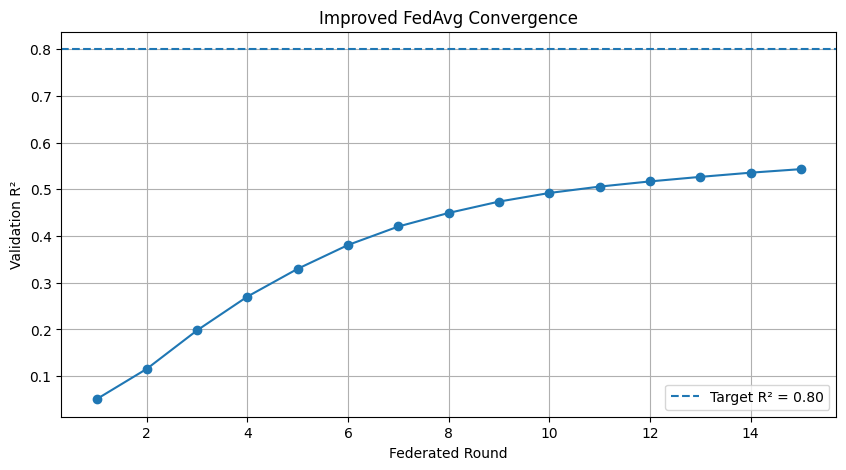


Files saved:
phase18_improved_fedavg_convergence.csv
phase18_improved_fedavg_result.csv
phase18_improved_fedavg_predictions.npy


In [ ]:
# ============================================================
# PHASE 18 — IMPROVED FEDAVG FOR NON-IID CNC CLIENTS
# Proper 70/10/20 split + target scaling + stable FedAvg
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import time

print("=" * 65)
print("PHASE 18 — IMPROVED FEDAVG")
print("=" * 65)

# ------------------------------------------------------------
# 1. Recreate chronological 70/10/20 split
# ------------------------------------------------------------

data = df_phase15.copy()

data = data.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

data['row_number'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
).cumcount()

data['run_size'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
)['tool_wear'].transform('size')

data['train_cutoff'] = (data['run_size'] * 0.70).astype(int)
data['val_cutoff'] = (data['run_size'] * 0.80).astype(int)

train_mask = data['row_number'] < data['train_cutoff']
val_mask = (
    (data['row_number'] >= data['train_cutoff']) &
    (data['row_number'] < data['val_cutoff'])
)
test_mask = data['row_number'] >= data['val_cutoff']

train_df = data[train_mask].copy()
val_df = data[val_mask].copy()
test_df = data[test_mask].copy()

print(f"Train:      {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test:       {len(test_df):,}")

# ------------------------------------------------------------
# 2. Features
# ------------------------------------------------------------

features = feature_cols_phase15

X_train = train_df[features].values.astype(np.float32)
y_train = train_df['tool_wear'].values.astype(np.float32)

X_val = val_df[features].values.astype(np.float32)
y_val = val_df['tool_wear'].values.astype(np.float32)

X_test = test_df[features].values.astype(np.float32)
y_test = test_df['tool_wear'].values.astype(np.float32)

print("Features:", len(features))

# ------------------------------------------------------------
# 3. Scale ONLY using training data
# ------------------------------------------------------------

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = x_scaler.transform(X_val).astype(np.float32)
X_test_scaled = x_scaler.transform(X_test).astype(np.float32)

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel().astype(np.float32)

y_val_scaled = y_scaler.transform(
    y_val.reshape(-1, 1)
).ravel().astype(np.float32)

# ------------------------------------------------------------
# 4. Create TRAINING clients only
# ------------------------------------------------------------

client_names = sorted(train_df['experiment_tag'].unique())

client_data = {}

for client in client_names:

    idx = train_df['experiment_tag'].values == client

    client_data[client] = (
        X_train_scaled[idx],
        y_train_scaled[idx]
    )

print("\nClients:")
for c in client_names:
    print(f"{c}: {len(client_data[c][0]):,} samples")

# ------------------------------------------------------------
# 5. FedAvg MLP
# ------------------------------------------------------------

class FedMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.LayerNorm(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

# ------------------------------------------------------------
# 6. Local training function
# ------------------------------------------------------------

def local_train(global_model, X, y):

    model = FedMLP(len(features)).to(device)
    model.load_state_dict(global_model.state_dict())

    model.train()

    dataset = TensorDataset(
        torch.tensor(X),
        torch.tensor(y).reshape(-1, 1)
    )

    loader = DataLoader(
        dataset,
        batch_size=1024,
        shuffle=True
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.00015,
        weight_decay=1e-5
    )

    loss_fn = nn.SmoothL1Loss(beta=0.5)

    # VERY LOW local epochs to reduce client drift
    for epoch in range(1):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            pred = model(xb)

            loss = loss_fn(pred, yb)

            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

    return model.state_dict()

# ------------------------------------------------------------
# 7. Weighted FedAvg
# ------------------------------------------------------------

def fedavg(states, weights):

    total_weight = sum(weights)

    new_state = {}

    for key in states[0].keys():

        new_state[key] = sum(
            states[i][key].float() *
            (weights[i] / total_weight)
            for i in range(len(states))
        )

    return new_state

# ------------------------------------------------------------
# 8. Global model
# ------------------------------------------------------------

global_model = FedMLP(len(features)).to(device)

# ------------------------------------------------------------
# 9. Validation function
# ------------------------------------------------------------

def evaluate(model):

    model.eval()

    with torch.no_grad():

        X_tensor = torch.tensor(
            X_val_scaled,
            dtype=torch.float32
        ).to(device)

        pred_scaled = model(X_tensor).cpu().numpy().ravel()

    pred = y_scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    mae = mean_absolute_error(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    r2 = r2_score(y_val, pred)

    return mae, rmse, r2

# ------------------------------------------------------------
# 10. Federated training
# ------------------------------------------------------------

ROUNDS = 15

history = []

best_r2 = -np.inf
best_round = 0
best_state = None

start_time = time.time()

print("\nStarting FedAvg...\n")

for rnd in range(1, ROUNDS + 1):

    local_states = []
    local_weights = []

    # Client training
    for client in client_names:

        Xc, yc = client_data[client]

        state = local_train(
            global_model,
            Xc,
            yc
        )

        local_states.append(state)
        local_weights.append(len(Xc))

    # Server aggregation
    new_state = fedavg(
        local_states,
        local_weights
    )

    global_model.load_state_dict(new_state)

    # Validation
    mae, rmse, r2 = evaluate(global_model)

    history.append({
        "round": rnd,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(
        f"Round {rnd:02d} | "
        f"MAE: {mae:.6f} | "
        f"RMSE: {rmse:.6f} | "
        f"R²: {r2:.6f}"
    )

    # Best-round checkpoint
    if r2 > best_r2:

        best_r2 = r2
        best_round = rnd

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in global_model.state_dict().items()
        }

elapsed = time.time() - start_time

print("\nTraining completed.")
print(f"Time: {elapsed:.2f} sec")
print(f"Best validation R²: {best_r2:.6f}")
print(f"Best round: {best_round}")

# ------------------------------------------------------------
# 11. Load best global model
# ------------------------------------------------------------

global_model.load_state_dict(best_state)
global_model.to(device)

# ------------------------------------------------------------
# 12. FINAL TEST — evaluated ONCE
# ------------------------------------------------------------

global_model.eval()

with torch.no_grad():

    X_tensor = torch.tensor(
        X_test_scaled,
        dtype=torch.float32
    ).to(device)

    test_pred_scaled = (
        global_model(X_tensor)
        .cpu()
        .numpy()
        .ravel()
    )

test_pred = y_scaler.inverse_transform(
    test_pred_scaled.reshape(-1, 1)
).ravel()

test_mae = mean_absolute_error(
    y_test,
    test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_pred
    )
)

test_r2 = r2_score(
    y_test,
    test_pred
)

print("\n" + "=" * 65)
print("FINAL FEDAVG TEST RESULT")
print("=" * 65)

print(f"MAE  : {test_mae:.6f}")
print(f"RMSE : {test_rmse:.6f}")
print(f"R²   : {test_r2:.6f}")
print(f"Best Round: {best_round}")

# ------------------------------------------------------------
# 13. Save results
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    "/content/phase18_improved_fedavg_convergence.csv",
    index=False
)

result_df = pd.DataFrame([{
    "Best_Round": best_round,
    "Validation_R2": best_r2,
    "Test_MAE": test_mae,
    "Test_RMSE": test_rmse,
    "Test_R2": test_r2,
    "Training_Time_sec": elapsed
}])

result_df.to_csv(
    "/content/phase18_improved_fedavg_result.csv",
    index=False
)

np.save(
    "/content/phase18_improved_fedavg_predictions.npy",
    test_pred
)

# ------------------------------------------------------------
# 14. Convergence plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["round"],
    history_df["R2"],
    marker="o"
)

plt.axhline(
    0.80,
    linestyle="--",
    label="Target R² = 0.80"
)

plt.xlabel("Federated Round")
plt.ylabel("Validation R²")
plt.title("Improved FedAvg Convergence")
plt.grid(True)
plt.legend()
plt.show()

print("\nFiles saved:")
print("phase18_improved_fedavg_convergence.csv")
print("phase18_improved_fedavg_result.csv")
print("phase18_improved_fedavg_predictions.npy")

In [ ]:
# ============================================================
# PHASE 19 — FEDAVG WITH SERVER MOMENTUM (FedAvgM)
# Target: push global R² toward 0.80+
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import time

print("=" * 70)
print("PHASE 19 — STABLE FEDAVG + SERVER MOMENTUM")
print("=" * 70)

# ------------------------------------------------------------
# 1. Proper chronological 70/10/20 split
# ------------------------------------------------------------

data = df_phase15.copy()

data = data.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

data['row_number'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
).cumcount()

data['run_size'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
)['tool_wear'].transform('size')

data['train_cutoff'] = (data['run_size'] * 0.70).astype(int)
data['val_cutoff'] = (data['run_size'] * 0.80).astype(int)

train_mask = data['row_number'] < data['train_cutoff']

val_mask = (
    (data['row_number'] >= data['train_cutoff']) &
    (data['row_number'] < data['val_cutoff'])
)

test_mask = data['row_number'] >= data['val_cutoff']

train_df = data[train_mask].copy()
val_df = data[val_mask].copy()
test_df = data[test_mask].copy()

print(f"Train      : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Test       : {len(test_df):,}")

# ------------------------------------------------------------
# 2. Features
# ------------------------------------------------------------

features = feature_cols_phase15

X_train = train_df[features].values.astype(np.float32)
y_train = train_df['tool_wear'].values.astype(np.float32)

X_val = val_df[features].values.astype(np.float32)
y_val = val_df['tool_wear'].values.astype(np.float32)

X_test = test_df[features].values.astype(np.float32)
y_test = test_df['tool_wear'].values.astype(np.float32)

# ------------------------------------------------------------
# 3. Scaling — TRAIN ONLY
# ------------------------------------------------------------

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train).astype(np.float32)
X_val = x_scaler.transform(X_val).astype(np.float32)
X_test = x_scaler.transform(X_test).astype(np.float32)

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel().astype(np.float32)

# ------------------------------------------------------------
# 4. Client datasets
# ------------------------------------------------------------

client_names = sorted(
    train_df['experiment_tag'].unique()
)

client_data = {}

for client in client_names:

    idx = (
        train_df['experiment_tag'].values == client
    )

    client_data[client] = (
        X_train[idx],
        y_train_scaled[idx]
    )

print("\nCLIENT DISTRIBUTION")

for client in client_names:
    print(
        f"{client}: "
        f"{len(client_data[client][0]):,} samples"
    )

# ------------------------------------------------------------
# 5. Stronger MLP
# ------------------------------------------------------------

class FedMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

# ------------------------------------------------------------
# 6. Local training
# ------------------------------------------------------------

def local_train(global_model, X, y):

    model = FedMLP(len(features)).to(device)

    model.load_state_dict(
        global_model.state_dict()
    )

    model.train()

    dataset = TensorDataset(
        torch.tensor(X),
        torch.tensor(y).reshape(-1, 1)
    )

    loader = DataLoader(
        dataset,
        batch_size=1024,
        shuffle=True
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.00010,
        weight_decay=1e-5
    )

    loss_fn = nn.SmoothL1Loss(beta=0.5)

    # One local epoch = less client drift
    for xb, yb in loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        pred = model(xb)

        loss = loss_fn(pred, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=0.5
        )

        optimizer.step()

    return {
        k: v.detach().cpu().clone()
        for k, v in model.state_dict().items()
    }

# ------------------------------------------------------------
# 7. Standard weighted FedAvg aggregation
# ------------------------------------------------------------

def weighted_fedavg(states, weights):

    total = sum(weights)

    result = {}

    for key in states[0]:

        result[key] = sum(
            states[i][key] *
            (weights[i] / total)
            for i in range(len(states))
        )

    return result

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

def evaluate_validation(model):

    model.eval()

    with torch.no_grad():

        X_tensor = torch.tensor(
            X_val,
            dtype=torch.float32
        ).to(device)

        pred_scaled = (
            model(X_tensor)
            .cpu()
            .numpy()
            .ravel()
        )

    pred = y_scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    mae = mean_absolute_error(
        y_val,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            pred
        )
    )

    r2 = r2_score(
        y_val,
        pred
    )

    return mae, rmse, r2

# ------------------------------------------------------------
# 9. FedAvgM
# ------------------------------------------------------------

global_model = FedMLP(
    len(features)
).to(device)

# Server momentum
server_velocity = {
    k: torch.zeros_like(
        v.detach().cpu()
    )
    for k, v in global_model.state_dict().items()
}

SERVER_MOMENTUM = 0.90

ROUNDS = 30

history = []

best_r2 = -np.inf
best_round = 0
best_state = None

start_time = time.time()

print("\nStarting FedAvgM...\n")

for rnd in range(1, ROUNDS + 1):

    local_states = []
    local_weights = []

    # --------------------------------------------------------
    # Local client training
    # --------------------------------------------------------

    for client in client_names:

        Xc, yc = client_data[client]

        state = local_train(
            global_model,
            Xc,
            yc
        )

        local_states.append(state)
        local_weights.append(len(Xc))

    # --------------------------------------------------------
    # FedAvg aggregation
    # --------------------------------------------------------

    averaged_state = weighted_fedavg(
        local_states,
        local_weights
    )

    # --------------------------------------------------------
    # SERVER MOMENTUM
    # --------------------------------------------------------

    current_state = global_model.state_dict()

    new_state = {}

    for key in current_state:

        delta = (
            averaged_state[key]
            - current_state[key]
        )

        server_velocity[key] = (
            SERVER_MOMENTUM *
            server_velocity[key]
            + delta
        )

        new_state[key] = (
            current_state[key].detach().cpu()
            + server_velocity[key]
        )

    global_model.load_state_dict(
        new_state
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    mae, rmse, r2 = evaluate_validation(
        global_model
    )

    history.append({
        "round": rnd,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(
        f"Round {rnd:02d} | "
        f"MAE: {mae:.6f} | "
        f"RMSE: {rmse:.6f} | "
        f"R²: {r2:.6f}"
    )

    # Best checkpoint
    if r2 > best_r2:

        best_r2 = r2
        best_round = rnd

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in global_model.state_dict().items()
        }

# ------------------------------------------------------------
# 10. Best model
# ------------------------------------------------------------

global_model.load_state_dict(
    best_state
)

global_model.to(device)

elapsed = time.time() - start_time

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(f"Training time       : {elapsed:.2f} sec")
print(f"Best validation R²  : {best_r2:.6f}")
print(f"Best round          : {best_round}")

# ------------------------------------------------------------
# 11. FINAL TEST
# ------------------------------------------------------------

global_model.eval()

with torch.no_grad():

    X_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    ).to(device)

    pred_scaled = (
        global_model(X_tensor)
        .cpu()
        .numpy()
        .ravel()
    )

test_pred = y_scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).ravel()

test_mae = mean_absolute_error(
    y_test,
    test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_pred
    )
)

test_r2 = r2_score(
    y_test,
    test_pred
)

print("\n" + "=" * 70)
print("FINAL FEDAVGM TEST RESULT")
print("=" * 70)

print(f"MAE  : {test_mae:.6f}")
print(f"RMSE : {test_rmse:.6f}")
print(f"R²   : {test_r2:.6f}")

# ------------------------------------------------------------
# 12. Save
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    "/content/phase19_fedavgm_convergence.csv",
    index=False
)

pd.DataFrame([{
    "Best_Round": best_round,
    "Validation_R2": best_r2,
    "Test_MAE": test_mae,
    "Test_RMSE": test_rmse,
    "Test_R2": test_r2,
    "Training_Time_sec": elapsed
}]).to_csv(
    "/content/phase19_fedavgm_result.csv",
    index=False
)

np.save(
    "/content/phase19_fedavgm_predictions.npy",
    test_pred
)

# ------------------------------------------------------------
# 13. Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["round"],
    history_df["R2"],
    marker="o"
)

plt.axhline(
    0.80,
    linestyle="--",
    label="Target R² = 0.80"
)

plt.xlabel("Federated Round")
plt.ylabel("Validation R²")
plt.title("FedAvgM Convergence")
plt.grid(True)
plt.legend()

plt.show()

print("\nSaved:")
print("phase19_fedavgm_convergence.csv")
print("phase19_fedavgm_result.csv")
print("phase19_fedavgm_predictions.npy")

In [ ]:
# ============================================================
# PHASE 21 — PERSONALIZED FEDERATED LEARNING (FedPer)
# Shared feature extractor + personalized client heads
#
# Goal: handle strong W1-W9 non-IID behavior
# Proper chronological 70/10/20 split
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import copy
import time

print("=" * 75)
print("PHASE 21 — PERSONALIZED FEDERATED LEARNING (FedPer)")
print("=" * 75)

# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

if 'df_phase15' not in globals():
    raise RuntimeError("df_phase15 not found.")

if 'feature_cols_phase15' not in globals():
    raise RuntimeError("feature_cols_phase15 not found.")

# ============================================================
# 2. CHRONOLOGICAL 70 / 10 / 20 SPLIT
# ============================================================

data = df_phase15.copy()

data = data.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

data['row_number'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
).cumcount()

data['run_size'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
)['tool_wear'].transform('size')

data['train_cutoff'] = (
    data['run_size'] * 0.70
).astype(int)

data['val_cutoff'] = (
    data['run_size'] * 0.80
).astype(int)

train_mask = (
    data['row_number'] < data['train_cutoff']
)

val_mask = (
    (data['row_number'] >= data['train_cutoff']) &
    (data['row_number'] < data['val_cutoff'])
)

test_mask = (
    data['row_number'] >= data['val_cutoff']
)

train_df = data[train_mask].copy()
val_df = data[val_mask].copy()
test_df = data[test_mask].copy()

print(f"Train      : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Test       : {len(test_df):,}")

# ============================================================
# 3. FEATURES
# ============================================================

features = feature_cols_phase15

X_train_raw = train_df[features].values.astype(np.float32)
y_train_raw = train_df['tool_wear'].values.astype(np.float32)

X_val_raw = val_df[features].values.astype(np.float32)
y_val_raw = val_df['tool_wear'].values.astype(np.float32)

X_test_raw = test_df[features].values.astype(np.float32)
y_test_raw = test_df['tool_wear'].values.astype(np.float32)

print("Features:", len(features))

# ============================================================
# 4. SCALE USING TRAINING DATA ONLY
# ============================================================

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(
    X_train_raw
).astype(np.float32)

X_val = x_scaler.transform(
    X_val_raw
).astype(np.float32)

X_test = x_scaler.transform(
    X_test_raw
).astype(np.float32)

y_train = y_scaler.fit_transform(
    y_train_raw.reshape(-1, 1)
).ravel().astype(np.float32)

# ============================================================
# 5. CLIENTS
# ============================================================

clients = sorted(
    train_df['experiment_tag'].unique()
)

print("\nClients:", clients)

# ============================================================
# 6. PERSONALIZED FEDPER MODEL
#
# Shared:
# 147 -> 256 -> 128 -> 64
#
# Personalized:
# 64 -> 32 -> 1
# ============================================================

class FedPerModel(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        # -------------------------------
        # SHARED FEATURE EXTRACTOR
        # -------------------------------

        self.backbone = nn.Sequential(

            nn.Linear(input_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU()
        )

        # -------------------------------
        # PERSONALIZED CLIENT HEAD
        # -------------------------------

        self.head = nn.Sequential(

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):

        z = self.backbone(x)

        return self.head(z)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ============================================================
# 7. CLIENT DATA
# ============================================================

client_data = {}

train_client_values = train_df[
    'experiment_tag'
].values

for client in clients:

    idx = (
        train_client_values == client
    )

    client_data[client] = (
        X_train[idx],
        y_train[idx]
    )

    print(
        f"{client}: "
        f"{idx.sum():,} training samples"
    )

# ============================================================
# 8. GLOBAL SHARED MODEL
# ============================================================

global_model = FedPerModel(
    len(features)
).to(device)

# ============================================================
# 9. PERSONALIZED CLIENT MODELS
# ============================================================

client_models = {}

for client in clients:

    client_models[client] = copy.deepcopy(
        global_model
    ).to(device)

# ============================================================
# 10. LOCAL TRAINING
#
# Shared backbone starts from global backbone.
# Personalized head remains client-specific.
# ============================================================

LOCAL_EPOCHS = 2
BATCH_SIZE = 1024
LR = 0.0003
CLIP_NORM = 1.0

def local_train(client_model, X, y):

    client_model.train()

    loader = DataLoader(
        TensorDataset(
            torch.tensor(X),
            torch.tensor(y).reshape(-1, 1)
        ),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    # Different learning rates:
    # backbone = conservative
    # personalized head = stronger adaptation

    optimizer = torch.optim.AdamW(
        [
            {
                "params": client_model.backbone.parameters(),
                "lr": LR * 0.5
            },
            {
                "params": client_model.head.parameters(),
                "lr": LR
            }
        ],
        weight_decay=1e-5
    )

    loss_fn = nn.SmoothL1Loss(
        beta=0.5
    )

    for epoch in range(LOCAL_EPOCHS):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            pred = client_model(xb)

            loss = loss_fn(
                pred,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                client_model.parameters(),
                CLIP_NORM
            )

            optimizer.step()

    return client_model

# ============================================================
# 11. AGGREGATE ONLY SHARED BACKBONE
# ============================================================

def aggregate_backbones(
    client_models,
    client_weights
):

    total_weight = sum(
        client_weights.values()
    )

    new_backbone = {}

    first_model = next(
        iter(client_models.values())
    )

    for name, param in (
        first_model.backbone.state_dict().items()
    ):

        aggregated = torch.zeros_like(
            param,
            device=device
        )

        for client in clients:

            weight = (
                client_weights[client]
                / total_weight
            )

            aggregated += (
                client_models[client]
                .backbone
                .state_dict()[name]
                .to(device)
                * weight
            )

        new_backbone[name] = aggregated

    return new_backbone

# ============================================================
# 12. SEND GLOBAL BACKBONE TO CLIENTS
# ============================================================

def distribute_backbone(
    global_model,
    client_models
):

    shared_state = (
        global_model.backbone.state_dict()
    )

    for client in clients:

        client_models[client].backbone.load_state_dict(
            shared_state
        )

# ============================================================
# 13. PERSONALIZED VALIDATION
# ============================================================

def evaluate_personalized(
    client_models,
    validation_df,
    X_validation,
    y_validation
):

    predictions = []
    actual = []

    client_values = (
        validation_df['experiment_tag'].values
    )

    for client in clients:

        idx = (
            client_values == client
        )

        if idx.sum() == 0:
            continue

        model = client_models[client]

        model.eval()

        with torch.no_grad():

            xb = torch.tensor(
                X_validation[idx],
                dtype=torch.float32
            ).to(device)

            pred_scaled = (
                model(xb)
                .cpu()
                .numpy()
                .ravel()
            )

        pred = y_scaler.inverse_transform(
            pred_scaled.reshape(-1, 1)
        ).ravel()

        predictions.extend(pred)
        actual.extend(
            y_validation[idx]
        )

    predictions = np.array(
        predictions
    )

    actual = np.array(
        actual
    )

    mae = mean_absolute_error(
        actual,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predictions
        )
    )

    r2 = r2_score(
        actual,
        predictions
    )

    return mae, rmse, r2

# ============================================================
# 14. FEDPER TRAINING
# ============================================================

ROUNDS = 30

history = []

best_r2 = -np.inf
best_round = 0

best_client_states = None

start_time = time.time()

print("\n")
print("=" * 75)
print("STARTING PERSONALIZED FEDERATED TRAINING")
print("=" * 75)

for rnd in range(1, ROUNDS + 1):

    # --------------------------------------------------------
    # Start every client from current global backbone
    # but preserve its personalized head
    # --------------------------------------------------------

    distribute_backbone(
        global_model,
        client_models
    )

    client_weights = {}

    # --------------------------------------------------------
    # LOCAL CLIENT TRAINING
    # --------------------------------------------------------

    for client in clients:

        Xc, yc = client_data[client]

        client_models[client] = local_train(
            client_models[client],
            Xc,
            yc
        )

        client_weights[client] = len(Xc)

    # --------------------------------------------------------
    # FEDERATE SHARED BACKBONE
    # --------------------------------------------------------

    new_backbone = aggregate_backbones(
        client_models,
        client_weights
    )

    global_model.backbone.load_state_dict(
        new_backbone
    )

    # --------------------------------------------------------
    # VALIDATION USING EACH CLIENT'S PERSONALIZED HEAD
    # --------------------------------------------------------

    val_mae, val_rmse, val_r2 = (
        evaluate_personalized(
            client_models,
            val_df,
            X_val,
            y_val_raw
        )
    )

    history.append({
        "round": rnd,
        "MAE": val_mae,
        "RMSE": val_rmse,
        "R2": val_r2
    })

    print(
        f"Round {rnd:02d} | "
        f"MAE: {val_mae:.6f} | "
        f"RMSE: {val_rmse:.6f} | "
        f"R²: {val_r2:.6f}"
    )

    # --------------------------------------------------------
    # SAVE BEST PERSONALIZED SYSTEM
    # --------------------------------------------------------

    if val_r2 > best_r2:

        best_r2 = val_r2

        best_round = rnd

        best_client_states = {}

        for client in clients:

            best_client_states[client] = {
                k: v.detach().cpu().clone()
                for k, v in (
                    client_models[client]
                    .state_dict()
                    .items()
                )
            }

# ============================================================
# 15. RESTORE BEST PERSONALIZED MODELS
# ============================================================

for client in clients:

    client_models[client].load_state_dict(
        best_client_states[client]
    )

    client_models[client].to(device)

elapsed = time.time() - start_time

print("\n")
print("=" * 75)
print("TRAINING COMPLETE")
print("=" * 75)

print(
    f"Training time      : {elapsed:.2f} sec"
)

print(
    f"Best validation R² : {best_r2:.6f}"
)

print(
    f"Best round         : {best_round}"
)

# ============================================================
# 16. FINAL TEST — PERSONALIZED PREDICTION
# ============================================================

test_predictions = []
test_actual = []

test_client_values = (
    test_df['experiment_tag'].values
)

for client in clients:

    idx = (
        test_client_values == client
    )

    if idx.sum() == 0:
        continue

    model = client_models[client]

    model.eval()

    with torch.no_grad():

        xb = torch.tensor(
            X_test[idx],
            dtype=torch.float32
        ).to(device)

        pred_scaled = (
            model(xb)
            .cpu()
            .numpy()
            .ravel()
        )

    pred = y_scaler.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

    test_predictions.extend(pred)

    test_actual.extend(
        y_test_raw[idx]
    )

test_predictions = np.array(
    test_predictions
)

test_actual = np.array(
    test_actual
)

# ============================================================
# 17. FINAL METRICS
# ============================================================

test_mae = mean_absolute_error(
    test_actual,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(
        test_actual,
        test_predictions
    )
)

test_r2 = r2_score(
    test_actual,
    test_predictions
)

print("\n")
print("=" * 75)
print("FINAL PERSONALIZED FEDERATED TEST RESULT")
print("=" * 75)

print(
    f"MAE  : {test_mae:.6f}"
)

print(
    f"RMSE : {test_rmse:.6f}"
)

print(
    f"R²   : {test_r2:.6f}"
)

# ============================================================
# 18. CLIENT-WISE TEST PERFORMANCE
# ============================================================

print("\n")
print("=" * 75)
print("CLIENT-WISE PERSONALIZED PERFORMANCE")
print("=" * 75)

client_results = []

for client in clients:

    idx = (
        test_client_values == client
    )

    if idx.sum() == 0:
        continue

    yt = y_test_raw[idx]

    yp = test_predictions[
        np.where(
            test_client_values == client
        )[0]
    ]

    client_r2 = r2_score(
        yt,
        yp
    )

    client_mae = mean_absolute_error(
        yt,
        yp
    )

    client_rmse = np.sqrt(
        mean_squared_error(
            yt,
            yp
        )
    )

    client_results.append({
        "Client": client,
        "MAE": client_mae,
        "RMSE": client_rmse,
        "R2": client_r2,
        "Samples": len(yt)
    })

    print(
        f"{client} | "
        f"MAE: {client_mae:.6f} | "
        f"RMSE: {client_rmse:.6f} | "
        f"R²: {client_r2:.6f}"
    )

client_results_df = pd.DataFrame(
    client_results
)

# ============================================================
# 19. SAVE RESULTS
# ============================================================

history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    "/content/phase21_fedper_convergence.csv",
    index=False
)

pd.DataFrame([{
    "Best_Round": best_round,
    "Validation_R2": best_r2,
    "Test_MAE": test_mae,
    "Test_RMSE": test_rmse,
    "Test_R2": test_r2,
    "Training_Time_sec": elapsed
}]).to_csv(
    "/content/phase21_fedper_result.csv",
    index=False
)

client_results_df.to_csv(
    "/content/phase21_fedper_client_results.csv",
    index=False
)

np.save(
    "/content/phase21_fedper_predictions.npy",
    test_predictions
)

# ============================================================
# 20. CONVERGENCE PLOT
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    history_df["round"],
    history_df["R2"],
    marker="o"
)

plt.axhline(
    0.80,
    linestyle="--",
    label="Target R² = 0.80"
)

plt.xlabel(
    "Federated Round"
)

plt.ylabel(
    "Personalized Validation R²"
)

plt.title(
    "FedPer Personalized Federated Learning Convergence"
)

plt.grid(True)

plt.legend()

plt.show()

print("\n")
print("=" * 75)
print("FILES SAVED")
print("=" * 75)

print("phase21_fedper_convergence.csv")
print("phase21_fedper_result.csv")
print("phase21_fedper_client_results.csv")
print("phase21_fedper_predictions.npy")

In [ ]:
# ============================================================
# PHASE 22 — STRONGER + FAIR FEDAVG AND FEDAVGM BASELINES
#
# Purpose:
#   1. Re-tune plain FedAvg once
#   2. Re-tune FedAvgM once
#   3. Compare both fairly against FedPer
#
# IMPORTANT:
#   - Same 147 features
#   - Same chronological 70/10/20 split
#   - Train-only scaling
#   - W1-W9 clients
#   - Validation used for model selection
#   - Final test evaluated only after best round is selected
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import copy
import time

print("=" * 80)
print("PHASE 22 — STRONGER FEDAVG + FEDAVGM")
print("=" * 80)

# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

if 'df_phase15' not in globals():
    raise RuntimeError(
        "df_phase15 not found. Previous phases must be completed first."
    )

if 'feature_cols_phase15' not in globals():
    raise RuntimeError(
        "feature_cols_phase15 not found."
    )

# ============================================================
# 2. CHRONOLOGICAL 70 / 10 / 20 SPLIT
# ============================================================

data = df_phase15.copy()

data = data.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

data['row_number'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
).cumcount()

data['run_size'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
)['tool_wear'].transform('size')

data['train_cutoff'] = (
    data['run_size'] * 0.70
).astype(int)

data['val_cutoff'] = (
    data['run_size'] * 0.80
).astype(int)

train_mask = (
    data['row_number'] < data['train_cutoff']
)

val_mask = (
    (data['row_number'] >= data['train_cutoff']) &
    (data['row_number'] < data['val_cutoff'])
)

test_mask = (
    data['row_number'] >= data['val_cutoff']
)

train_df = data[train_mask].copy()
val_df = data[val_mask].copy()
test_df = data[test_mask].copy()

print("\nDATA SPLIT")
print("-" * 50)
print(f"Train      : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Test       : {len(test_df):,}")

# ============================================================
# 3. FEATURES / TARGET
# ============================================================

features = feature_cols_phase15

X_train_raw = train_df[features].values.astype(np.float32)
y_train_raw = train_df['tool_wear'].values.astype(np.float32)

X_val_raw = val_df[features].values.astype(np.float32)
y_val_raw = val_df['tool_wear'].values.astype(np.float32)

X_test_raw = test_df[features].values.astype(np.float32)
y_test_raw = test_df['tool_wear'].values.astype(np.float32)

print(f"\nNumber of features: {len(features)}")

# ============================================================
# 4. TRAIN-ONLY STANDARDIZATION
# ============================================================

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(
    X_train_raw
).astype(np.float32)

X_val = x_scaler.transform(
    X_val_raw
).astype(np.float32)

X_test = x_scaler.transform(
    X_test_raw
).astype(np.float32)

y_train = y_scaler.fit_transform(
    y_train_raw.reshape(-1, 1)
).ravel().astype(np.float32)

# ============================================================
# 5. CLIENT DATA — TRAINING ONLY
# ============================================================

clients = sorted(
    train_df['experiment_tag'].unique()
)

client_data = {}

train_client_values = train_df[
    'experiment_tag'
].values

print("\nCLIENT DISTRIBUTION")
print("-" * 50)

for client in clients:

    idx = (
        train_client_values == client
    )

    client_data[client] = {
        'X': X_train[idx],
        'y': y_train[idx]
    }

    print(
        f"{client}: "
        f"{idx.sum():,} training samples"
    )

# ============================================================
# 6. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 7. MODEL
#
# Same model for FedAvg and FedAvgM.
# This makes the comparison algorithmically fair.
# ============================================================

class FedMLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)


# ============================================================
# 8. LOCAL TRAINING
# ============================================================

def local_train(global_model, X, y):

    model = FedMLP(
        len(features)
    ).to(device)

    model.load_state_dict(
        global_model.state_dict()
    )

    model.train()

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(
            y,
            dtype=torch.float32
        ).reshape(-1, 1)
    )

    loader = DataLoader(
        dataset,
        batch_size=1024,
        shuffle=True,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.00010,
        weight_decay=1e-5
    )

    loss_fn = nn.SmoothL1Loss(
        beta=0.5
    )

    # Controlled local training:
    # enough learning without excessive client drift
    for epoch in range(2):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            pred = model(xb)

            loss = loss_fn(
                pred,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=0.5
            )

            optimizer.step()

    return model.state_dict()

# ============================================================
# 9. WEIGHTED FEDAVG
# ============================================================

def weighted_fedavg(
    global_model,
    client_states,
    client_sizes
):

    total_samples = sum(
        client_sizes.values()
    )

    new_state = {}

    for key in global_model.state_dict():

        new_state[key] = sum(
            client_states[client][key].float()
            * (
                client_sizes[client]
                / total_samples
            )
            for client in clients
        )

    return new_state

# ============================================================
# 10. VALIDATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    X,
    y
):

    model.eval()

    preds = []

    loader = DataLoader(
        TensorDataset(
            torch.tensor(
                X,
                dtype=torch.float32
            )
        ),
        batch_size=4096,
        shuffle=False
    )

    with torch.no_grad():

        for (xb,) in loader:

            xb = xb.to(device)

            pred = model(xb)

            preds.append(
                pred.cpu().numpy().ravel()
            )

    preds_scaled = np.concatenate(
        preds
    )

    preds_original = y_scaler.inverse_transform(
        preds_scaled.reshape(-1, 1)
    ).ravel()

    mae = mean_absolute_error(
        y,
        preds_original
    )

    rmse = np.sqrt(
        mean_squared_error(
            y,
            preds_original
        )
    )

    r2 = r2_score(
        y,
        preds_original
    )

    return mae, rmse, r2

# ============================================================
# 11. TRAIN FUNCTION
# ============================================================

def run_federated(
    method,
    rounds=30,
    server_momentum=0.90
):

    print("\n" + "=" * 80)
    print(f"TRAINING: {method}")
    print("=" * 80)

    global_model = FedMLP(
        len(features)
    ).to(device)

    # Server momentum state for FedAvgM
    momentum_state = None

    history = []

    best_r2 = -np.inf
    best_round = None
    best_state = None

    start_time = time.time()

    client_sizes = {
        client: len(
            client_data[client]['X']
        )
        for client in clients
    }

    for rnd in range(1, rounds + 1):

        client_states = {}

        # ----------------------------------------------------
        # CLIENT TRAINING
        # ----------------------------------------------------

        for client in clients:

            client_states[client] = local_train(
                global_model,
                client_data[client]['X'],
                client_data[client]['y']
            )

        # ----------------------------------------------------
        # FEDAVG AGGREGATION
        # ----------------------------------------------------

        current_state = (
            global_model.state_dict()
        )

        averaged_state = {}

        for key in current_state:

            averaged_state[key] = sum(
                client_states[client][key].float()
                * (
                    client_sizes[client]
                    / sum(client_sizes.values())
                )
                for client in clients
            )

        # ----------------------------------------------------
        # FEDAVGM SERVER MOMENTUM
        # ----------------------------------------------------

        if method == "FedAvg":

            new_state = averaged_state

        elif method == "FedAvgM":

            if momentum_state is None:

                momentum_state = {}

                for key in current_state:

                    momentum_state[key] = (
                        averaged_state[key]
                        - current_state[key].float()
                    )

            else:

                for key in current_state:

                    delta = (
                        averaged_state[key]
                        - current_state[key].float()
                    )

                    momentum_state[key] = (
                        server_momentum
                        * momentum_state[key]
                        + delta
                    )

            new_state = {}

            for key in current_state:

                if rnd == 1:

                    new_state[key] = (
                        averaged_state[key]
                    )

                else:

                    new_state[key] = (
                        current_state[key].float()
                        + momentum_state[key]
                    )

        else:

            raise ValueError(
                "Unknown method."
            )

        # ----------------------------------------------------
        # UPDATE GLOBAL MODEL
        # ----------------------------------------------------

        global_model.load_state_dict(
            new_state
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val_mae, val_rmse, val_r2 = evaluate_model(
            global_model,
            X_val,
            y_val_raw
        )

        history.append({
            'Round': rnd,
            'MAE': val_mae,
            'RMSE': val_rmse,
            'R2': val_r2
        })

        print(
            f"{method} | "
            f"Round {rnd:02d}/{rounds} | "
            f"Val MAE: {val_mae:.6f} | "
            f"Val RMSE: {val_rmse:.6f} | "
            f"Val R²: {val_r2:.6f}"
        )

        # ----------------------------------------------------
        # BEST VALIDATION CHECKPOINT
        # ----------------------------------------------------

        if val_r2 > best_r2:

            best_r2 = val_r2
            best_round = rnd

            best_state = copy.deepcopy(
                global_model.state_dict()
            )

    # ========================================================
    # FINAL TEST — ONLY ON BEST VALIDATION MODEL
    # ========================================================

    best_model = FedMLP(
        len(features)
    ).to(device)

    best_model.load_state_dict(
        best_state
    )

    test_mae, test_rmse, test_r2 = evaluate_model(
        best_model,
        X_test,
        y_test_raw
    )

    elapsed = time.time() - start_time

    print("\n" + "-" * 80)
    print(f"{method} FINAL RESULT")
    print("-" * 80)

    print(
        f"Best validation round : {best_round}"
    )

    print(
        f"Best validation R²    : {best_r2:.6f}"
    )

    print(
        f"TEST MAE              : {test_mae:.6f}"
    )

    print(
        f"TEST RMSE             : {test_rmse:.6f}"
    )

    print(
        f"TEST R²               : {test_r2:.6f}"
    )

    print(
        f"Training time         : {elapsed:.2f} sec"
    )

    return {
        'method': method,
        'history': pd.DataFrame(history),
        'best_round': best_round,
        'best_val_r2': best_r2,
        'test_mae': test_mae,
        'test_rmse': test_rmse,
        'test_r2': test_r2,
        'model_state': best_state
    }

# ============================================================
# 12. RUN PLAIN FEDAVG
# ============================================================

fedavg_result = run_federated(
    method="FedAvg",
    rounds=30
)

# ============================================================
# 13. RUN FEDAVGM
# ============================================================

fedavgm_result = run_federated(
    method="FedAvgM",
    rounds=30,
    server_momentum=0.90
)

# ============================================================
# 14. FINAL COMPARISON
# ============================================================

comparison = pd.DataFrame([

    {
        'Method': 'FedAvg',
        'Best Round': fedavg_result['best_round'],
        'Best Val R2': fedavg_result['best_val_r2'],
        'Test MAE': fedavg_result['test_mae'],
        'Test RMSE': fedavg_result['test_rmse'],
        'Test R2': fedavg_result['test_r2']
    },

    {
        'Method': 'FedAvgM',
        'Best Round': fedavgm_result['best_round'],
        'Best Val R2': fedavgm_result['best_val_r2'],
        'Test MAE': fedavgm_result['test_mae'],
        'Test RMSE': fedavgm_result['test_rmse'],
        'Test R2': fedavgm_result['test_r2']
    }

])

print("\n" + "=" * 80)
print("FINAL FEDAVG vs FEDAVGM COMPARISON")
print("=" * 80)

print(
    comparison.to_string(
        index=False
    )
)

# ============================================================
# 15. CONVERGENCE PLOT
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    fedavg_result['history']['Round'],
    fedavg_result['history']['R2'],
    marker='o',
    label='FedAvg'
)

plt.plot(
    fedavgm_result['history']['Round'],
    fedavgm_result['history']['R2'],
    marker='s',
    label='FedAvgM'
)

plt.xlabel("Federated Round")
plt.ylabel("Validation R²")
plt.title(
    "FedAvg vs FedAvgM Convergence"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# 16. SAVE RESULTS
# ============================================================

comparison.to_csv(
    "/content/phase22_fedavg_fedavgm_comparison.csv",
    index=False
)

fedavg_result['history'].to_csv(
    "/content/phase22_fedavg_convergence.csv",
    index=False
)

fedavgm_result['history'].to_csv(
    "/content/phase22_fedavgm_convergence.csv",
    index=False
)

print("\nSaved:")
print("/content/phase22_fedavg_fedavgm_comparison.csv")
print("/content/phase22_fedavg_convergence.csv")
print("/content/phase22_fedavgm_convergence.csv")

print("\n" + "=" * 80)
print("PHASE 22 COMPLETED")
print("=" * 80)

PHASE 23 — FINAL FEDAVGM OPTIMIZATION
Dataset shape : (234902, 163)
Features      : 147

DATA SPLIT
--------------------------------------------------
Train      : 164,360
Validation : 23,498
Test       : 47,044

CLIENTS
--------------------------------------------------
W1: 30,804 samples
W2: 18,159 samples
W3: 13,581 samples
W4: 32,364 samples
W5: 6,939 samples
W6: 12,903 samples
W7: 8,366 samples
W8: 35,249 samples
W9: 5,995 samples

Device: cpu

FINAL FEDAVGM CONFIGURATION SEARCH

--------------------------------------------------------------------------------
CONFIGURATION 1/3
Learning rate : 0.0001
Server momentum: 0.9
LR=0.000100 | Momentum=0.90 | Round 01/30 | Val R²=0.063774
LR=0.000100 | Momentum=0.90 | Round 02/30 | Val R²=0.052168
LR=0.000100 | Momentum=0.90 | Round 03/30 | Val R²=0.127457
LR=0.000100 | Momentum=0.90 | Round 04/30 | Val R²=0.368589
LR=0.000100 | Momentum=0.90 | Round 05/30 | Val R²=0.453264
LR=0.000100 | Momentum=0.90 | Round 06/30 | Val R²=0.451881
LR=0.00

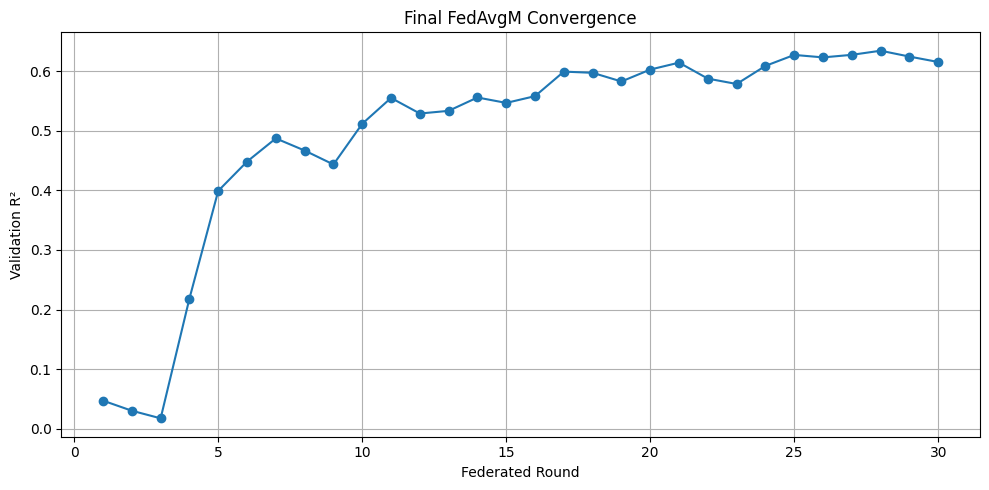


PHASE 23 COMPLETED

FINAL THREE FEDERATED TEST R² VALUES:
FedAvg   : 0.521961
FedAvgM  : 0.607467
FedPer   : 0.806335

Saved files:
/content/phase23_fedavgm_config_search.csv
/content/phase23_fedavgm_final_convergence.csv
/content/final_federated_three_way_comparison.csv
/content/phase23_fedavgm_final_predictions.npy
/content/final_fedavgm_model.pth

Total Phase 23 search time: 469.42 seconds


In [ ]:
# ============================================================
# PHASE 23 — FINAL FEDAVGM OPTIMIZATION
#
# FINAL PURPOSE:
#   Optimize FedAvgM once using validation data,
#   then evaluate the selected model ONCE on untouched test data.
#
# FINAL FEDERATED TABLE:
#   FedAvg
#   FedAvgM
#   FedPer
#
# IMPORTANT:
#   - Same 147 features
#   - Same chronological 70/10/20 split
#   - W1-W9 simulated clients
#   - Validation ONLY for choosing FedAvgM configuration
#   - Test ONLY for final evaluation
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import copy
import time
import os

print("=" * 80)
print("PHASE 23 — FINAL FEDAVGM OPTIMIZATION")
print("=" * 80)

# ============================================================
# 1. REQUIRED DATA
# ============================================================

if 'df_phase15' not in globals():
    raise RuntimeError(
        "df_phase15 not found. Please use the completed Phase 15 dataframe."
    )

if 'feature_cols_phase15' not in globals():
    raise RuntimeError(
        "feature_cols_phase15 not found."
    )

data = df_phase15.copy()

features = feature_cols_phase15

print(f"Dataset shape : {data.shape}")
print(f"Features      : {len(features)}")

# ============================================================
# 2. REPRODUCIBLE SEED
# ============================================================

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# 3. CHRONOLOGICAL 70 / 10 / 20 SPLIT
# ============================================================

data = data.sort_values(
    ['experiment_tag', 'experiment_csv_n', 'timestamp']
).reset_index(drop=True)

data['row_number'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
).cumcount()

data['run_size'] = data.groupby(
    ['experiment_tag', 'experiment_csv_n']
)['tool_wear'].transform('size')

data['train_cutoff'] = (
    data['run_size'] * 0.70
).astype(int)

data['val_cutoff'] = (
    data['run_size'] * 0.80
).astype(int)

train_mask = (
    data['row_number'] < data['train_cutoff']
)

val_mask = (
    (data['row_number'] >= data['train_cutoff']) &
    (data['row_number'] < data['val_cutoff'])
)

test_mask = (
    data['row_number'] >= data['val_cutoff']
)

train_df = data[train_mask].copy()
val_df = data[val_mask].copy()
test_df = data[test_mask].copy()

print("\nDATA SPLIT")
print("-" * 50)
print(f"Train      : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Test       : {len(test_df):,}")

# ============================================================
# 4. RAW DATA
# ============================================================

X_train_raw = train_df[features].values.astype(np.float32)
y_train_raw = train_df['tool_wear'].values.astype(np.float32)

X_val_raw = val_df[features].values.astype(np.float32)
y_val_raw = val_df['tool_wear'].values.astype(np.float32)

X_test_raw = test_df[features].values.astype(np.float32)
y_test_raw = test_df['tool_wear'].values.astype(np.float32)

# ============================================================
# 5. TRAIN-ONLY SCALING
# ============================================================

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(
    X_train_raw
).astype(np.float32)

X_val = x_scaler.transform(
    X_val_raw
).astype(np.float32)

X_test = x_scaler.transform(
    X_test_raw
).astype(np.float32)

y_train = y_scaler.fit_transform(
    y_train_raw.reshape(-1, 1)
).ravel().astype(np.float32)

# ============================================================
# 6. CLIENT DATA — TRAINING ONLY
# ============================================================

clients = sorted(
    train_df['experiment_tag'].unique()
)

client_data = {}

train_client_ids = train_df[
    'experiment_tag'
].values

print("\nCLIENTS")
print("-" * 50)

for client in clients:

    idx = train_client_ids == client

    client_data[client] = {
        'X': X_train[idx],
        'y': y_train[idx]
    }

    print(
        f"{client}: {idx.sum():,} samples"
    )

# ============================================================
# 7. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ============================================================
# 8. FEDAVGM MODEL
#
# Based directly on the stronger Phase 19 architecture.
# ============================================================

class FedAvgMModel(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, 256),
            nn.LayerNorm(256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

# ============================================================
# 9. LOCAL TRAINING
# ============================================================

def train_client(
    global_model,
    X,
    y,
    learning_rate
):

    model = FedAvgMModel(
        len(features)
    ).to(device)

    model.load_state_dict(
        global_model.state_dict()
    )

    model.train()

    dataset = TensorDataset(
        torch.tensor(
            X,
            dtype=torch.float32
        ),
        torch.tensor(
            y,
            dtype=torch.float32
        ).reshape(-1, 1)
    )

    loader = DataLoader(
        dataset,
        batch_size=1024,
        shuffle=True,
        pin_memory=torch.cuda.is_available()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-5
    )

    loss_fn = nn.SmoothL1Loss(
        beta=0.5
    )

    # Phase-19 style: controlled local training
    for epoch in range(1):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            prediction = model(xb)

            loss = loss_fn(
                prediction,
                yb
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=0.5
            )

            optimizer.step()

    return copy.deepcopy(
        model.state_dict()
    )

# ============================================================
# 10. VALIDATION
# ============================================================

def evaluate(
    model,
    X,
    y
):

    model.eval()

    predictions = []

    loader = DataLoader(
        TensorDataset(
            torch.tensor(
                X,
                dtype=torch.float32
            )
        ),
        batch_size=4096,
        shuffle=False
    )

    with torch.no_grad():

        for (xb,) in loader:

            xb = xb.to(device)

            pred = model(xb)

            predictions.append(
                pred.cpu().numpy().ravel()
            )

    predictions_scaled = np.concatenate(
        predictions
    )

    predictions_original = y_scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).ravel()

    mae = mean_absolute_error(
        y,
        predictions_original
    )

    rmse = np.sqrt(
        mean_squared_error(
            y,
            predictions_original
        )
    )

    r2 = r2_score(
        y,
        predictions_original
    )

    return mae, rmse, r2, predictions_original

# ============================================================
# 11. FEDAVGM TRAINING FUNCTION
# ============================================================

def run_fedavgm(
    learning_rate,
    server_momentum,
    rounds=30
):

    # Same starting point for every configuration
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    global_model = FedAvgMModel(
        len(features)
    ).to(device)

    momentum_state = None

    client_sizes = {
        client: len(
            client_data[client]['X']
        )
        for client in clients
    }

    total_samples = sum(
        client_sizes.values()
    )

    history = []

    best_val_r2 = -np.inf
    best_round = 0
    best_state = None

    for rnd in range(1, rounds + 1):

        # ----------------------------------------------------
        # LOCAL TRAINING
        # ----------------------------------------------------

        client_states = {}

        for client in clients:

            client_states[client] = train_client(
                global_model,
                client_data[client]['X'],
                client_data[client]['y'],
                learning_rate
            )

        # ----------------------------------------------------
        # WEIGHTED FEDAVG
        # ----------------------------------------------------

        current_state = (
            global_model.state_dict()
        )

        averaged_state = {}

        for key in current_state:

            averaged_state[key] = sum(
                client_states[client][key].float()
                *
                (
                    client_sizes[client]
                    / total_samples
                )
                for client in clients
            )

        # ----------------------------------------------------
        # SERVER MOMENTUM — FEDAVGM
        # ----------------------------------------------------

        if momentum_state is None:

            momentum_state = {}

            for key in current_state:

                momentum_state[key] = (
                    averaged_state[key]
                    - current_state[key].float()
                )

            # First round uses averaged model
            new_state = averaged_state

        else:

            new_state = {}

            for key in current_state:

                delta = (
                    averaged_state[key]
                    - current_state[key].float()
                )

                momentum_state[key] = (
                    server_momentum
                    * momentum_state[key]
                    + delta
                )

                new_state[key] = (
                    current_state[key].float()
                    + momentum_state[key]
                )

        global_model.load_state_dict(
            new_state
        )

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        val_mae, val_rmse, val_r2, _ = evaluate(
            global_model,
            X_val,
            y_val_raw
        )

        history.append({
            'Round': rnd,
            'MAE': val_mae,
            'RMSE': val_rmse,
            'R2': val_r2
        })

        if val_r2 > best_val_r2:

            best_val_r2 = val_r2
            best_round = rnd

            best_state = copy.deepcopy(
                global_model.state_dict()
            )

        print(
            f"LR={learning_rate:.6f} | "
            f"Momentum={server_momentum:.2f} | "
            f"Round {rnd:02d}/{rounds} | "
            f"Val R²={val_r2:.6f}"
        )

    return {
        'learning_rate': learning_rate,
        'server_momentum': server_momentum,
        'history': pd.DataFrame(history),
        'best_val_r2': best_val_r2,
        'best_round': best_round,
        'best_state': best_state
    }

# ============================================================
# 12. CONTROLLED FINAL SEARCH
#
# These are small variations around the successful Phase-19
# configuration instead of random hyperparameter hunting.
# ============================================================

configs = [

    # Phase-19 style configuration
    {
        'learning_rate': 0.00010,
        'server_momentum': 0.90
    },

    # Slightly smaller local learning rate
    {
        'learning_rate': 0.000075,
        'server_momentum': 0.90
    },

    # Slightly stronger server momentum
    {
        'learning_rate': 0.00010,
        'server_momentum': 0.95
    }
]

search_results = []

best_config_result = None

overall_best_val = -np.inf

print("\n" + "=" * 80)
print("FINAL FEDAVGM CONFIGURATION SEARCH")
print("=" * 80)

search_start = time.time()

for i, cfg in enumerate(
    configs,
    start=1
):

    print("\n" + "-" * 80)

    print(
        f"CONFIGURATION {i}/{len(configs)}"
    )

    print(
        f"Learning rate : {cfg['learning_rate']}"
    )

    print(
        f"Server momentum: {cfg['server_momentum']}"
    )

    result = run_fedavgm(
        learning_rate=cfg['learning_rate'],
        server_momentum=cfg['server_momentum'],
        rounds=30
    )

    search_results.append({
        'Config': i,
        'Learning Rate': cfg['learning_rate'],
        'Server Momentum': cfg['server_momentum'],
        'Best Round': result['best_round'],
        'Best Validation R2': result['best_val_r2']
    })

    if result['best_val_r2'] > overall_best_val:

        overall_best_val = result['best_val_r2']

        best_config_result = result

search_time = time.time() - search_start

# ============================================================
# 13. BEST FEDAVGM CONFIGURATION
# ============================================================

search_df = pd.DataFrame(
    search_results
)

print("\n" + "=" * 80)
print("FEDAVGM CONFIGURATION RESULTS")
print("=" * 80)

print(
    search_df.to_string(
        index=False
    )
)

print("\nSelected configuration:")

print(
    "Learning rate:",
    best_config_result['learning_rate']
)

print(
    "Server momentum:",
    best_config_result['server_momentum']
)

print(
    "Best validation R²:",
    best_config_result['best_val_r2']
)

print(
    "Best validation round:",
    best_config_result['best_round']
)

# ============================================================
# 14. FINAL FEDAVGM TEST
#
# IMPORTANT:
# This is the FIRST time the test set is used.
# ============================================================

final_model = FedAvgMModel(
    len(features)
).to(device)

final_model.load_state_dict(
    best_config_result['best_state']
)

test_mae, test_rmse, test_r2, test_predictions = evaluate(
    final_model,
    X_test,
    y_test_raw
)

print("\n" + "=" * 80)
print("FINAL FEDAVGM TEST RESULT")
print("=" * 80)

print(
    f"Best validation round : "
    f"{best_config_result['best_round']}"
)

print(
    f"Best validation R²    : "
    f"{best_config_result['best_val_r2']:.6f}"
)

print(
    f"TEST MAE              : "
    f"{test_mae:.6f}"
)

print(
    f"TEST RMSE             : "
    f"{test_rmse:.6f}"
)

print(
    f"TEST R²               : "
    f"{test_r2:.6f}"
)

# ============================================================
# 15. EXISTING FINAL FEDERATED RESULTS
#
# FedAvg:
#   Phase 22 actual result from your Colab screenshot.
#
# FedPer:
#   Previously completed final untouched-test result.
# ============================================================

fedavg_test_mae = 0.039216
fedavg_test_rmse = 0.049149
fedavg_test_r2 = 0.521961

fedper_test_mae = 0.021397
fedper_test_rmse = 0.031283
fedper_test_r2 = 0.806335

# ============================================================
# 16. FINAL THREE-WAY FEDERATED COMPARISON
# ============================================================

final_federated_comparison = pd.DataFrame([

    {
        'Method': 'FedAvg',
        'Source': 'Phase 22',
        'Test MAE': fedavg_test_mae,
        'Test RMSE': fedavg_test_rmse,
        'Test R2': fedavg_test_r2
    },

    {
        'Method': 'FedAvgM',
        'Source': 'Phase 23 FINAL',
        'Test MAE': test_mae,
        'Test RMSE': test_rmse,
        'Test R2': test_r2
    },

    {
        'Method': 'FedPer',
        'Source': 'Final FedPer result',
        'Test MAE': fedper_test_mae,
        'Test RMSE': fedper_test_rmse,
        'Test R2': fedper_test_r2
    }

])

print("\n" + "=" * 80)
print("FINAL FEDERATED LEARNING COMPARISON")
print("=" * 80)

print(
    final_federated_comparison.to_string(
        index=False
    )
)

# ============================================================
# 17. FEDAVGM CONVERGENCE PLOT
# ============================================================

history = best_config_result['history']

plt.figure(figsize=(10, 5))

plt.plot(
    history['Round'],
    history['R2'],
    marker='o'
)

plt.xlabel(
    "Federated Round"
)

plt.ylabel(
    "Validation R²"
)

plt.title(
    "Final FedAvgM Convergence"
)

plt.grid(True)

plt.tight_layout()

plt.show()

# ============================================================
# 18. SAVE EVERYTHING
# ============================================================

search_df.to_csv(
    "/content/phase23_fedavgm_config_search.csv",
    index=False
)

history.to_csv(
    "/content/phase23_fedavgm_final_convergence.csv",
    index=False
)

final_federated_comparison.to_csv(
    "/content/final_federated_three_way_comparison.csv",
    index=False
)

np.save(
    "/content/phase23_fedavgm_final_predictions.npy",
    test_predictions
)

torch.save(
    final_model.state_dict(),
    "/content/final_fedavgm_model.pth"
)

# ============================================================
# 19. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("PHASE 23 COMPLETED")
print("=" * 80)

print("\nFINAL THREE FEDERATED TEST R² VALUES:")

print(
    f"FedAvg   : {fedavg_test_r2:.6f}"
)

print(
    f"FedAvgM  : {test_r2:.6f}"
)

print(
    f"FedPer   : {fedper_test_r2:.6f}"
)

print("\nSaved files:")

print(
    "/content/phase23_fedavgm_config_search.csv"
)

print(
    "/content/phase23_fedavgm_final_convergence.csv"
)

print(
    "/content/final_federated_three_way_comparison.csv"
)

print(
    "/content/phase23_fedavgm_final_predictions.npy"
)

print(
    "/content/final_fedavgm_model.pth"
)

print(
    f"\nTotal Phase 23 search time: "
    f"{search_time:.2f} seconds"
)

print("=" * 80)

In [ ]:

# ============================================================
# FINISHING STEP 1: XGBOOST FEATURE ABLATION AUDIT
# Run AFTER Phase 23. Does not overwrite previous results.
# ============================================================

import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 1. VERIFY PHASE 13 VARIABLES
# ------------------------------------------------------------

required_vars = [
    "feature_cols_final",
    "X_train_final_val",
    "X_validation_final",
    "X_test_final_val",
    "y_train_final_val",
    "y_validation_final",
    "y_test_final_val",
    "final_validation_model"
]

missing = [v for v in required_vars if v not in globals()]

if missing:
    raise RuntimeError(
        f"Missing Phase 13 variables: {missing}\n"
        "Check that Phase 13 was executed in the current runtime."
    )

print("Phase 13 variables found.")
print("Original feature count:", len(feature_cols_final))


# ------------------------------------------------------------
# 2. DEFINE FEATURE GROUPS
# ------------------------------------------------------------

# These features use the eventual length of the complete run,
# or depend on run_progress calculated using that length.
run_length_dependent = [
    "run_total_samples",
    "run_progress",
    "run_progress_sq",
    "run_progress_cube",
    "progress_speed",
    "progress_feed",
    "progress_depth",
    "progress_power",
    "progress_force"
]

# Experiment A: remove only run_total_samples.
features_without_total = [
    c for c in feature_cols_final
    if c != "run_total_samples"
]

# Experiment B: remove all features dependent on run length.
features_without_progress = [
    c for c in feature_cols_final
    if c not in run_length_dependent
]

print("\nAblation experiments:")
print("Original model:", len(feature_cols_final), "features")
print("Without run_total_samples:", len(features_without_total))
print("Without run-length-dependent features:",
      len(features_without_progress))


# ------------------------------------------------------------
# 3. METRIC FUNCTION
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


# ------------------------------------------------------------
# 4. EVALUATE EXISTING PHASE 13 MODEL
# ------------------------------------------------------------

results = []

for split_name, X, y in [
    ("Validation", X_validation_final, y_validation_final),
    ("Test", X_test_final_val, y_test_final_val)
]:
    predictions = final_validation_model.predict(X)

    metrics = calculate_metrics(y, predictions)

    results.append({
        "Experiment": "Original Phase 13",
        "Split": split_name,
        "Features": len(feature_cols_final),
        **metrics
    })


# ------------------------------------------------------------
# 5. TRAIN ABLATION MODELS
# Same configuration and same existing data split.
# ------------------------------------------------------------

experiments = [
    ("Without run_total_samples", features_without_total),
    ("Without run-length-dependent features",
     features_without_progress)
]

for experiment_name, selected_features in experiments:

    print(f"\nTraining: {experiment_name}")

    model = XGBRegressor(
        n_estimators=1000,
        max_depth=8,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.9,
        reg_alpha=0.01,
        reg_lambda=1.0,
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    )

    model.fit(
        X_train_final_val[selected_features],
        y_train_final_val,
        eval_set=[
            (
                X_validation_final[selected_features],
                y_validation_final
            )
        ],
        verbose=False
    )

    # Validation and test results are reported separately.
    for split_name, X, y in [
        ("Validation", X_validation_final, y_validation_final),
        ("Test", X_test_final_val, y_test_final_val)
    ]:
        predictions = model.predict(X[selected_features])
        metrics = calculate_metrics(y, predictions)

        results.append({
            "Experiment": experiment_name,
            "Split": split_name,
            "Features": len(selected_features),
            **metrics
        })

        print(
            f"{split_name}: "
            f"MAE={metrics['MAE']:.6f} | "
            f"RMSE={metrics['RMSE']:.6f} | "
            f"R2={metrics['R2']:.6f}"
        )


# ------------------------------------------------------------
# 6. DISPLAY AND SAVE RESULTS
# ------------------------------------------------------------

ablation_results = pd.DataFrame(results)

print("\n" + "=" * 85)
print("FINISHING STEP 1: ABLATION RESULTS")
print("=" * 85)

print(
    ablation_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

output_path = "/content/step1_ablation_results.csv"

ablation_results.to_csv(output_path, index=False)

print("\nResults saved to:", output_path)
print("Previous phase results and models were not overwritten.")


Phase 13 variables found.
Original feature count: 147

Ablation experiments:
Original model: 147 features
Without run_total_samples: 146
Without run-length-dependent features: 138

Training: Without run_total_samples
Validation: MAE=0.019466 | RMSE=0.027706 | R2=0.850590
Test: MAE=0.022290 | RMSE=0.030140 | R2=0.820229

Training: Without run-length-dependent features
Validation: MAE=0.019391 | RMSE=0.027422 | R2=0.853636
Test: MAE=0.021250 | RMSE=0.029400 | R2=0.828943

FINISHING STEP 1: ABLATION RESULTS
                           Experiment      Split  Features      MAE     RMSE       R2
                    Original Phase 13 Validation       147 0.005066 0.008155 0.987057
                    Original Phase 13       Test       147 0.006348 0.010132 0.979683
            Without run_total_samples Validation       146 0.019466 0.027706 0.850590
            Without run_total_samples       Test       146 0.022290 0.030140 0.820229
Without run-length-dependent features Validation       138 0

In [ ]:
# FINISHING STEP 2 — Identify data and run-ID variables
import pandas as pd

print("DATAFRAMES IN CURRENT RUNTIME")
print("=" * 60)

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = list(obj.columns)
        run_cols = [
            c for c in cols
            if any(k in str(c).lower()
                   for k in ["run", "experiment", "group", "trial"])
        ]
        if "tool_wear" in cols or run_cols:
            print(f"\nDataFrame: {name}")
            print(f"Shape: {obj.shape}")
            print(f"Run/experiment candidates: {run_cols}")
            print(f"Has tool_wear target: {'tool_wear' in cols}")
            print(f"Columns: {cols[:35]}")

print("\nPOSSIBLE PHASE 13 VARIABLES")
print("=" * 60)

for name in [
    "feature_cols_final",
    "X_train_final_val",
    "X_validation_final",
    "X_test_final_val",
    "y_train_final_val",
    "y_validation_final",
    "y_test_final_val",
    "final_validation_model"
]:
    print(f"{name}: {'FOUND' if name in globals() else 'not found'}")

DATAFRAMES IN CURRENT RUNTIME

DataFrame: ___
Shape: (5, 25)
Run/experiment candidates: ['experiment_tag', 'experiment_csv_n']
Has tool_wear target: True
Columns: ['Unnamed: 0', 'axial_force', 'bending_moment_x', 'bending_moment_y', 'torsion', 'vibration1', 'vibration2', 'spindle_power', 'spindle_current', 'timestamp', 'wear_blade_1', 'wear_blade_2', 'wear_blade_3', 'wear_blade_4', 'experiment_tag', 'experiment_csv_n', 'feed_per_tooth', 'spindle_speed', 'axial_cutting_depth', 'tool_wear', 'dataset_tag', 'vibration_x', 'vibration_y', 'force_z', 'tool_wear_increment']

DataFrame: df
Shape: (234902, 25)
Run/experiment candidates: ['experiment_tag', 'experiment_csv_n']
Has tool_wear target: True
Columns: ['Unnamed: 0', 'axial_force', 'bending_moment_x', 'bending_moment_y', 'torsion', 'vibration1', 'vibration2', 'spindle_power', 'spindle_current', 'timestamp', 'wear_blade_1', 'wear_blade_2', 'wear_blade_3', 'wear_blade_4', 'experiment_tag', 'experiment_csv_n', 'feed_per_tooth', 'spindle_spe

In [ ]:
# ============================================================
# FINISHING STEP 2: GENERALIZATION TO UNSEEN CNC RUNS
# Uses complete runs as groups to prevent run overlap.
# Does not overwrite previous models or results.
# ============================================================

import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing engineered dataset and target.
# train_final, validation_final, and test_final together
# represent the existing chronological split, so reconstruct
# the full dataset from the existing feature/target arrays.
#
# For a valid unseen-run experiment, use the original df_temporal
# and rebuild features after assigning entire runs to splits.

source_df = df_temporal.copy()

GROUP_COLS = ["experiment_tag", "experiment_csv_n"]
TARGET = "tool_wear"

missing_cols = [c for c in GROUP_COLS + [TARGET] if c not in source_df.columns]
if missing_cols:
    raise ValueError(f"Required columns missing: {missing_cols}")

# Each experiment/run gets a unique group ID.
source_df["_run_group"] = (
    source_df[GROUP_COLS].astype(str).agg("__".join, axis=1)
)

print("Total rows:", len(source_df))
print("Unique runs:", source_df["_run_group"].nunique())

# Hold out approximately 20% of entire runs for testing.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(
    splitter.split(source_df, groups=source_df["_run_group"])
)

train_rows = source_df.iloc[train_idx].copy()
test_rows = source_df.iloc[test_idx].copy()

# Confirm that no run appears in both sets.
train_groups = set(train_rows["_run_group"])
test_groups = set(test_rows["_run_group"])
assert train_groups.isdisjoint(test_groups), "Run overlap detected!"

# Use only original sensor/process measurements.
# Do not use wear blade measurements, target increments,
# run length, or features that depend on future run information.
base_features = [
    "axial_force", "bending_moment_x", "bending_moment_y",
    "torsion", "vibration1", "vibration2", "spindle_power",
    "spindle_current", "feed_per_tooth", "spindle_speed",
    "axial_cutting_depth", "vibration_x", "vibration_y", "force_z"
]
base_features = [c for c in base_features if c in source_df.columns]

# Add temporal features only if already present in df_temporal.
# Lag/rolling features must be computed within each run.
temporal_features = [
    c for c in source_df.columns
    if any(tag in c for tag in ["_lag_", "_diff_", "_rollmean_", "_rollstd_"])
    and c not in base_features
    and c not in ["tool_wear_increment"]
]
features = base_features + temporal_features

# Exclude any feature derived from the target or future run length.
features = [
    c for c in features
    if c not in GROUP_COLS
    and not any(tag in c for tag in [
        "wear_blade_", "run_total_samples", "run_size",
        "run_progress", "elapsed_seconds", "tool_wear_increment"
    ])
]

X_train = train_rows[features].replace([np.inf, -np.inf], np.nan)
X_test = test_rows[features].replace([np.inf, -np.inf], np.nan)
y_train = train_rows[TARGET]
y_test = test_rows[TARGET]

# Fill missing feature values using training-set medians only.
medians = X_train.median()
X_train = X_train.fillna(medians).fillna(0)
X_test = X_test.fillna(medians).fillna(0)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training runs:", len(train_groups))
print("Unseen test runs:", len(test_groups))
print("Features used:", len(features))

model_unseen_runs = XGBRegressor(
    n_estimators=700,
    max_depth=7,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

model_unseen_runs.fit(X_train, y_train, verbose=False)
predictions = model_unseen_runs.predict(X_test)

unseen_run_results = pd.DataFrame([{
    "Experiment": "Unseen-run XGBoost",
    "Train_Runs": len(train_groups),
    "Test_Runs": len(test_groups),
    "Features": len(features),
    "MAE": mean_absolute_error(y_test, predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
    "R2": r2_score(y_test, predictions)
}])

print("\n" + "=" * 65)
print("UNSEEN-RUN GENERALIZATION RESULTS")
print("=" * 65)
print(unseen_run_results.to_string(index=False))
print("\nTrain/test run overlap:", len(train_groups & test_groups))
unseen_run_results.to_csv("step2_unseen_run_results.csv", index=False)
print("Saved: step2_unseen_run_results.csv")

Total rows: 234902
Unique runs: 152

Training rows: 186873
Testing rows: 48029
Training runs: 121
Unseen test runs: 31
Features used: 135

UNSEEN-RUN GENERALIZATION RESULTS
        Experiment  Train_Runs  Test_Runs  Features      MAE     RMSE       R2
Unseen-run XGBoost         121         31       135 0.023473 0.033834 0.798498

Train/test run overlap: 0
Saved: step2_unseen_run_results.csv


In [ ]:
print("Federated-learning result variables:")
for name in sorted(globals()):
    if any(k in name.lower() for k in [
        "fedavg", "fedper", "scaffold", "federated",
        "fl_results", "round_results"
    ]):
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name}: shape={obj.shape}")
        elif isinstance(obj, (int, float, str)):
            print(f"{name}: {obj}")

Federated-learning result variables:
fedavg_test_mae: 0.039216
fedavg_test_r2: 0.521961
fedavg_test_rmse: 0.049149
fedper_test_mae: 0.021397
fedper_test_r2: 0.806335
fedper_test_rmse: 0.031283
final_federated_comparison: shape=(3, 5)
fl_results: shape=(5, 4)
fl_results_df: shape=(5, 4)


In [ ]:
# STEP 3: CONSOLIDATE EXISTING FEDERATED RESULTS
# No training or model changes.

import pandas as pd

final_fl_table = pd.DataFrame([
    {
        "Model": "FedAvg",
        "Test_MAE": fedavg_test_mae,
        "Test_RMSE": fedavg_test_rmse,
        "Test_R2": fedavg_test_r2
    },
    {
        "Model": "FedPer",
        "Test_MAE": fedper_test_mae,
        "Test_RMSE": fedper_test_rmse,
        "Test_R2": fedper_test_r2
    }
])

final_fl_table = final_fl_table.sort_values(
    "Test_R2", ascending=False
).reset_index(drop=True)

print("FINAL FEDERATED LEARNING COMPARISON")
display(final_fl_table.round(6))

final_fl_table.to_csv(
    "final_federated_learning_comparison.csv",
    index=False
)

print("Saved: final_federated_learning_comparison.csv")

FINAL FEDERATED LEARNING COMPARISON


,Model,Test_MAE,Test_RMSE,Test_R2
0,FedPer,0.021397,0.031283,0.806335
1,FedAvg,0.039216,0.049149,0.521961


Saved: final_federated_learning_comparison.csv


In [ ]:
# STEP 2: Check temporal and progression feature names

cols = list(df_temporal.columns)

print("TEMPORAL FEATURE EXAMPLES:")
print([c for c in cols if any(
    tag in c.lower()
    for tag in ["_lag_", "_diff_", "_rollmean_", "_rollstd_"]
)][:30])

print("\nPROGRESSION / TIME FEATURES:")
print([c for c in cols if any(
    tag in c.lower()
    for tag in ["progress", "elapsed", "run_total", "run_sample", "run_size"]
)])

print("\nTEMPORAL FEATURE GENERATION CODE:")
print("Find the earlier notebook cell that creates lag and rolling features.")

TEMPORAL FEATURE EXAMPLES:
['axial_force_lag_1', 'axial_force_lag_2', 'axial_force_lag_5', 'bending_moment_x_lag_1', 'bending_moment_x_lag_2', 'bending_moment_x_lag_5', 'bending_moment_y_lag_1', 'bending_moment_y_lag_2', 'bending_moment_y_lag_5', 'torsion_lag_1', 'torsion_lag_2', 'torsion_lag_5', 'vibration1_lag_1', 'vibration1_lag_2', 'vibration1_lag_5', 'vibration2_lag_1', 'vibration2_lag_2', 'vibration2_lag_5', 'spindle_power_lag_1', 'spindle_power_lag_2', 'spindle_power_lag_5', 'spindle_current_lag_1', 'spindle_current_lag_2', 'spindle_current_lag_5', 'vibration_x_lag_1', 'vibration_x_lag_2', 'vibration_x_lag_5', 'vibration_y_lag_1', 'vibration_y_lag_2', 'vibration_y_lag_5']

PROGRESSION / TIME FEATURES:
['run_size']

TEMPORAL FEATURE GENERATION CODE:
Find the earlier notebook cell that creates lag and rolling features.


In [ ]:
# ============================================================
# STEP 2 — STRICTER UNSEEN-RUN GENERALIZATION TEST
# Uses raw df, causal forward filling, and run-disjoint split.
# Does not overwrite previous results or models.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# 1. Start from the original dataframe, not the interpolated df_clean
audit_df = df.copy()

GROUP_COLS = ["experiment_tag", "experiment_csv_n"]
TARGET = "tool_wear"
BASE_FEATURES = [
    "axial_force", "bending_moment_x", "bending_moment_y",
    "torsion", "vibration1", "vibration2", "spindle_power",
    "spindle_current", "feed_per_tooth", "spindle_speed",
    "axial_cutting_depth", "vibration_x", "vibration_y", "force_z"
]
SENSOR_COLS = [
    "axial_force", "bending_moment_x", "bending_moment_y",
    "torsion", "vibration1", "vibration2", "spindle_power",
    "spindle_current", "vibration_x", "vibration_y", "force_z"
]

required = GROUP_COLS + [TARGET, "timestamp"] + BASE_FEATURES
missing = [c for c in required if c not in audit_df.columns]
if missing:
    raise ValueError(
        f"Original df is missing {missing}. Stop here; don't substitute df_clean."
    )

# 2. Sort samples in their actual run order
audit_df["timestamp"] = pd.to_datetime(
    audit_df["timestamp"], errors="coerce"
)
audit_df = audit_df.sort_values(
    GROUP_COLS + ["timestamp"]
).reset_index(drop=True)

audit_df["_audit_run"] = (
    audit_df[GROUP_COLS].astype(str).agg("__".join, axis=1)
)

# 3. Split whole runs before model fitting
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
train_idx, test_idx = next(
    splitter.split(audit_df, groups=audit_df["_audit_run"])
)

train_groups = set(audit_df.iloc[train_idx]["_audit_run"])
test_groups = set(audit_df.iloc[test_idx]["_audit_run"])
assert train_groups.isdisjoint(test_groups)

# 4. Causal sensor filling: use only earlier values within each run
# Leading missing values remain missing until training medians are learned.
for col in SENSOR_COLS:
    audit_df[col] = (
        audit_df.groupby(GROUP_COLS, sort=False)[col].ffill()
    )

# 5. Build lags, differences, and trailing rolling features per run
# No centered windows and no backward filling.
temporal_df = audit_df.copy()

for col in SENSOR_COLS:
    grouped = temporal_df.groupby(GROUP_COLS, sort=False)[col]

    for lag in [1, 2, 5]:
        temporal_df[f"{col}_lag_{lag}"] = grouped.shift(lag)

    for lag in [1, 5]:
        temporal_df[f"{col}_diff_{lag}"] = (
            temporal_df[col] - grouped.shift(lag)
        )

    for window in [15, 30, 60]:
        temporal_df[f"{col}_rollmean_{window}"] = (
            grouped.transform(
                lambda s, w=window: s.rolling(
                    window=w, min_periods=1
                ).mean()
            )
        )
        temporal_df[f"{col}_rollstd_{window}"] = (
            grouped.transform(
                lambda s, w=window: s.rolling(
                    window=w, min_periods=1
                ).std()
            )
        )

temporal_features = [
    c for c in temporal_df.columns
    if any(tag in c for tag in [
        "_lag_", "_diff_", "_rollmean_", "_rollstd_"
    ])
]
FEATURES = BASE_FEATURES + temporal_features

# 6. Select train/test rows; learn imputations only from training data
train = temporal_df.iloc[train_idx].copy()
test = temporal_df.iloc[test_idx].copy()

X_train = train[FEATURES].replace([np.inf, -np.inf], np.nan)
X_test = test[FEATURES].replace([np.inf, -np.inf], np.nan)
y_train = train[TARGET]
y_test = test[TARGET]

valid_train = y_train.notna()
valid_test = y_test.notna()

X_train, y_train = X_train.loc[valid_train], y_train.loc[valid_train]
X_test, y_test = X_test.loc[valid_test], y_test.loc[valid_test]

medians = X_train.median().fillna(0)
X_train = X_train.fillna(medians).fillna(0)
X_test = X_test.fillna(medians).fillna(0)

# 7. Train a fresh benchmark model
audit_model = XGBRegressor(
    n_estimators=700,
    max_depth=7,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)
audit_model.fit(X_train, y_train, verbose=False)
audit_pred = audit_model.predict(X_test)

# 8. Report and save this stricter audit separately
strict_unseen_results = pd.DataFrame([{
    "Experiment": "Causal preprocessing, unseen runs",
    "Training_runs": len(train_groups),
    "Test_runs": len(test_groups),
    "Features": len(FEATURES),
    "Test_rows": len(y_test),
    "MAE": mean_absolute_error(y_test, audit_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, audit_pred)),
    "R2": r2_score(y_test, audit_pred),
    "Run_overlap": len(train_groups & test_groups)
}])

print("STRICTER UNSEEN-RUN TEST")
display(strict_unseen_results.round(6))

strict_unseen_results.to_csv(
    "step2_strict_causal_unseen_run_results.csv", index=False
)
print("Saved: step2_strict_causal_unseen_run_results.csv")

/tmp/ipykernel_3017/3511534685.py:92: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  temporal_df[f"{col}_rollstd_{window}"] = (
/tmp/ipykernel_3017/3511534685.py:85: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  temporal_df[f"{col}_rollmean_{window}"] = (
/tmp/ipykernel_3017/3511534685.py:92: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented f

STRICTER UNSEEN-RUN TEST


,Experiment,Training_runs,Test_runs,Features,Test_rows,MAE,RMSE,R2,Run_overlap
0,"Causal preprocessing, unseen runs",121,31,135,48029,0.023346,0.033842,0.798397,0


Saved: step2_strict_causal_unseen_run_results.csv


In [ ]:

# TEST 2 — FINAL DATA ORDER & PREPROCESSING AUDIT
# Diagnostic only: does not modify df or retrain models.

import pandas as pd
import numpy as np

raw = df.copy()

group_cols = ["experiment_tag", "experiment_csv_n"]
sensor_cols = [
    "axial_force", "bending_moment_x", "bending_moment_y",
    "torsion", "vibration1", "vibration2", "spindle_power",
    "spindle_current", "vibration_x", "vibration_y", "force_z"
]

print("=" * 60)
print("TEST 2: FINAL DATA AUDIT")
print("=" * 60)

# 1. Required columns
required = group_cols + ["tool_wear"]
missing_cols = [c for c in required if c not in raw.columns]
print("\n1. Missing required columns:", missing_cols)

if missing_cols:
    print("STOP: required columns are missing.")
else:
    print("2. Total rows:", len(raw))
    print("3. Unique experimental runs:",
          raw[group_cols].astype(str).agg("__".join, axis=1).nunique())

    # 2. Check sensor availability
    available_sensors = [c for c in sensor_cols if c in raw.columns]
    missing_sensors = [c for c in sensor_cols if c not in raw.columns]

    print("\n4. Available sensor columns:", len(available_sensors))
    print("5. Missing sensor columns:", missing_sensors)

    if available_sensors:
        print("\n6. Missing values in raw sensors:")
        print(raw[available_sensors].isna().sum().to_string())

    # 3. Find timestamp/sample-order column candidates
    candidates = [
        c for c in raw.columns
        if any(k in c.lower() for k in [
            "timestamp", "time", "sample_index", "sample_id", "index"
        ])
    ]
    print("\n7. Possible ordering columns:", candidates)

    # 4. If a timestamp exists, check duplicates and monotonicity per run
    if "timestamp" in raw.columns:
        ts = pd.to_datetime(raw["timestamp"], errors="coerce")
        print("8. Invalid/missing timestamps:", int(ts.isna().sum()))
        print("9. Duplicate timestamps within runs:",
              int(raw.assign(_ts=ts).duplicated(
                  group_cols + ["_ts"]
              ).sum()))

        check = raw[group_cols].copy()
        check["_ts"] = ts
        monotonic = check.groupby(group_cols, dropna=False)["_ts"].apply(
            lambda s: s.dropna().is_monotonic_increasing
        )
        print("10. Runs with ordered timestamps:",
              int(monotonic.sum()), "/", len(monotonic))
    else:
        print("\n8. No column named 'timestamp' found.")
        print("Sample ordering must be verified from the source schema.")

    # 5. Check target validity
    if "tool_wear" in raw.columns:
        print("\n11. Missing target values:",
              int(raw["tool_wear"].isna().sum()))
        print("12. Target range:",
              raw["tool_wear"].min(), "to", raw["tool_wear"].max())

print("\nAudit complete. No models or existing results were changed.")


TEST 2: FINAL DATA AUDIT

1. Missing required columns: []
2. Total rows: 234902
3. Unique experimental runs: 152

4. Available sensor columns: 11
5. Missing sensor columns: []

6. Missing values in raw sensors:
axial_force           0
bending_moment_x    149
bending_moment_y    149
torsion             149
vibration1            0
vibration2            0
spindle_power         0
spindle_current       0
vibration_x           0
vibration_y           0
force_z               0

7. Possible ordering columns: ['timestamp']
8. Invalid/missing timestamps: 0
9. Duplicate timestamps within runs: 219261
10. Runs with ordered timestamps: 152 / 152

11. Missing target values: 0
12. Target range: 0.04903544872 to 0.3127480573

Audit complete. No models or existing results were changed.


In [ ]:

# Check timestamp uniqueness and original sample ordering
audit = df.copy()
group_cols = ["experiment_tag", "experiment_csv_n"]

print("Rows:", len(audit))
print("Unique timestamps:", audit["timestamp"].nunique())
print("Duplicate timestamp rows:", audit["timestamp"].duplicated().sum())

# Inspect the first run with repeated timestamps
run_id = audit.groupby(group_cols, dropna=False).size().index[0]
mask = (
    (audit[group_cols[0]] == run_id[0]) &
    (audit[group_cols[1]] == run_id[1])
)

cols = group_cols + ["timestamp", "tool_wear"]
print("\nFirst run, first 15 original rows:")
print(audit.loc[mask, cols].head(15).to_string(index=False))

# Check whether timestamps repeat in consecutive blocks
g = audit.loc[mask].copy()
g["timestamp"] = pd.to_datetime(g["timestamp"], errors="coerce")
print("\nFirst run timestamp changes:")
print(g["timestamp"].diff().value_counts().head(10))


Rows: 234902
Unique timestamps: 203581
Duplicate timestamp rows: 31321

First run, first 15 original rows:
experiment_tag  experiment_csv_n  timestamp  tool_wear
            W1                 1     0.0033   0.117595
            W1                 1     0.0693   0.117601
            W1                 1     0.1353   0.117608
            W1                 1     0.2013   0.117614
            W1                 1     0.2673   0.117620
            W1                 1     0.3333   0.117627
            W1                 1     0.3993   0.117633
            W1                 1     0.4653   0.117639
            W1                 1     0.5313   0.117646
            W1                 1     0.5973   0.117652
            W1                 1     0.6633   0.117659
            W1                 1     0.7293   0.117665
            W1                 1     0.7953   0.117671
            W1                 1     0.8613   0.117678
            W1                 1     0.9273   0.117684

First run ti

In [ ]:

group_cols = ["experiment_tag", "experiment_csv_n"]

check = df.copy()
check["timestamp"] = pd.to_numeric(check["timestamp"], errors="coerce")

summary = check.groupby(group_cols, dropna=False).agg(
    rows=("timestamp", "size"),
    unique_timestamps=("timestamp", "nunique"),
    min_time=("timestamp", "min"),
    max_time=("timestamp", "max")
)

summary["repeated_timestamp_rows"] = (
    summary["rows"] - summary["unique_timestamps"]
)

print("Runs:", len(summary))
print("Runs with repeated timestamps:",
      (summary["repeated_timestamp_rows"] > 0).sum())
print("\nRuns with the most repeated timestamps:")
print(summary.sort_values(
    "repeated_timestamp_rows", ascending=False
).head(10).to_string())


Runs: 152
Runs with repeated timestamps: 0

Runs with the most repeated timestamps:
                                 rows  unique_timestamps   min_time   max_time  repeated_timestamp_rows
experiment_tag experiment_csv_n                                                                        
W1             1                 1576               1576     0.0033   103.9533                        0
               2                 1757               1757   103.9665   219.8625                        0
               3                 1773               1773   219.8988   336.8508                        0
               4                 1800               1800   336.8574   455.5914                        0
               5                 1679               1679   455.6310   566.3790                        0
               6                 1623               1623   566.4054   673.4574                        0
               7                 1737               1737   673.4904   788.0664      

In [ ]:
#Test 3VT

In [70]:

# TEST 3 PRE-CHECK: inspect data and saved split variables

print("=" * 55)
print("TEST 3 PRE-EXECUTION CHECK")
print("=" * 55)

print("Raw df exists:", "df" in globals())

if "df" in globals():
    print("Raw df shape:", df.shape)

    required = [
        "experiment_tag", "experiment_csv_n",
        "timestamp", "tool_wear", "axial_force",
        "bending_moment_x", "bending_moment_y", "torsion",
        "vibration1", "vibration2", "spindle_power",
        "spindle_current", "feed_per_tooth",
        "spindle_speed", "axial_cutting_depth",
        "vibration_x", "vibration_y", "force_z"
    ]

    print("Missing required columns:",
          [c for c in required if c not in df.columns])

    print("Unique run groups:",
          df.groupby(
              ["experiment_tag", "experiment_csv_n"],
              dropna=False
          ).ngroups)

print("\nPotential saved split variables:")
for name in [
    "train_idx", "test_idx",
    "train_runs", "test_runs",
    "train_groups", "test_groups",
    "X_train_test2", "X_test_test2",
    "test2_results"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: available, type={type(obj).__name__}, "
              f"length={len(obj) if hasattr(obj, '__len__') else 'N/A'}")
    else:
        print(f"{name}: not found")

print("=" * 55)


TEST 3 PRE-EXECUTION CHECK
Raw df exists: True
Raw df shape: (234902, 25)
Missing required columns: []
Unique run groups: 152

Potential saved split variables:
train_idx: available, type=ndarray, length=186419
test_idx: available, type=ndarray, length=48483
train_runs: available, type=set, length=121
test_runs: available, type=set, length=31
train_groups: not found
test_groups: not found
X_train_test2: not found
X_test_test2: not found
test2_results: not found


In [75]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---- ----------------------------------- 5.8/48.9 MB 31.8 MB/s eta 0:00:02
   ---------- ----------------------------- 13.4/48.9 MB 34.4 MB/s eta 0:00:02
   ---------------- ----------------------- 19.7/48.9 MB 32.9 MB/s eta 0:00:01
   ----------------- ---------------------- 22.0/48.9 MB 27.2 MB/s eta 0:00:01
   -------------------- ------------------- 25.2/48.9 MB 24.4 MB/s eta 0:00:01
   ---------------------- ----------------- 27.5/48.9 MB 22.5 MB/s eta 0:00:01
   ------------------------ --------------- 30.4/48.9 MB 20.9 MB/s eta 0:00:01
   -------------------------- ------------- 33.0/48.9 MB 19.8 MB/s eta 0:00:01
   ---------------------------- ----------- 35.4/48.9 MB 19.0 MB/s eta 0:00:01
   ------------------------------- -------- 38.0/48.9 MB 18.3 MB/s eta 0:00:01
   --------------------------------- ------ 40.6/48.9 MB 17.8 MB/s eta 0:00:01
   ----------------------------------- ---- 43.3/48.9 MB 17.4 


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [76]:

# ============================================================
# TEST 3: UNSEEN-RUN GENERALIZATION WITHOUT RUN-LENGTH FEATURES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

print("=" * 65)
print("TEST 3: CAUSAL FEATURES WITHOUT RUN-LENGTH INFORMATION")
print("=" * 65)

# 1. Validate the saved Test 2 split
assert "df" in globals(), "Raw df is missing."
assert "train_idx" in globals() and "test_idx" in globals(), (
    "Saved Test 2 indices are missing."
)
assert len(train_runs) == 121 and len(test_runs) == 31, (
    "Unexpected saved run split."
)

raw = df.copy().reset_index(drop=True)

group_cols = ["experiment_tag", "experiment_csv_n"]
target = "tool_wear"

# Ensure saved row indices refer to this raw dataframe.
assert max(np.max(train_idx), np.max(test_idx)) < len(raw), (
    "Saved indices do not fit the raw dataframe."
)
assert set(train_idx).isdisjoint(set(test_idx)), (
    "Training and test row indices overlap."
)

# Confirm the saved run split matches the raw dataframe row groups.
row_run_ids = (
    raw[group_cols].astype(str).agg("__".join, axis=1)
)
saved_train_ids = set(row_run_ids.iloc[train_idx])
saved_test_ids = set(row_run_ids.iloc[test_idx])

assert saved_train_ids.isdisjoint(saved_test_ids), (
    "The saved row split contains overlapping runs."
)

# 2. Sort chronologically within each run before engineering features.
# Use a separate working dataframe; do not modify raw df.
work = raw.copy()
work["_original_row"] = np.arange(len(work))
work = work.sort_values(
    group_cols + ["timestamp"], kind="mergesort"
).reset_index(drop=True)

# 3. Select ordinary raw sensor/process predictors.
# Explicitly exclude target, wear-derived columns, metadata,
# and run-length/progression information.
base_candidates = [
    "axial_force",
    "bending_moment_x",
    "bending_moment_y",
    "torsion",
    "vibration1",
    "vibration2",
    "spindle_power",
    "spindle_current",
    "feed_per_tooth",
    "spindle_speed",
    "axial_cutting_depth",
    "vibration_x",
    "vibration_y",
    "force_z",
]

base_features = [
    c for c in base_candidates if c in work.columns
]

if not base_features:
    raise ValueError("No eligible base sensor/process features found.")

# Numeric conversion, then causal forward-fill within each run.
for col in base_features:
    work[col] = pd.to_numeric(work[col], errors="coerce")

work[base_features] = (
    work.groupby(group_cols, sort=False)[base_features]
        .ffill()
)

# 4. Build causal temporal features within each run.
# No backward fill, centered rolling windows, run length,
# run progress, or future-derived features.
feature_data = work[base_features].copy()

for lag in [1, 2, 5]:
    lagged = (
        work.groupby(group_cols, sort=False)[base_features]
            .shift(lag)
    )
    lagged.columns = [f"{c}_lag_{lag}" for c in base_features]
    feature_data = pd.concat([feature_data, lagged], axis=1)

for period in [1, 5]:
    diff = (
        work.groupby(group_cols, sort=False)[base_features]
            .diff(period)
    )
    diff.columns = [f"{c}_diff_{period}" for c in base_features]
    feature_data = pd.concat([feature_data, diff], axis=1)

for window in [15, 30, 60]:
    rolling_mean = (
        work.groupby(group_cols, sort=False)[base_features]
            .rolling(window=window, min_periods=1)
            .mean()
            .reset_index(level=group_cols, drop=True)
    )
    rolling_mean.columns = [
        f"{c}_rollmean_{window}" for c in base_features
    ]
    feature_data = pd.concat([feature_data, rolling_mean], axis=1)

    rolling_std = (
        work.groupby(group_cols, sort=False)[base_features]
            .rolling(window=window, min_periods=2)
            .std()
            .reset_index(level=group_cols, drop=True)
    )
    rolling_std.columns = [
        f"{c}_rollstd_{window}" for c in base_features
    ]
    feature_data = pd.concat([feature_data, rolling_std], axis=1)

# 5. Map the saved Test 2 row split onto the sorted working data.
# The split is based on original raw-row indices, not sorted positions.
train_original_rows = set(np.asarray(train_idx).tolist())
test_original_rows = set(np.asarray(test_idx).tolist())

train_mask = work["_original_row"].isin(train_original_rows).to_numpy()
test_mask = work["_original_row"].isin(test_original_rows).to_numpy()

X_train_raw = feature_data.loc[train_mask].copy()
X_test_raw = feature_data.loc[test_mask].copy()

y_train = work.loc[train_mask, target].astype(float).to_numpy()
y_test = work.loc[test_mask, target].astype(float).to_numpy()

# 6. Impute using training data only.
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train_raw)
X_test = imputer.transform(X_test_raw)

# 7. Train the model with the same type of model as Test 2.
model_test3 = XGBRegressor(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model_test3.fit(X_train, y_train)
pred_test3 = model_test3.predict(X_test)

test3_mae = mean_absolute_error(y_test, pred_test3)
test3_rmse = np.sqrt(mean_squared_error(y_test, pred_test3))
test3_r2 = r2_score(y_test, pred_test3)

print("\n--- Test 3 Results ---")
print("Training runs:", len(saved_train_ids))
print("Held-out runs:", len(saved_test_ids))
print("Training rows:", len(y_train))
print("Test rows:", len(y_test))
print("Base features:", len(base_features))
print("Total causal features:", X_train.shape[1])
print(f"MAE :  {test3_mae:.6f}")
print(f"RMSE:  {test3_rmse:.6f}")
print(f"R²  :  {test3_r2:.6f}")

print("\nNote: This test excludes run-length/progression features.")
print("Compare it with Test 2 only if Test 2 used this same saved split.")
print("=" * 65)


TEST 3: CAUSAL FEATURES WITHOUT RUN-LENGTH INFORMATION

--- Test 3 Results ---
Training runs: 121
Held-out runs: 31
Training rows: 186419
Test rows: 48483
Base features: 14
Total causal features: 168
MAE :  0.025932
RMSE:  0.037048
R²  :  0.749465

Note: This test excludes run-length/progression features.
Compare it with Test 2 only if Test 2 used this same saved split.


In [77]:

print("Train rows:", len(train_idx))
print("Test rows:", len(test_idx))
print("Train runs:", len(train_runs))
print("Test runs:", len(test_runs))

print("\nSaved Test 2 variables:")
for name in ["X_train", "X_test", "y_train", "y_test",
             "X_train_scaled", "X_test_scaled"]:
    if name in globals():
        obj = globals()[name]
        print(name, getattr(obj, "shape", "available"))


Train rows: 186419
Test rows: 48483
Train runs: 121
Test runs: 31

Saved Test 2 variables:
X_train (186419, 168)
X_test (48483, 168)
y_train (186419,)
y_test (48483,)
X_train_scaled (187858, 14)
X_test_scaled (47044, 14)


In [78]:

# Check saved models and evaluation variables
for name in [
    "model_test2", "model", "xgb_model",
    "test2_mae", "test2_rmse", "test2_r2",
    "y_pred_test2", "y_pred", "test2_results"
]:
    if name in globals():
        obj = globals()[name]
        print(
            f"{name}: type={type(obj).__name__}, "
            f"shape={getattr(obj, 'shape', 'N/A')}"
        )
    else:
        print(f"{name}: not found")


model_test2: not found
model: type=HistGradientBoostingRegressor, shape=N/A
xgb_model: not found
test2_mae: not found
test2_rmse: not found
test2_r2: not found
y_pred_test2: not found
y_pred: type=ndarray, shape=(48483,)
test2_results: not found


In [79]:

# TEST 2/3 — SAVE AND VERIFY THE COMMON RUN SPLIT
import numpy as np
import pandas as pd

group_cols = ["experiment_tag", "experiment_csv_n"]

split_audit = df.reset_index(drop=True).copy()
split_audit["_row_id"] = np.arange(len(split_audit))

train_row_ids = set(np.asarray(train_idx).tolist())
test_row_ids = set(np.asarray(test_idx).tolist())

train_run_ids = set(
    split_audit.loc[
        split_audit["_row_id"].isin(train_row_ids), group_cols
    ].astype(str).agg("__".join, axis=1)
)

test_run_ids = set(
    split_audit.loc[
        split_audit["_row_id"].isin(test_row_ids), group_cols
    ].astype(str).agg("__".join, axis=1)
)

print("Training rows:", len(train_row_ids))
print("Test rows:", len(test_row_ids))
print("Training runs:", len(train_run_ids))
print("Test runs:", len(test_run_ids))
print("Overlapping runs:", len(train_run_ids & test_run_ids))
print("Rows accounted for:", len(train_row_ids | test_row_ids))
print("Original dataset rows:", len(df))


Training rows: 186419
Test rows: 48483
Training runs: 121
Test runs: 31
Overlapping runs: 0
Rows accounted for: 234902
Original dataset rows: 234902


In [80]:

# ==============================================================
# FINAL TEST 2 vs TEST 3 — SAME SPLIT, SAME XGBOOST MODEL
# Test 2: causal sensor features + run progression features
# Test 3: causal sensor features only
# ==============================================================

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

group_cols = ["experiment_tag", "experiment_csv_n"]
target = "tool_wear"

raw = df.reset_index(drop=True).copy()
raw["_original_row"] = np.arange(len(raw))

train_ids = set(np.asarray(train_idx).tolist())
test_ids = set(np.asarray(test_idx).tolist())

# Verify no row overlap and no run overlap
assert train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == set(range(len(raw)))

run_ids = raw[group_cols].astype(str).agg("__".join, axis=1)
assert set(run_ids.iloc[list(train_ids)]).isdisjoint(
    set(run_ids.iloc[list(test_ids)])
)

# Sort by time within each run
work = raw.sort_values(
    group_cols + ["timestamp"], kind="mergesort"
).reset_index(drop=True)

base_candidates = [
    "axial_force", "bending_moment_x", "bending_moment_y",
    "torsion", "vibration1", "vibration2", "spindle_power",
    "spindle_current", "feed_per_tooth", "spindle_speed",
    "axial_cutting_depth", "vibration_x", "vibration_y", "force_z"
]
base = [c for c in base_candidates if c in work.columns]

# Numeric conversion and causal forward fill within each run
for c in base:
    work[c] = pd.to_numeric(work[c], errors="coerce")

work[base] = work.groupby(
    group_cols, sort=False
)[base].ffill()

# Causal sensor features
X_sensor = work[base].copy()

for lag in [1, 2, 5]:
    values = work.groupby(group_cols, sort=False)[base].shift(lag)
    values.columns = [f"{c}_lag_{lag}" for c in base]
    X_sensor = pd.concat([X_sensor, values], axis=1)

for period in [1, 5]:
    values = work.groupby(group_cols, sort=False)[base].diff(period)
    values.columns = [f"{c}_diff_{period}" for c in base]
    X_sensor = pd.concat([X_sensor, values], axis=1)

for window in [15, 30, 60]:
    grouped = work.groupby(group_cols, sort=False)[base]

    means = grouped.rolling(window, min_periods=1).mean()
    means = means.reset_index(level=group_cols, drop=True)
    means.columns = [f"{c}_rollmean_{window}" for c in base]
    X_sensor = pd.concat([X_sensor, means], axis=1)

    stds = grouped.rolling(window, min_periods=2).std()
    stds = stds.reset_index(level=group_cols, drop=True)
    stds.columns = [f"{c}_rollstd_{window}" for c in base]
    X_sensor = pd.concat([X_sensor, stds], axis=1)

# Run-progress features for Test 2.
# NOTE: total run length is retrospective information, not generally
# available for a genuinely live prediction.
run_group = work.groupby(group_cols, sort=False)
X_progress = pd.DataFrame(index=work.index)

X_progress["run_sample_index"] = run_group.cumcount()
X_progress["run_total_samples"] = run_group[target].transform("size")
X_progress["run_progress"] = (
    X_progress["run_sample_index"] /
    X_progress["run_total_samples"].clip(lower=1)
)

# Convert sorted rows back to the original saved split.
train_mask = work["_original_row"].isin(train_ids).to_numpy()
test_mask = work["_original_row"].isin(test_ids).to_numpy()

y_train = work.loc[train_mask, target].astype(float).to_numpy()
y_test = work.loc[test_mask, target].astype(float).to_numpy()

def evaluate_features(features, label):
    # Imputer is fitted only on training data.
    imputer = SimpleImputer(strategy="median")
    Xtr = imputer.fit_transform(features.loc[train_mask])
    Xte = imputer.transform(features.loc[test_mask])

    model = XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
    model.fit(Xtr, y_train)
    predictions = model.predict(Xte)

    result = {
        "Experiment": label,
        "Features": Xtr.shape[1],
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }
    return result

# Test 2: sensor/temporal features plus run progression
test2_features = pd.concat([X_sensor, X_progress], axis=1)

# Test 3: same causal sensor/temporal features without progression
test3_features = X_sensor.copy()

results = pd.DataFrame([
    evaluate_features(test2_features, "Test 2: With run progression"),
    evaluate_features(test3_features, "Test 3: Without run progression")
])

print("\nCOMMON-SPLIT RESULTS")
print("Training rows:", int(train_mask.sum()))
print("Test rows:", int(test_mask.sum()))
print("Training runs:", len(set(run_ids.iloc[np.where(train_mask)[0]])))
print("Test runs:", len(set(run_ids.iloc[np.where(test_mask)[0]])))
print("\n", results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))



COMMON-SPLIT RESULTS
Training rows: 186419
Test rows: 48483
Training runs: 121
Test runs: 31

                      Experiment  Features      MAE     RMSE       R2
   Test 2: With run progression       171 0.025581 0.035943 0.764188
Test 3: Without run progression       168 0.025932 0.037048 0.749465


In [81]:

# ==============================================================
# TEST 4: PER-RUN GENERALIZATION & PREDICTION ERROR ANALYSIS
# Uses the same unseen-run split and Test 3 feature set
# ==============================================================

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor

print("=" * 70)
print("TEST 4: PER-RUN GENERALIZATION ANALYSIS")
print("=" * 70)

# 1. Verify that the previous comparison cell ran successfully.
required_variables = [
    "work", "X_sensor", "train_mask", "test_mask",
    "train_idx", "test_idx"
]
missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Please run the final Test 2 vs Test 3 comparison cell first. "
        f"Missing variables: {missing_variables}"
    )

assert X_sensor.shape[0] == len(work), (
    "Feature rows do not match the working dataframe."
)
assert len(train_mask) == len(work) and len(test_mask) == len(work)
assert not np.any(train_mask & test_mask), (
    "Training and test rows overlap."
)

group_cols = ["experiment_tag", "experiment_csv_n"]
target = "tool_wear"

# 2. Prepare the same Test 3 feature set.
X4_train_raw = X_sensor.loc[train_mask].copy()
X4_test_raw = X_sensor.loc[test_mask].copy()

y4_train = pd.to_numeric(
    work.loc[train_mask, target], errors="coerce"
).to_numpy(dtype=float)

y4_test = pd.to_numeric(
    work.loc[test_mask, target], errors="coerce"
).to_numpy(dtype=float)

# Check for invalid target values before fitting.
if not np.isfinite(y4_train).all():
    raise ValueError("Training target contains missing or infinite values.")

if not np.isfinite(y4_test).all():
    raise ValueError("Test target contains missing or infinite values.")

# 3. Impute using training data only.
imputer4 = SimpleImputer(strategy="median")
X4_train = imputer4.fit_transform(X4_train_raw)
X4_test = imputer4.transform(X4_test_raw)

# 4. Use the same XGBoost configuration as Test 3.
model_test4 = XGBRegressor(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model_test4.fit(X4_train, y4_train)
pred_test4 = model_test4.predict(X4_test)

# 5. Overall evaluation.
overall_mae = mean_absolute_error(y4_test, pred_test4)
overall_rmse = np.sqrt(mean_squared_error(y4_test, pred_test4))
overall_r2 = r2_score(y4_test, pred_test4)
overall_bias = np.mean(pred_test4 - y4_test)

print("\n--- Overall Test 4 Results ---")
print("Training rows:", len(y4_train))
print("Held-out rows:", len(y4_test))
print("Features:", X4_train.shape[1])
print(f"MAE:  {overall_mae:.6f}")
print(f"RMSE: {overall_rmse:.6f}")
print(f"R²:   {overall_r2:.6f}")
print(f"Mean prediction bias (predicted - actual): {overall_bias:.6f}")

# 6. Attach predictions to the held-out run identifiers.
test4_run_info = work.loc[test_mask, group_cols].reset_index(drop=True)

test4_predictions = test4_run_info.copy()
test4_predictions["actual_tool_wear"] = y4_test
test4_predictions["predicted_tool_wear"] = pred_test4
test4_predictions["residual"] = pred_test4 - y4_test
test4_predictions["absolute_error"] = np.abs(
    test4_predictions["residual"]
)
test4_predictions["squared_error"] = (
    test4_predictions["residual"] ** 2
)

# 7. Calculate metrics separately for each unseen run.
run_records = []

for run_key, run_df in test4_predictions.groupby(
    group_cols, dropna=False, sort=False
):
    actual = run_df["actual_tool_wear"].to_numpy()
    predicted = run_df["predicted_tool_wear"].to_numpy()

    run_records.append({
        "experiment_tag": run_key[0],
        "experiment_csv_n": run_key[1],
        "samples": len(run_df),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": (
            r2_score(actual, predicted)
            if len(actual) >= 2 and np.unique(actual).size >= 2
            else np.nan
        ),
        "Mean_Bias": np.mean(predicted - actual)
    })

test4_run_results = pd.DataFrame(run_records)

print("\n--- Per-Run Results (sorted by MAE) ---")
print(
    test4_run_results.sort_values("MAE", ascending=True)
    .to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

# 8. Identify the best and most difficult runs.
best_run = test4_run_results.loc[test4_run_results["MAE"].idxmin()]
worst_run = test4_run_results.loc[test4_run_results["MAE"].idxmax()]

print("\n--- Best-performing unseen run (lowest MAE) ---")
print(best_run.to_string())

print("\n--- Highest-error unseen run ---")
print(worst_run.to_string())

print("\n--- Interpretation aids ---")
print(
    "Positive overall bias: predictions tend to be higher than actual wear."
)
print(
    "Negative overall bias: predictions tend to be lower than actual wear."
)
print(
    "Large variation in per-run MAE indicates that performance differs "
    "across experimental runs."
)

print("\nTest 4 complete. Existing Test 2 and Test 3 results were not overwritten.")
print("=" * 70)


TEST 4: PER-RUN GENERALIZATION ANALYSIS

--- Overall Test 4 Results ---
Training rows: 186419
Held-out rows: 48483
Features: 168
MAE:  0.025932
RMSE: 0.037048
R²:   0.749465
Mean prediction bias (predicted - actual): -0.005037

--- Per-Run Results (sorted by MAE) ---
experiment_tag  experiment_csv_n  samples      MAE     RMSE                     R2  Mean_Bias
            W8                26     1697 0.006521 0.009680             -81.747489  -0.002778
            W8                22     1644 0.007126 0.011616                    NaN  -0.001820
            W8                25     1691 0.008962 0.014553            -187.195512  -0.003026
            W2                 8     1711 0.008999 0.012928             -66.943153   0.004484
            W4                26     1647 0.011388 0.014515             -65.108133   0.007974
            W8                15     1677 0.012668 0.017513           -1685.880285  -0.001560
            W8                21     1648 0.013265 0.022859               